# 10 · Ángulo coronal lumbar en RSNA y Mendeley: propiedades de medición

## Propósito

El cuaderno 09 dejó definida la muestra externa y preparó el plan de análisis. Ese plan se registró en OSF el 31 de octubre de 2026, antes de calcular los ángulos de RSNA o Mendeley. Este cuaderno ejecuta el plan y estudia cómo se comporta la medida coronal obtenida a partir de las RM lumbares sagitales.

El trabajo tiene dos partes. Primero se comprueba que una optimización del script `compute-Cobb-angle.py` reproduce los planos calculados en los cuadernos anteriores. Después se calculan los planos de las caras de los discos y los centroides de los cuerpos vertebrales para las máscaras de la selección final. Con esas mediciones se desarrollan los ocho análisis registrados, por conjunto y fórmula. La T1 es la secuencia principal; la T2 se analiza como corroboración y para estudiar el acuerdo entre secuencias.

La medida estudiada es un «ángulo coronal lumbar en decúbito estimado en RM sagital». No es equivalente al ángulo de Cobb clínico, que se mide en radiografías de pie. Además, ninguno de los conjuntos utilizados incluye un ángulo de referencia trazado por un especialista. Por tanto, los análisis permiten estudiar la repetibilidad y las propiedades de la medida, pero no establecer su exactitud frente al Cobb clínico, estimar una probabilidad de escoliosis ni entrenar un modelo diagnóstico.

## Preguntas y análisis

| Pregunta | Análisis |
|---|---|
| ¿Qué tan parecido es el ángulo obtenido en T1 y T2 del mismo estudio? | Acuerdo T1–T2 · Análisis 1 |
| ¿Cuánto error presenta la inclinación de cada cara y qué ángulo puede producir ese error por sí solo? | Error por cara y piso de ruido · Análisis 2 |
| ¿En qué valores se producen más discrepancias al clasificar con el umbral de 10°? | Zona de indecisión · Análisis 3 |
| ¿El desacuerdo aumenta cuando las caras están muy inclinadas en el plano sagital? | Inclinación sagital · Análisis 4 |
| ¿Cómo se distribuyen los ángulos y qué proporción supera los 10°, antes y después de considerar el piso de ruido? | Distribución del ángulo · Análisis 5 |
| ¿Dónde se sitúan los cinco pacientes de Mendeley cuyos informes mencionan escoliosis? | Notas de radiólogos de Mendeley · Análisis 6 |
| ¿Cambia el acuerdo según el grosor, el espaciado, el tamaño del píxel, la cobertura lateral o la huella del protocolo? | Factores de adquisición · Análisis 7 |
| ¿Qué relación hay entre el ángulo calculado con las caras de los discos y el calculado con los centroides vertebrales? | Caras de disco frente a centroides · Análisis 8 |
| ¿La mayor coincidencia de la T2 con los niveles de RSNA se explica por la máscara o por el tipo de punto marcado? | Exploratorio: tipo de punto en RSNA |

## Alcance

Los análisis previstos en el registro se presentan separados de los exploratorios. Las marcas de calidad se informan, pero no excluyen series del conjunto completo. Cada análisis se presenta, cuando corresponde, tanto para el conjunto completo como para el subconjunto de estudios sin marcas.

Los términos de uso de RSNA prohíben compartir o redistribuir sus datos. Por esa razón, los planos, centroides y ángulos individuales de RSNA se conservan en una carpeta privada de Drive. Los resultados publicados de ese conjunto se limitan a resúmenes agregados; las figuras no muestran puntos identificables por estudio. Mendeley y SPIDER se distribuyen bajo licencia CC BY 4.0, por lo que permiten publicar las tablas por serie dentro de las condiciones de sus licencias.

Este trabajo es de investigación metodológica. No constituye una validación clínica ni está destinado al diagnóstico de escoliosis.

## Decisiones de implementación que el registro no especifica

El plan define las mediciones y los análisis, pero deja algunos detalles operativos abiertos. Esas decisiones se fijaron el 1 de noviembre de 2026, antes de calcular cualquier ángulo de RSNA o Mendeley, y se aplican de la misma manera a ambos conjuntos.

Las caras que se emparejan entre T1 y T2 para los análisis 2 y 4 se identifican por posición, siguiendo el criterio del cuaderno 09. Dos discos se consideran correspondientes cuando sus centros son mutuamente los más cercanos y están separados por menos de 15 mm. Este criterio permite reconocer el mismo disco aunque TotalSpineSeg le haya asignado etiquetas diferentes en ambas secuencias. La asignación del nivel anatómico se realiza después. Los estudios con numeración distinta entre T1 y T2 quedan identificados mediante las marcas de calidad.

El error por cara, σ, se estima por conjunto, fórmula y subconjunto, de modo que las comparaciones mantengan la misma estructura que el resto del plan. Las seis series sin máscara —cinco T2 de Mendeley y una T1 de RSNA que no se pudo convertir— se contabilizan como faltantes y no se imputan. La T2 del estudio 0245 de Mendeley corresponde a una adquisición cervical. Se conserva en el conjunto completo con la marca de no utilizable, tal como estaba previsto, y queda fuera del subconjunto sin marcas.

El ICC(A,1) se calcula con la fórmula de McGraw y Wong y se contrasta con una implementación de referencia. El signo del ángulo se determina a partir de la geometría de la imagen y se comprueba con un volumen sintético cuya convexidad se conoce. No se calibra con los informes de Mendeley, porque utilizarlos para fijar el signo introduciría información del análisis 6 en la definición de la medida. En ese análisis, la correspondencia entre informes y carpetas se comprueba mediante la estructura de numeración, y el posible duplicado de los informes 196 y 197 se examina comparando las huellas de volumen de las carpetas 0196 y 0197.

El procesamiento se ejecuta en Colab y se organiza en tandas cuyos avances se guardan en Drive. De esta manera puede reanudarse si la sesión se interrumpe.

## Fuentes

- **Plan registrado.** `plan_analisis_cuaderno_10.md`, preparado en el cuaderno 09. SHA-256 `14548723494df98ce3fa0e78135a7c7dbe1317e985dadbdee97943f3e35f970b`. Se adjuntó al registro de OSF ([doi:10.17605/OSF.IO/KP5DU](https://doi.org/10.17605/OSF.IO/KP5DU)). La celda 2 comprueba que el archivo de Drive conserva esa huella.
- **Script de cálculo de planos.** `compute-Cobb-angle.py`, del repositorio [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`. SHA-256 del archivo original `4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849`. Se conserva la adaptación a NumPy 2 de los cuadernos 02 a 07 y se aplica la optimización descrita más adelante. Dependencia [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`.
- **Máscaras externas.** Máscaras de TotalSpineSeg del paquete 20260807, con pesos r20260730, traducidas a la numeración de SPIDER en el cuaderno 09. Se utilizan la selección final, las marcas de calidad y las tablas por etiqueta generadas allí.
- **RSNA LumbarDISC.** Competición [RSNA 2024 Lumbar Spine Degenerative Classification](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification). Uso no comercial y sin redistribución de los datos.
- **Lumbar Spine MRI Dataset**, de Sudirman *et al.* ([doi:10.17632/k57fr854j2.2](https://doi.org/10.17632/k57fr854j2.2), CC BY 4.0).
- **SPIDER** ([doi:10.5281/zenodo.10159290](https://doi.org/10.5281/zenodo.10159290), CC BY 4.0), utilizado únicamente para el control positivo. Se emplean las máscaras manuales (`masks.zip`, verificadas contra Zenodo en el cuaderno 03), las máscaras de TotalSpineSeg del cuaderno 05 y los planos guardados en los cuadernos 03 y 05.
- **Funciones reutilizadas.** La regla del artículo, la tabla de caras y las tres fórmulas de la normal del cuaderno 07; el aislamiento del cuerpo vertebral del cuaderno 06; y el emparejamiento T1–T2 del cuaderno 09.

## Antes de ejecutar: datos necesarios

El cuaderno se ejecuta en Google Colab y no requiere GPU. Para completar el procesamiento se necesitan los archivos siguientes en Google Drive.

| Archivo | Ruta en Google Drive |
|---|---|
| `plan_analisis_cuaderno_10.md` | `MyDrive/PRL/salidas/resultados_semana4/09_segmentacion_externa/` |
| `seleccion_final_09.csv` y `marcas_por_mascara.csv` del cuaderno 09 | `MyDrive/PRL/content/datos/analisis_09/` |
| Máscaras traducidas a la numeración de SPIDER (`tanda_*.zip`) | `MyDrive/PRL/content/datos/segmentacion_tss/traducidas/` |
| `masks.zip` de SPIDER | `MyDrive/PRL/content/datos/spider/masks/` |
| Máscaras de TotalSpineSeg en la convención SPIDER (`.mha`) | `MyDrive/PRL/content/datos/AutoSegments/tss/convencion_spider/` |
| `planos_por_disco.csv` del cuaderno 03 | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/` |
| `planos_por_disco_tss.csv` del cuaderno 05 | `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/` |

El procesamiento tiene dos etapas costosas. El control positivo ejecuta el script sobre 894 máscaras de SPIDER: 447 manuales y 447 de TotalSpineSeg. Después se calculan los planos y centroides de unas 4.970 máscaras de RSNA y Mendeley. La celda 9 procesa una serie de prueba y utiliza su duración para estimar el tiempo total.

Las celdas 5 y 10 guardan el avance en Drive al finalizar cada tanda de 100 máscaras. Si Colab se interrumpe, basta con volver a ejecutar el cuaderno desde el principio; las celdas reconocen lo que ya se procesó y continúan con las máscaras pendientes. En la corrida publicada, la celda 10 tardó unas seis horas. Los dos procesos en paralelo casi no redujeron el tiempo: en la sesión en que se calcularon los planos, la serie de prueba tardó 4,4 s procesada sola, mientras que la mediana por máscara dentro de la celda 10 fue de 7,8 a 9,8 s. Una explicación probable es que en Colab gratuito los dos procesos comparten un mismo núcleo físico. Si Colab se queda sin memoria, se puede cambiar `PROCESOS = 1` en la celda 2 sin alterar el procedimiento ni los resultados.

Las tablas individuales se guardan en `MyDrive/PRL/content/datos/analisis_10/`, que es una carpeta privada. Los resultados destinados a publicación se guardan en `MyDrive/PRL/salidas/resultados_semana5/10_angulo_coronal_externo/`.

In [ ]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install SimpleITK pingouin "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
!pip install --upgrade numpy scipy # "numpy==2.5.4" "scipy==1.18.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 2. Configuración
import os, io, json, time, shutil, zipfile, hashlib, tempfile, datetime, contextlib, difflib
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_DATOS = DIR_PRL / "content" / "datos"
DIR_SCRIPT = DIR_DATOS / "compute-Cobb-angle"                         # copias verificadas del script (cuaderno 03)
DIR_PRIV_09 = DIR_DATOS / "analisis_09"                               # privado: tablas por serie del cuaderno 09
DIR_TRADUCIDAS = DIR_DATOS / "segmentacion_tss" / "traducidas"        # máscaras en la numeración de SPIDER, un zip por tanda
ZIP_MASCARAS_SPIDER = DIR_DATOS / "spider" / "masks" / "masks.zip"
DIR_TSS_SPIDER = DIR_DATOS / "AutoSegments" / "tss" / "convencion_spider"
DIR_PRIV = DIR_DATOS / "analisis_10"                                  # privado: planos, centroides y ángulos por serie
SALIDAS = DIR_PRL / "salidas"
CSV_PLANOS_MANUAL_03 = SALIDAS / "resultados_semana2" / "03_disco_caudal_y_variantes" / "planos_por_disco.csv"
CSV_PLANOS_TSS_05 = SALIDAS / "resultados_semana3" / "05_segmentacion_automatica" / "planos_por_disco_tss.csv"
RUTA_PLAN = SALIDAS / "resultados_semana4" / "09_segmentacion_externa" / "plan_analisis_cuaderno_10.md"
CSV_SELECCION = DIR_PRIV_09 / "seleccion_final_09.csv"
CSV_MARCAS_09 = DIR_PRIV_09 / "marcas_por_mascara.csv"
DIR_SALIDA = SALIDAS / "resultados_semana5" / "10_angulo_coronal_externo"   # público: SPIDER, Mendeley y agregados de RSNA
DIR_LOCAL = Path("/content/datos10")                                       # disco temporal de Colab

COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"
COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
SHA256_SCRIPT = "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849"   # verificado el 1, el 15 y el 16-oct-2026
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"     # descarga verificada contra Zenodo el 2-oct-2026
HUELLA_PLAN = "14548723494df98ce3fa0e78135a7c7dbe1317e985dadbdee97943f3e35f970b"   # plan adjunto al registro de OSF
N_SPIDER = 447                                          # series de SPIDER según el cuaderno 01
SELECCION_REGISTRADA = {("mendeley", "T1"): 515, ("mendeley", "T2"): 515, ("rsna", "T1"): 1973, ("rsna", "T2"): 1974}

# Parámetros del plan registrado (no se cambian después de ver los ángulos)
B_BOOTSTRAP, SEMILLA = 2000, 2026          # remuestreo de estudios
MAX_PAREJA_T1_T2_MM = 15.0                 # cuaderno 09: el mismo disco en la T1 y la T2 (pareja mutua a menos de 15 mm)
UMBRAL_ANGULO = 10.0                       # clasificación ≥10°
UMBRAL_INCLINACION_SAGITAL = 30.0          # marca: inclinación sagital > 30° en una cara del par elegido
MIN_DISCOS = 6                             # marca: menos de seis discos
MIN_VERTEBRAS_CENTROIDES = 4               # estimador de centroides: mínimo 4 vértebras
TOL_CONTROL_GRADOS = 1e-3                  # control positivo: normales y ángulos a menos de 0,001°
N_COLUMNAS_RECTAS = 2000                   # piso de ruido: columnas rectas simuladas por serie

# Parámetros de ejecución (no cambian ningún resultado)
TAMANO_TANDA = 100                         # máscaras por tanda (se guarda el avance en Drive al terminar cada una)
PROCESOS = min(2, os.cpu_count() or 1)     # procesos en paralelo; con 1 corre en serie
PID_PRINCIPAL = os.getpid()

for d in (DIR_PRIV, DIR_SALIDA, DIR_LOCAL, DIR_SCRIPT):
    d.mkdir(parents=True, exist_ok=True)
for archivo in (RUTA_PLAN, CSV_SELECCION, CSV_MARCAS_09, ZIP_MASCARAS_SPIDER, CSV_PLANOS_MANUAL_03, CSV_PLANOS_TSS_05):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"
assert list(DIR_TRADUCIDAS.glob("tanda_*.zip")), f"No hay tanda_*.zip en {DIR_TRADUCIDAS}: revisa la tabla de datos necesarios"
assert DIR_TSS_SPIDER.exists(), f"Falta {DIR_TSS_SPIDER}: revisa la tabla de datos necesarios"

huella_plan = hashlib.sha256(RUTA_PLAN.read_bytes()).hexdigest()
assert huella_plan == HUELLA_PLAN, f"El plan en Drive ({huella_plan}) no es el registrado en OSF: no continuar"
seleccion = pd.read_csv(CSV_SELECCION, dtype={"estudio": str, "serie_clave": str})
conteo = seleccion.groupby(["conjunto", "clase"]).size()
assert conteo.to_dict() == SELECCION_REGISTRADA, f"La selección final no es la del plan registrado: {conteo.to_dict()}"
print("Plan registrado: huella correcta")
print("Selección final (series por conjunto y secuencia):")
print(conteo.to_string())
print(f"Procesos en paralelo: {PROCESOS} | salida pública: {DIR_SALIDA} | salida privada: {DIR_PRIV}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Plan registrado: huella correcta
Selección final (series por conjunto y secuencia):
conjunto  clase
mendeley  T1        515
          T2        515
rsna      T1       1973
          T2       1974
Procesos en paralelo: 2 | salida pública: /content/drive/MyDrive/PRL/salidas/resultados_semana5/10_angulo_coronal_externo | salida privada: /content/drive/MyDrive/PRL/content/datos/analisis_10


## El script y la optimización registrada

El script obtiene la superficie de cada disco mediante *marching cubes* y, a partir de ella, ajusta los planos de sus dos caras. En la versión original, la superficie se calcula sobre el volumen completo de la máscara para cada disco, aunque este ocupe solo una pequeña región. La optimización descrita en el plan restringe el cálculo a la caja que contiene el disco, con un vóxel de margen, y después devuelve los vértices a las coordenadas originales sumando la posición de la caja.

La optimización debería conservar exactamente la misma superficie: fuera de la caja solo hay vóxeles con valor cero y el margen evita recortar el contorno del disco. El resto del procedimiento no cambia. Se mantienen la detección inicial de máscaras sin discos, la separación de cada disco en dos caras, el ajuste de los planos y la generación de la figura.

La celda 3 descarga el script del commit fijado, verifica su huella, aplica la adaptación a NumPy 2 utilizada en los cuadernos 02 a 07 e incorpora la optimización. También muestra las líneas que cambian entre ambas versiones. En esa misma celda se definen las funciones para leer los planos, calcular las tres fórmulas y aplicar la regla del artículo. Estas funciones se reutilizan del cuaderno 07 sin modificaciones, junto con las rutinas para procesar las máscaras por tandas.

Las tres fórmulas parten de la normal unitaria de cada cara, $n=(n_x,n_y,n_z)$, expresada en el sistema de coordenadas del script. En este sistema, $x$ es el eje lateral y $z$ el craneocaudal. La fórmula principal es la del eje lateral proyectado, $\arctan\big(n_x n_z/(1-n_x^2)\big)$. Como referencias se calculan la fórmula del método publicado, $\arctan(n_x/n_z)$, y $\arcsin(n_x)$.

In [ ]:
# 3. Script del commit fijado, versión con la caja de cada disco y funciones para correrlo por tandas
import requests
from skimage import measure
from tiger.io import read_image
from tiger.resampling import reorient_image, resample_mask

def sha256_de(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()

url = f"https://raw.githubusercontent.com/DIAGNijmegen/cobb-angle-algorithm/{COMMIT_SCRIPT}/compute-Cobb-angle.py"
original = requests.get(url, timeout=60).content
assert sha256_de(original) == SHA256_SCRIPT, "El script descargado NO coincide con el verificado; no continuar."
texto = original.decode("utf-8")

# Adaptación a NumPy 2 (cuaderno 02), igual que en los cuadernos 03 a 07
LINEA_EIG = "    eigenvalues, eigenvectors = np.linalg.eig(matrix)\n"
PARCHE = "    eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real  # adaptación a NumPy 2 (ver cuaderno 02)\n"
assert texto.count(LINEA_EIG) == 1
numpy2 = texto.replace(LINEA_EIG, LINEA_EIG + PARCHE)

# Optimización registrada: superficie de cada disco sobre su caja con un vóxel de margen; a los vértices se les suma la
# posición de la caja. El resto del script queda igual.
LINEA_IMPORT = "from skimage import measure\n"
LINEA_MC = "        verts, faces, normals, values = measure.marching_cubes(mask_temp, 0.5)\n"
CAJA = ("        _caja = tuple(slice(max(s.start - 1, 0), min(s.stop + 1, n))  # caja del disco con un vóxel de margen\n"
        "                      for s, n in zip(_ndimage.find_objects((mask_temp > 0).astype(np.uint8))[0], mask_temp.shape))\n"
        "        verts, faces, normals, values = measure.marching_cubes(mask_temp[_caja], 0.5)\n"
        "        verts = verts + np.array([s.start for s in _caja], dtype=verts.dtype)  # vértices en la posición del volumen\n")
assert numpy2.count(LINEA_IMPORT) == 1 and numpy2.count(LINEA_MC) == 1
con_caja = (numpy2.replace(LINEA_IMPORT, LINEA_IMPORT + "from scipy import ndimage as _ndimage  # para la caja de cada disco\n")
                  .replace(LINEA_MC, CAJA))
CODIGO = {"original": numpy2, "caja": con_caja}

ruta_numpy2 = DIR_SCRIPT / "compute-Cobb-angle_numpy2.py"
if ruta_numpy2.exists():
    assert ruta_numpy2.read_text(encoding="utf-8") == numpy2, "La copia del cuaderno 03 no coincide con la adaptación a NumPy 2"
(DIR_SCRIPT / "compute-Cobb-angle_numpy2_caja.py").write_text(con_caja, encoding="utf-8")
(DIR_SCRIPT / "compute-Cobb-angle_numpy2_caja.py.sha256").write_text(
    f"{sha256_de(con_caja.encode('utf-8'))}  compute-Cobb-angle_numpy2_caja.py\n")
print("Script verificado. Líneas que cambian entre la versión de los cuadernos 03 a 07 y la versión con la caja:\n")
print("".join(difflib.unified_diff(numpy2.splitlines(True), con_caja.splitlines(True),
                                   "compute-Cobb-angle_numpy2.py", "compute-Cobb-angle_numpy2_caja.py", n=1)))

def ejecutar_script(ruta, codigo):
    "Corre el script sobre una máscara y devuelve su espacio de nombres (como en los cuadernos 03 a 05)."
    with tempfile.TemporaryDirectory() as ti, tempfile.TemporaryDirectory() as to:
        shutil.copy(ruta, Path(ti) / Path(ruta).name)
        fuente = (codigo.replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({ti!r})")
                        .replace("image_path = Path('path/to/output/images')", f"image_path = Path({to!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        mostrar_original, figuras_previas = plt.show, set(plt.get_fignums())
        plt.show = lambda *a, **k: None
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle.py", "exec"), ns)
        finally:
            plt.show = mostrar_original
            for num in set(plt.get_fignums()) - figuras_previas:
                plt.close(num)
    return ns

def formulas_de(nx, ny, nz):
    "Las tres candidatas que dependen solo de la normal (cuaderno 07; funcionan con números o con columnas)."
    return {"arctan": np.degrees(np.arctan(nx / nz)), "arcsen": np.degrees(np.arcsin(np.clip(nx, -1, 1))),
            "eje_lateral": np.degrees(np.arctan(nx * nz / (1 - nx ** 2)))}

def filas_de_planos(ns, **ident):
    "Una fila por cara de disco con los planos del script (columnas de planos_por_disco.csv y la fórmula principal)."
    labels, discos = [int(l) for l in ns["labels"]], ns["all_discs"]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]   # nombres del script
    filas = []
    for lab in labels:
        d = discos[lab]
        for cara, normal, punto, angulo, seleccion_v, elegida in (
                ("inferior", d.normal_L, d.point_L, d.angle_L, d.lower, lab == d_inf),
                ("superior", d.normal_U, d.point_U, d.angle_U, d.upper, lab == d_sup)):
            n = np.asarray(normal, dtype=float)
            u = n / np.linalg.norm(n)
            filas.append({**ident, "disco": lab, "cara": cara,
                          "nx": n[0], "ny": n[1], "nz": n[2], "px": punto[0], "py": punto[1], "pz": punto[2],
                          "n_vertices": int(np.sum(seleccion_v)),
                          "angulo_coronal_script": float(angulo),                          # arctan(nx/nz), del script
                          "arcsen_nx": float(np.degrees(np.arcsin(np.clip(u[0], -1, 1)))),
                          "eje_lateral": float(formulas_de(*u)["eje_lateral"]),            # fórmula principal
                          "inclinacion_sagital": float(np.degrees(np.arctan(u[1] / u[2]))),
                          "elegida_script": bool(elegida), "angulo_script_serie": float(ns["angle"])})
    return filas

FORMULAS = {"eje_lateral": "eje lateral proyectado", "angulo_coronal_script": "arctan(nx/nz)", "arcsen_nx": "arcsen(nx)"}

def tabla_de_caras(caras, columna="angulo_coronal_script"):
    "Una fila por disco (etiqueta de SPIDER) con la inclinación de su cara inferior y de su cara superior (cuaderno 07)."
    return caras.pivot(index="disco", columns="cara", values=columna)

def maximo_entre_discos(tabla, cara_primero, cara_segundo, orden="caudal_a_craneal", excluir=()):
    """Recorre los discos en el orden indicado y, para cada par (primero, segundo) con el primero antes que el segundo,
    compara la cara `cara_primero` del primero con la cara `cara_segundo` del segundo. Devuelve el máximo y el par
    (primero, segundo). excluir: caras (disco, cara) que no pueden usarse. (Cuaderno 07, sin cambios)"""
    discos = sorted(tabla.index, reverse=(orden == "craneal_a_caudal"))
    mejor = (np.nan, np.nan, np.nan)
    for i, a in enumerate(discos):
        for b in discos[i + 1:]:
            if (a, cara_primero) in excluir or (b, cara_segundo) in excluir:
                continue
            v = abs(tabla.loc[a, cara_primero] - tabla.loc[b, cara_segundo])
            if np.isnan(mejor[0]) or v > mejor[0]:
                mejor = (float(v), int(a), int(b))
    return mejor

def regla_articulo(tabla, **kw):
    "Como la describe el artículo: cara superior del disco de abajo contra cara inferior del de arriba (cuaderno 07)."
    return maximo_entre_discos(tabla, "superior", "inferior", "caudal_a_craneal", **kw)

def anotar(csv, filas):
    if filas:
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)

def procesar(tarea):
    """Una máscara: planos de las caras con el script y, si se pide, centroides de los cuerpos vertebrales.
    tarea = (identificación, ruta local, versión del script, calcular centroides)."""
    ident, ruta, version, con_centroides = tarea
    if os.getpid() != PID_PRINCIPAL:
        plt.switch_backend("Agg")               # en los procesos auxiliares no se muestra ninguna figura
    t0 = time.time()
    caras, centroides, estado, error, angulo, estado_c = [], [], "ok", "", np.nan, ""
    try:
        ns = ejecutar_script(ruta, CODIGO[version])
        angulo = float(ns["all_scans"][Path(ruta).stem])
        if angulo == 9999:
            estado = "sin_discos (el script asigna 9999)"
        else:
            caras = filas_de_planos(ns, **ident)
    except Exception as e:
        estado, error = "error", f"{type(e).__name__}: {e}"[:300]
    if con_centroides:
        try:
            centroides = [{**ident, **f} for f in centroides_de_cuerpos(en_espacio_del_script(ruta))]
            estado_c = "ok" if centroides else "sin_vertebras"
        except Exception as e:
            estado_c = f"error: {type(e).__name__}: {e}"[:300]
    registro = {**ident, "version_script": version, "estado": estado, "angulo_script": angulo,
                "n_discos": len({f["disco"] for f in caras}), "estado_centroides": estado_c,
                "n_vertebras_centroide": len(centroides), "error": error, "segundos": round(time.time() - t0, 2),
                "fecha": datetime.datetime.now().isoformat(timespec="seconds")}
    return caras, centroides, registro

def correr_por_tandas(pendientes, preparar, csv_caras, csv_centroides, csv_registro):
    """Procesa `pendientes` en tandas de TAMANO_TANDA; preparar(tanda) deja las máscaras en el disco de Colab y devuelve
    las tareas. Cada tanda se guarda entera en Drive y el registro se escribe al final, así que si Colab se corta se pierde
    a lo sumo la tanda en curso y basta con volver a correr la celda."""
    tandas = [pendientes[k:k + TAMANO_TANDA] for k in range(0, len(pendientes), TAMANO_TANDA)]
    inicio = time.time()
    for nt, tanda in enumerate(tandas, 1):
        tareas = preparar(tanda)
        if PROCESOS > 1:
            with ProcessPoolExecutor(max_workers=PROCESOS, mp_context=mp.get_context("fork")) as ex:
                resultados = list(ex.map(procesar, tareas))
        else:
            resultados = [procesar(t) for t in tareas]
        anotar(csv_caras, [f for c, _, _ in resultados for f in c])
        if csv_centroides is not None:
            anotar(csv_centroides, [f for _, v, _ in resultados for f in v])
        anotar(csv_registro, [r for _, _, r in resultados])       # el registro marca lo hecho: se escribe al final
        sin_planos = sum(r["estado"] != "ok" for _, _, r in resultados)
        minutos = (time.time() - inicio) / 60
        print(f"  tanda {nt}/{len(tandas)} | {len(tanda)} máscaras, {sin_planos} sin planos | {minutos:.0f} min, "
              f"quedan unos {minutos / nt * (len(tandas) - nt):.0f} min")

import skimage
print(f"\nFunciones listas. Versiones de esta corrida: scikit-image {skimage.__version__}, NumPy {np.__version__}")

Script verificado. Líneas que cambian entre la versión de los cuadernos 03 a 07 y la versión con la caja:

--- compute-Cobb-angle_numpy2.py
+++ compute-Cobb-angle_numpy2_caja.py
@@ -1,2 +1,3 @@
 from skimage import measure
+from scipy import ndimage as _ndimage  # para la caja de cada disco
 from tiger.io import read_image, write_image
@@ -128,3 +129,6 @@
     def __init__(self, mask):
-        verts, faces, normals, values = measure.marching_cubes(mask_temp, 0.5)
+        _caja = tuple(slice(max(s.start - 1, 0), min(s.stop + 1, n))  # caja del disco con un vóxel de margen
+                      for s, n in zip(_ndimage.find_objects((mask_temp > 0).astype(np.uint8))[0], mask_temp.shape))
+        verts, faces, normals, values = measure.marching_cubes(mask_temp[_caja], 0.5)
+        verts = verts + np.array([s.start for s in _caja], dtype=verts.dtype)  # vértices en la posición del volumen
         self.faces = faces


Funciones listas. Versiones de esta corrida: scikit-image 0.25.2, Nu

## Control positivo en SPIDER

Antes de aplicar en RSNA y Mendeley la versión optimizada, se comprueba que reproduce los planos calculados previamente con el script original. La comparación utiliza las 447 series de SPIDER y las dos segmentaciones disponibles para cada una: las máscaras manuales del cuaderno 03 y las de TotalSpineSeg del cuaderno 05. En total se evalúan 894 máscaras.

La versión optimizada se acepta si, en todas las caras, la diferencia angular entre la normal nueva y la guardada es menor de 0,001°, y si el ángulo final del script difiere menos de 0,001° en todas las series. Si no cumple ambos criterios, se utiliza el script sin la optimización. La comparación completa se puede publicar porque SPIDER está distribuido bajo licencia CC BY 4.0.

Hay una distinción importante entre este control y los análisis posteriores. El ángulo que devuelve internamente el script utiliza su propia regla de selección, que no coincide con la regla del artículo cuando se conserva la numeración original de SPIDER. Por eso, en el control positivo se compara cada versión con los resultados previos de los cuadernos 03 y 05, calculados con esa misma regla interna. En los análisis de RSNA y Mendeley, en cambio, los ángulos se calculan a partir de los planos mediante la regla del artículo. El cuaderno 07 comprobó que el script, cuando los discos se numeran de arriba hacia abajo, selecciona el mismo par y produce el mismo ángulo que esta regla en las 340 máscaras únicas de SPIDER.

La diferencia entre normales se calcula con $\operatorname{atan2}(\lVert a\times b\rVert,a\cdot b)$, en lugar de utilizar $\arccos(a\cdot b)$. Esta formulación conserva mejor la precisión cuando el ángulo es muy pequeño, que es precisamente el rango relevante para el control.

El plan no contempla una posible diferencia causada por el entorno de ejecución. Por ejemplo, un cambio de versión de `scikit-image` podría modificar la superficie calculada incluso con el script original. Por eso, si la versión optimizada no reproduce los planos guardados, la celda 6 ejecuta también la versión sin la caja sobre las series que fallaron. Si esta segunda versión reproduce los resultados, se utiliza como establece el plan. Si tampoco lo hace, la ejecución se detiene: en ese escenario no sería posible atribuir la diferencia a la optimización y habría que resolver primero el efecto del entorno.

In [ ]:
# 4. Copia local de las máscaras de SPIDER: manuales (verificadas contra Zenodo) y de TotalSpineSeg (cuaderno 05)
def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

DIR_SPIDER_MANUAL, DIR_SPIDER_TSS = DIR_LOCAL / "spider_manual", DIR_LOCAL / "spider_tss"
for d in (DIR_SPIDER_MANUAL, DIR_SPIDER_TSS):
    d.mkdir(parents=True, exist_ok=True)
if len(list(DIR_SPIDER_MANUAL.glob("*.mha"))) != N_SPIDER:
    assert md5_archivo(ZIP_MASCARAS_SPIDER) == MD5_MASKS_ZIP, "masks.zip no coincide con la huella verificada contra Zenodo"
    with zipfile.ZipFile(ZIP_MASCARAS_SPIDER) as z:
        miembros = [n for n in z.namelist() if n.endswith(".mha")]
        assert len(miembros) == N_SPIDER, f"Se esperaban {N_SPIDER} máscaras en masks.zip y hay {len(miembros)}"
        for n in miembros:
            (DIR_SPIDER_MANUAL / Path(n).name).write_bytes(z.read(n))
for origen in sorted(DIR_TSS_SPIDER.glob("*.mha")):
    destino = DIR_SPIDER_TSS / origen.name
    if not destino.exists() or destino.stat().st_size != origen.stat().st_size:
        shutil.copy(origen, destino)
n_man, n_tss = len(list(DIR_SPIDER_MANUAL.glob("*.mha"))), len(list(DIR_SPIDER_TSS.glob("*.mha")))
assert n_man == N_SPIDER and n_tss == N_SPIDER, f"Máscaras locales: manuales {n_man}, TotalSpineSeg {n_tss}"
print(f"Máscaras de SPIDER en el disco de Colab: {n_man} manuales y {n_tss} de TotalSpineSeg")

Máscaras de SPIDER en el disco de Colab: 447 manuales y 447 de TotalSpineSeg


In [ ]:
# 5. Control positivo: la versión con la caja sobre las 447 series de SPIDER con cada máscara (retoma donde iba)
DIR_CONTROL = DIR_PRIV / "control_spider"                  # archivos de trabajo; la comparación final se publica
DIR_CONTROL.mkdir(parents=True, exist_ok=True)
CSV_CONTROL_CARAS = DIR_CONTROL / "planos_caja.csv"
CSV_CONTROL_REGISTRO = DIR_CONTROL / "registro_caja.csv"

todas_control = [(f"{seg}/{r.stem}", seg, r) for seg, carpeta in (("manual", DIR_SPIDER_MANUAL), ("tss", DIR_SPIDER_TSS))
                 for r in sorted(carpeta.glob("*.mha"))]
hechas = set(pd.read_csv(CSV_CONTROL_REGISTRO, dtype=str)["clave"]) if CSV_CONTROL_REGISTRO.exists() else set()
pendientes = [t for t in todas_control if t[0] not in hechas]
print(f"Máscaras de SPIDER: {len(todas_control)} | hechas: {len(hechas)} | pendientes: {len(pendientes)}")

def preparar_control(tanda):
    return [({"clave": clave, "segmentador": seg, "serie": ruta.stem}, str(ruta), "caja", False)
            for clave, seg, ruta in tanda]

correr_por_tandas(pendientes, preparar_control, CSV_CONTROL_CARAS, None, CSV_CONTROL_REGISTRO)
print("Control positivo calculado.")

Máscaras de SPIDER: 894 | hechas: 894 | pendientes: 0
Control positivo calculado.


In [ ]:
# 6. Comparación con los planos guardados en los cuadernos 03 y 05, y versión del script que se usa
CLAVES_CARA = ["segmentador", "serie", "disco", "cara"]

def angulo_entre_normales(a, b):
    "Ángulo (grados) entre las normales de cada fila; atan2 es preciso también cuando el ángulo es casi cero."
    a = a / np.linalg.norm(a, axis=1, keepdims=True)
    b = b / np.linalg.norm(b, axis=1, keepdims=True)
    return np.degrees(np.arctan2(np.linalg.norm(np.cross(a, b), axis=1), np.sum(a * b, axis=1)))

def leer_guardados():
    g = pd.concat([pd.read_csv(CSV_PLANOS_MANUAL_03, dtype={"serie": str}).assign(segmentador="manual"),
                   pd.read_csv(CSV_PLANOS_TSS_05, dtype={"serie": str}).assign(segmentador="tss")], ignore_index=True)
    return g.drop_duplicates(CLAVES_CARA, keep="last")

def comparar(nuevas, series):
    """Compara caras nuevas con las guardadas en las series indicadas ({(segmentador, serie)}).
    Devuelve la tabla por cara, la tabla por serie y si se cumple el criterio del plan."""
    guardadas = leer_guardados()
    guardadas = guardadas[[(s, x) in series for s, x in zip(guardadas["segmentador"], guardadas["serie"])]]
    nuevas = nuevas.drop_duplicates(CLAVES_CARA, keep="last")
    j = guardadas.merge(nuevas, on=CLAVES_CARA, how="outer", suffixes=("_guardado", "_nuevo"), indicator="presente")
    j["presente"] = j["presente"].map({"both": "las_dos", "left_only": "solo_guardada", "right_only": "solo_nueva"})
    ambas = j["presente"] == "las_dos"
    j.loc[ambas, "dif_normal_grados"] = angulo_entre_normales(
        j.loc[ambas, ["nx_guardado", "ny_guardado", "nz_guardado"]].to_numpy(float),
        j.loc[ambas, ["nx_nuevo", "ny_nuevo", "nz_nuevo"]].to_numpy(float))
    j["dif_angulo_cara_grados"] = (j["angulo_coronal_script_nuevo"] - j["angulo_coronal_script_guardado"]).abs()
    j["dif_vertices"] = j["n_vertices_nuevo"] - j["n_vertices_guardado"]
    por_serie = (j.groupby(["segmentador", "serie"])
                 .agg(caras=("cara", "size"), caras_en_las_dos=("presente", lambda x: int((x == "las_dos").sum())),
                      dif_normal_max=("dif_normal_grados", "max"),
                      angulo_guardado=("angulo_script_serie_guardado", "first"),
                      angulo_nuevo=("angulo_script_serie_nuevo", "first")))
    por_serie["dif_angulo_serie_grados"] = (por_serie["angulo_nuevo"] - por_serie["angulo_guardado"]).abs()
    cumple = bool(ambas.all() and (j["dif_normal_grados"] < TOL_CONTROL_GRADOS).all()
                  and (por_serie["dif_angulo_serie_grados"].fillna(np.inf) < TOL_CONTROL_GRADOS).all())
    return j, por_serie, cumple

reg_control = pd.read_csv(CSV_CONTROL_REGISTRO, dtype={"serie": str}).drop_duplicates("clave", keep="last")
assert len(reg_control) == len(todas_control), "El control positivo no ha terminado: vuelve a correr la celda 5"
caras_caja = pd.read_csv(CSV_CONTROL_CARAS, dtype={"serie": str})
series_control = set(zip(reg_control["segmentador"], reg_control["serie"]))
por_cara, por_serie, cumple = comparar(caras_caja, series_control)

# Series sin discos según el script (ángulo 9999): no tienen caras ni en el guardado ni en la corrida nueva
sin_discos = reg_control[reg_control["estado"] != "ok"]
print("Estados de la corrida nueva:", reg_control.groupby("segmentador")["estado"].value_counts().to_dict())
resumen = (por_cara.groupby("segmentador")
           .agg(series=("serie", "nunique"), caras=("cara", "size"),
                caras_solo_guardadas=("presente", lambda x: int((x == "solo_guardada").sum())),
                caras_solo_nuevas=("presente", lambda x: int((x == "solo_nueva").sum())),
                dif_normal_max_grados=("dif_normal_grados", "max"),
                dif_normal_mediana_grados=("dif_normal_grados", "median"),
                dif_angulo_cara_max_grados=("dif_angulo_cara_grados", "max"),
                caras_con_otro_numero_de_vertices=("dif_vertices", lambda x: int((x.fillna(0) != 0).sum())))
           .join(por_serie.groupby("segmentador")["dif_angulo_serie_grados"].max().rename("dif_angulo_serie_max_grados")))
resumen["cumple"] = ((resumen["caras_solo_guardadas"] == 0) & (resumen["caras_solo_nuevas"] == 0)
                     & (resumen["dif_normal_max_grados"] < TOL_CONTROL_GRADOS)
                     & (resumen["dif_angulo_serie_max_grados"] < TOL_CONTROL_GRADOS))
por_cara.to_csv(DIR_SALIDA / "control_positivo_spider_por_cara.csv", index=False)     # SPIDER es CC BY: se publica completa
por_serie.reset_index().to_csv(DIR_SALIDA / "control_positivo_spider_por_serie.csv", index=False)
resumen.to_csv(DIR_SALIDA / "control_positivo_resumen.csv")
display(resumen)
print(f"Criterio del plan (normales y ángulos a menos de {TOL_CONTROL_GRADOS}°): {'se cumple' if cumple else 'NO se cumple'}")

diagnostico = None
if cumple:
    VERSION_SCRIPT = "caja"
else:
    # La versión sin la caja en las series que fallaron (hasta 10): ¿la diferencia viene de la optimización o del entorno?
    malas = por_serie[(por_serie["dif_normal_max"].fillna(np.inf) >= TOL_CONTROL_GRADOS)
                      | (por_serie["dif_angulo_serie_grados"].fillna(np.inf) >= TOL_CONTROL_GRADOS)
                      | (por_serie["caras_en_las_dos"] < por_serie["caras"])].index[:10]
    carpeta = {"manual": DIR_SPIDER_MANUAL, "tss": DIR_SPIDER_TSS}
    filas = []
    for seg, s in malas:
        filas += procesar(({"clave": f"{seg}/{s}", "segmentador": seg, "serie": s},
                           str(carpeta[seg] / f"{s}.mha"), "original", False))[0]
    _, ps_orig, cumple_orig = comparar(pd.DataFrame(filas), set(malas))
    diagnostico = {"series_revisadas": [f"{a}/{b}" for a, b in malas], "original_reproduce": cumple_orig,
                   "dif_normal_max_original": float(ps_orig["dif_normal_max"].max())}
    print("Diagnóstico con la versión sin la caja:", diagnostico)
    if not cumple_orig:
        raise RuntimeError("Tampoco la versión sin la caja reproduce los planos guardados: la diferencia viene del entorno "
                           "(por ejemplo, otra versión de scikit-image), no de la optimización. No continuar sin revisarlo.")
    VERSION_SCRIPT = "original"

decision_script = {"fecha": datetime.datetime.now().isoformat(timespec="seconds"), "criterio_grados": TOL_CONTROL_GRADOS,
                   "cumple_version_caja": cumple, "version_que_se_usa": VERSION_SCRIPT, "diagnostico": diagnostico,
                   "scikit_image": skimage.__version__, "numpy": np.__version__,
                   "sha256_version_caja": sha256_de(CODIGO["caja"].encode("utf-8"))}
(DIR_SALIDA / "control_positivo_decision.json").write_text(json.dumps(decision_script, indent=2, ensure_ascii=False),
                                                         encoding="utf-8")
print(f"Versión del script para RSNA y Mendeley: {VERSION_SCRIPT}")

Estados de la corrida nueva: {('manual', 'ok'): 447, ('tss', 'ok'): 447}


,series,caras,caras_solo_guardadas,caras_solo_nuevas,dif_normal_max_grados,dif_normal_mediana_grados,dif_angulo_cara_max_grados,caras_con_otro_numero_de_vertices,dif_angulo_serie_max_grados,cumple
segmentador,,,,,,,,,,
manual,447,6294,0,0,0.0,0.0,0.0,0,0.0,True
tss,447,6430,0,0,0.0,0.0,0.0,0,0.0,True


Criterio del plan (normales y ángulos a menos de 0.001°): se cumple
Versión del script para RSNA y Mendeley: caja


**Cómo leer la salida de la celda 6.** La primera línea resume los estados de la nueva ejecución, separados por tipo de máscara. Las series en las que el script no encuentra discos reciben la etiqueta 9999; en esos casos no hay caras ni en los planos guardados ni en los recién calculados.

La tabla compara cada tipo de máscara. `caras_solo_guardadas` y `caras_solo_nuevas` cuentan las caras presentes en una sola versión; ambas columnas deben ser cero. `dif_normal_max_grados` muestra la mayor diferencia angular entre una normal guardada y su equivalente nuevo. `dif_angulo_serie_max_grados` indica la mayor diferencia entre los ángulos finales del script. Los dos valores deben ser inferiores a 0,001° para que `cumple` sea verdadero. `caras_con_otro_numero_de_vertices` es una comprobación adicional: si vale cero, cada cara conserva exactamente el mismo número de vértices en ambas versiones.

La última línea indica qué versión se utilizará en el resto del cuaderno. Las tablas completas, tanto por cara como por serie, se guardan junto con `control_positivo_decision.json`. Este archivo registra la decisión, el diagnóstico realizado si fue necesario y las versiones de NumPy y `scikit-image` de la sesión.

## Planos de las caras y centroides en RSNA y Mendeley

Con la versión del script seleccionada en la celda 6 se calculan los planos de las caras de todos los discos presentes en cada máscara de la selección final. Se incluyen también los discos torácicos que puedan aparecer en el campo de visión, tal como se especificó en el plan. Para cada cara se guardan la normal, un punto del plano, el número de vértices, los resultados de las tres fórmulas y la inclinación sagital. Los ángulos por serie y los análisis posteriores se obtienen a partir de esta tabla, sin volver a ejecutar el script.

En el mismo procesamiento se calculan los centroides de los cuerpos vertebrales para el segundo estimador. Las máscaras se llevan al espacio del script: se reorientan y remuestrean a vóxeles de 0,5 mm mediante Tiger, siguiendo los cuadernos 06 y 07. En ese sistema, $x$ es lateral, $y$ anteroposterior y $z$ craneocaudal. El cuerpo de cada vértebra se aísla por delante del canal vertebral con las funciones del cuaderno 06, que se reutilizan sin cambios. Después se calcula el centroide de los vóxeles de cada cuerpo.

El estimador de centroides utiliza únicamente las coordenadas $x$ y $z$, es decir, la proyección de los centros vertebrales sobre el plano coronal. Para cada vértebra se calcula una tangente mediante la recta que une los centroides de sus dos vértebras vecinas, utilizando diferencias centrales. El ángulo corresponde a la mayor diferencia entre esas tangentes. Se requieren al menos cuatro vértebras, porque las dos vértebras de los extremos no tienen una tangente calculable con este procedimiento. La alternativa de ajustar un *spline* cúbico suavizado queda como una pregunta para un cuaderno posterior.

La celda 7 define las funciones de cálculo. La celda 8 copia al disco de Colab las máscaras traducidas. La celda 9 prueba el procedimiento con una serie de Mendeley y genera un panel de control. Por último, la celda 10 procesa todas las máscaras de la selección.

In [ ]:
# 7. Cuerpo vertebral (cuaderno 06, sin cambios), centroides y ángulo por centroides
CANAL = 100

def en_espacio_del_script(ruta):
    "Máscara reorientada y remuestreada a 0,5 mm, igual que en compute-Cobb-angle.py (cuaderno 06)."
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    return resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))

def signo_anterior(mascara):
    return 1 if np.nonzero(mascara > 200)[1].mean() > np.nonzero(mascara == CANAL)[1].mean() else -1

def borde_del_canal(mascara, signo):
    canal = mascara == CANAL
    z_con = np.nonzero(canal.any(axis=(0, 1)))[0]
    bordes = []
    for z in z_con:
        ys = np.nonzero(canal[:, :, z].any(axis=0))[0]
        bordes.append(ys.max() if signo > 0 else ys.min())
    return np.interp(np.arange(mascara.shape[2]), z_con, bordes)

def cuerpo_vertebral(mascara, k, caja, borde, signo):
    y = np.arange(caja[1].start, caja[1].stop)[None, :, None]
    b = borde[caja[2]][None, None, :]
    cuerpo = (mascara[caja] == k) & ((y > b) if signo > 0 else (y < b))
    etiquetas, n = ndimage.label(cuerpo)
    if n > 1:
        cuerpo = etiquetas == (int(np.argmax(np.bincount(etiquetas.ravel())[1:])) + 1)
    return cuerpo, np.array([sl.start for sl in caja])

def centroides_de_cuerpos(mascara):
    """Centroide del cuerpo de cada vértebra en el espacio del script (índices de 0,5 mm; x lateral, y anteroposterior,
    z craneocaudal). Se guarda también si la vértebra toca el borde lateral o craneal del volumen."""
    signo = signo_anterior(mascara)
    borde = borde_del_canal(mascara, signo)
    cajas = ndimage.find_objects(mascara.astype(np.int32))
    filas = []
    for l, caja in enumerate(cajas, 1):
        if caja is None or l >= CANAL:
            continue
        cuerpo, desp = cuerpo_vertebral(mascara, l, caja, borde, signo)
        if not cuerpo.any():
            continue
        c = np.argwhere(cuerpo).mean(axis=0) + desp
        filas.append({"vertebra": l, "cx": c[0], "cy": c[1], "cz": c[2], "voxeles_cuerpo": int(cuerpo.sum()),
                      "toca_borde_lateral": bool(caja[0].start == 0 or caja[0].stop == mascara.shape[0]),
                      "toca_borde_craneal": bool(caja[2].stop == mascara.shape[2])})
    return filas

def tangentes_de_centroides(centroides):
    """Tangente (grados, respecto del eje craneocaudal) en cada vértebra con dos vecinas presentes: recta entre los
    centroides de la vecina de abajo y la de arriba, en el plano coronal (x, z)."""
    c = centroides.sort_values("vertebra")
    x, z, v = c["cx"].to_numpy(float), c["cz"].to_numpy(float), c["vertebra"].to_numpy(int)
    if len(c) < 3:
        return pd.Series(dtype=float)
    return pd.Series(np.degrees(np.arctan2(x[2:] - x[:-2], z[2:] - z[:-2])), index=v[1:-1])

def angulo_por_centroides(centroides):
    """Estimador registrado: mayor diferencia entre tangentes, con al menos MIN_VERTEBRAS_CENTROIDES vértebras.
    Devuelve (ángulo, vértebra con la tangente mayor, vértebra con la tangente menor)."""
    if len(centroides) < MIN_VERTEBRAS_CENTROIDES:
        return np.nan, np.nan, np.nan
    t = tangentes_de_centroides(centroides)
    return float(t.max() - t.min()), int(t.idxmax()), int(t.idxmin())

print("Funciones de centroides listas.")

Funciones de centroides listas.


In [ ]:
# 8. Copia local de las máscaras traducidas del cuaderno 09 e índice de qué serie está en qué zip
DIR_ZIPS = DIR_LOCAL / "traducidas"
DIR_ZIPS.mkdir(parents=True, exist_ok=True)
indice_mascaras = {}                                   # id_serie -> zip local; si una serie aparece dos veces, vale la última
for zm in sorted(DIR_TRADUCIDAS.glob("tanda_*.zip")):
    local = DIR_ZIPS / zm.name
    if not local.exists() or local.stat().st_size != zm.stat().st_size:
        shutil.copy(zm, local)
    with zipfile.ZipFile(local) as z:
        for n in z.namelist():
            indice_mascaras[Path(n).stem] = local

def extraer(ids, carpeta):
    "Deja en `carpeta` las máscaras traducidas de `ids` y devuelve sus rutas en el mismo orden."
    shutil.rmtree(carpeta, ignore_errors=True)
    carpeta.mkdir(parents=True)
    por_zip = {}
    for i in ids:
        por_zip.setdefault(indice_mascaras[i], []).append(i)
    for zm, lista in por_zip.items():
        with zipfile.ZipFile(zm) as z:
            for i in lista:
                (carpeta / f"{i}.mha").write_bytes(z.read(f"{i}.mha"))
    return [carpeta / f"{i}.mha" for i in ids]

seleccion["con_mascara"] = seleccion["id_serie"].isin(indice_mascaras)
sin_mascara = seleccion[~seleccion["con_mascara"]]
sin_mascara.to_csv(DIR_PRIV / "series_sin_mascara.csv", index=False)
print(f"Zips de máscaras traducidas: {len(list(DIR_ZIPS.glob('tanda_*.zip')))} | máscaras en el índice: {len(indice_mascaras)}")
print("Series de la selección final sin máscara (se cuentan como faltantes):")
print(sin_mascara.groupby(["conjunto", "clase"]).size().reindex(conteo.index, fill_value=0).to_string())

Zips de máscaras traducidas: 26 | máscaras en el índice: 5015
Series de la selección final sin máscara (se cuentan como faltantes):
conjunto  clase
mendeley  T1       0
          T2       5
rsna      T1       1
          T2       0


## Prueba en una serie y panel de control

Antes de procesar todas las máscaras, la celda 9 ejecuta el procedimiento sobre una serie de Mendeley. De forma predeterminada selecciona la primera serie T1 utilizable según el cuaderno 09 y el orden de identificador. El panel resultante permite revisar visualmente la ubicación de las caras, los centroides y las etiquetas. Se puede seleccionar otra serie de Mendeley mediante la variable `SERIE_PRUEBA`.

El tiempo de ejecución de esta serie también se utiliza para estimar cuánto tardará el procesamiento completo de la celda 10.

{'estado': 'ok', 'n_discos': 7, 'estado_centroides': 'ok', 'n_vertebras_centroide': 7, 'segundos': 7.43}


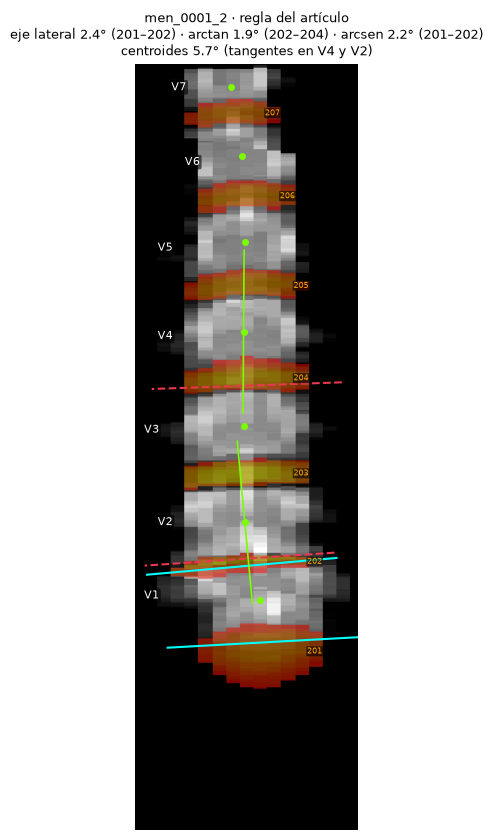

Esta serie tardó 7.4 s. Para 4971 máscaras con 2 proceso(s), la celda 10 tardaría unas 5.1 h (estimación gruesa: el tamaño de las máscaras varía).


In [ ]:
# 9. Prueba en una serie de Mendeley y panel de control de las caras y los centroides
SERIE_PRUEBA = None   # None: la primera serie T1 utilizable de Mendeley según el cuaderno 09; o un id_serie de Mendeley

def proyeccion_coronal(mascara):
    "La proyección del script: vértebras y discos sumados en sentido anteroposterior (cuaderno 05)."
    return ((mascara > 0) & (mascara < 125) & (mascara != CANAL)).sum(1), (mascara > 200).sum(1)

def dibujar_cara(ax, cara, color, estilo="-"):
    "Traza en la proyección coronal la línea del plano de una cara de disco (cuaderno 05)."
    nx, nz, px, pz = cara["nx"], cara["nz"], cara["px"], cara["pz"]
    d = np.array([nz, -nx]) / np.hypot(nx, nz)
    ax.plot([px - 70 * d[0], px + 70 * d[0]], [pz - 70 * d[1], pz + 70 * d[1]], color=color, lw=1.5, ls=estilo)

def rotular_vertebras(ax, mascara, discos=True):
    """Escribe sobre la proyección coronal la etiqueta de SPIDER de cada vértebra (V1 = la más caudal; no es un nivel
    anatómico) y el número de cada disco. Se llama después de invertir el eje (cuaderno 05)."""
    invertido = ax.xaxis_inverted()
    for l in (int(v) for v in np.unique(mascara)):
        es_disco = l > 200
        if l == 0 or l == CANAL or (es_disco and not discos):
            continue
        idx = np.argwhere(mascara == l)
        h, z = idx[:, 0], idx[:, 2]
        izquierda, derecha = (h.max(), h.min()) if invertido else (h.min(), h.max())
        if es_disco:
            ax.text(derecha, np.median(z), str(l), fontsize=6, color="orange", ha="right", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.1", "fc": "black", "ec": "none", "alpha": 0.6})
        else:
            ax.text(izquierda, np.median(z), f"V{l}", fontsize=8, color="white", ha="left", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})

marcas_09 = pd.read_csv(CSV_MARCAS_09, dtype={"estudio": str})
if SERIE_PRUEBA is None:
    utiles = marcas_09[(marcas_09["conjunto"] == "mendeley") & (marcas_09["clase"] == "T1")
                       & (marcas_09["utilizable"].astype(str) == "True")]
    SERIE_PRUEBA = sorted(set(utiles["id_serie"]) & set(indice_mascaras))[0]
assert seleccion.set_index("id_serie").loc[SERIE_PRUEBA, "conjunto"] == "mendeley", "El panel solo se hace con Mendeley"
ruta_prueba = extraer([SERIE_PRUEBA], DIR_LOCAL / "prueba")[0]
caras_p, cent_p, reg_p = procesar(({"id_serie": SERIE_PRUEBA}, str(ruta_prueba), VERSION_SCRIPT, True))
print({k: reg_p[k] for k in ("estado", "n_discos", "estado_centroides", "n_vertebras_centroide", "segundos")})
caras_p, cent_p = pd.DataFrame(caras_p), pd.DataFrame(cent_p)

pares = {col: regla_articulo(tabla_de_caras(caras_p, col)) for col in FORMULAS}
ang_c, v_max, v_min = angulo_por_centroides(cent_p)
mascara_p = en_espacio_del_script(ruta_prueba)
vert, disc = proyeccion_coronal(mascara_p)

fig, ax = plt.subplots(figsize=(6, 8.5))
ax.imshow(vert.T, cmap="gray", origin="lower")
ax.imshow(np.ma.masked_equal(disc.T, 0), cmap="autumn", alpha=0.5, origin="lower")
for col, color, estilo in (("eje_lateral", "cyan", "-"), ("angulo_coronal_script", "#e8384f", "--")):
    a, b = pares[col][1], pares[col][2]
    if not np.isnan(pares[col][0]):
        dibujar_cara(ax, caras_p[(caras_p["disco"] == a) & (caras_p["cara"] == "superior")].iloc[0], color, estilo)
        dibujar_cara(ax, caras_p[(caras_p["disco"] == b) & (caras_p["cara"] == "inferior")].iloc[0], color, estilo)
ax.plot(cent_p["cx"], cent_p["cz"], "o", color="#7CFC00", ms=4)
c = cent_p.set_index("vertebra").sort_index()
for v in (v_max, v_min):
    if not np.isnan(v):
        orden = list(c.index)
        k = orden.index(v)
        d = c.iloc[k + 1][["cx", "cz"]].to_numpy(float) - c.iloc[k - 1][["cx", "cz"]].to_numpy(float)
        d /= np.linalg.norm(d)
        p = c.loc[v, ["cx", "cz"]].to_numpy(float)
        ax.plot([p[0] - 60 * d[0], p[0] + 60 * d[0]], [p[1] - 60 * d[1], p[1] + 60 * d[1]], color="#7CFC00", lw=1.2)
ax.invert_xaxis()
rotular_vertebras(ax, mascara_p)
ax.axis("off")
f = lambda col: f"{pares[col][0]:.1f}° ({pares[col][1]}–{pares[col][2]})" if not np.isnan(pares[col][0]) else "no calculable"
ax.set_title(f"{SERIE_PRUEBA} · regla del artículo\neje lateral {f('eje_lateral')} · arctan {f('angulo_coronal_script')}"
             f" · arcsen {f('arcsen_nx')}\ncentroides {ang_c:.1f}° (tangentes en V{v_min} y V{v_max})", fontsize=9)
plt.tight_layout()
fig.savefig(DIR_SALIDA / f"panel_control_{SERIE_PRUEBA}.png", dpi=120, facecolor="white", bbox_inches="tight")
plt.show()

total = int(seleccion["con_mascara"].sum())
print(f"Esta serie tardó {reg_p['segundos']:.1f} s. Para {total} máscaras con {PROCESOS} proceso(s), la celda 10 tardaría "
      f"unas {reg_p['segundos'] * total / PROCESOS / 3600:.1f} h (estimación gruesa: el tamaño de las máscaras varía).")

**Cómo leer la salida de la celda 9.** La primera línea resume el procesamiento de la serie de prueba. `estado` debe ser `ok`; `n_discos` indica cuántos discos tienen planos calculados y `n_vertebras_centroide` cuántas vértebras tienen un centroide válido.

En el panel, la imagen en escala de grises corresponde a la proyección coronal utilizada por el script, obtenida al sumar las vértebras en sentido anteroposterior. Los discos se superponen en naranja. Cada vértebra está identificada con su etiqueta de SPIDER V1 es la más caudal de la máscara, no un nivel anatómico y cada disco conserva su número, desde el 201. Las líneas cian representan las caras seleccionadas por la regla del artículo con la fórmula del eje lateral proyectado. Las líneas rojas discontinuas muestran las caras seleccionadas con $\arctan(n_x/n_z)$. Si ambas fórmulas eligen el mismo par, las líneas se superponen. Los puntos verdes son los centroides de los cuerpos vertebrales y las rectas verdes representan las tangentes utilizadas por el estimador de centroides.

La imagen está invertida horizontalmente, como en la figura original del script, y se observa desde la espalda del paciente. Por tanto, su derecha anatómica aparece a la derecha de la imagen. La revisión debe comprobar que las caras coincidan con los bordes de los discos, que cada centroide esté dentro del cuerpo vertebral correspondiente y que las etiquetas estén asignadas a la estructura correcta.

La última línea utiliza el tiempo de esta serie para estimar la duración de la celda 10.

In [ ]:
# 10. Planos de las caras y centroides de todas las máscaras de la selección final, por tandas (retoma donde iba)
CSV_CARAS = DIR_PRIV / "planos_por_cara.csv"
CSV_CENTROIDES = DIR_PRIV / "centroides_por_vertebra.csv"
CSV_REGISTRO = DIR_PRIV / "registro_planos.csv"
datos_sel = seleccion.set_index("id_serie")[["conjunto", "estudio", "clase"]]

orden = seleccion[seleccion["con_mascara"]].sort_values(["conjunto", "clase", "id_serie"])["id_serie"].tolist()  # Mendeley primero
hechas = set()
if CSV_REGISTRO.exists():
    reg_previo = pd.read_csv(CSV_REGISTRO, dtype={"id_serie": str, "estudio": str})
    assert (reg_previo["version_script"] == VERSION_SCRIPT).all(), \
        "La corrida empezó con otra versión del script: no se pueden mezclar; revisa la celda 6"
    hechas = set(reg_previo["id_serie"])
pendientes = [i for i in orden if i not in hechas]
print(f"Máscaras: {len(orden)} | hechas: {len(hechas & set(orden))} | pendientes: {len(pendientes)} | versión: {VERSION_SCRIPT}")

def preparar_principal(tanda):
    rutas = extraer(tanda, DIR_LOCAL / "tanda")
    return [({"id_serie": i, **datos_sel.loc[i].to_dict()}, str(r), VERSION_SCRIPT, True) for i, r in zip(tanda, rutas)]

correr_por_tandas(pendientes, preparar_principal, CSV_CARAS, CSV_CENTROIDES, CSV_REGISTRO)

registro = pd.read_csv(CSV_REGISTRO, dtype={"id_serie": str, "estudio": str}).drop_duplicates("id_serie", keep="last")
assert set(orden) <= set(registro["id_serie"]), "Faltan máscaras por procesar: vuelve a correr la celda"
registro["planos"] = registro["estado"] == "ok"
registro["centroides_ok"] = registro["estado_centroides"] == "ok"
resumen_planos = (seleccion.merge(registro[["id_serie", "planos", "centroides_ok", "n_discos", "n_vertebras_centroide",
                                            "segundos"]], on="id_serie", how="left")
                  .groupby(["conjunto", "clase"])
                  .agg(series=("id_serie", "size"), sin_mascara=("con_mascara", lambda x: int((~x).sum())),
                       con_planos=("planos", lambda x: int(x.astype("boolean").fillna(False).sum())),
                       con_centroides=("centroides_ok", lambda x: int(x.astype("boolean").fillna(False).sum())),
                       discos_mediana=("n_discos", "median"), vertebras_mediana=("n_vertebras_centroide", "median"),
                       segundos_mediana=("segundos", "median")))
resumen_planos.to_csv(DIR_SALIDA / "planos_resumen.csv")
display(resumen_planos)
print("Estados del script:", registro["estado"].value_counts().to_dict())
print("Estados de los centroides:", registro["estado_centroides"].fillna("").astype(str).str.split(":").str[0]
      .value_counts().to_dict())
errores = (registro.loc[registro["estado"] == "error", "error"].fillna("").astype(str).str.split(":").str[0]
           .value_counts())
print("Errores del script por tipo:", errores.to_dict() if len(errores) else "ninguno")

Máscaras: 4971 | hechas: 4971 | pendientes: 0 | versión: caja


series  sin_mascara  con_planos  con_centroides  \
conjunto clase                                                    
mendeley T1        515            0         515             515   
         T2        515            5         510             510   
rsna     T1       1973            1        1972            1972   
         T2       1974            0        1974            1974   

                discos_mediana  vertebras_mediana  segundos_mediana  
conjunto clase                                                       
mendeley T1                7.0                7.0             7.800  
         T2                7.0                7.0             7.870  
rsna     T1                7.0                7.0             9.835  
         T2                7.0                7.0             9.345

Estados del script: {'ok': 4971}
Estados de los centroides: {'ok': 4971}
Errores del script por tipo: ninguno


**Cómo leer la salida de la celda 10.** Durante el procesamiento, cada línea corresponde a una tanda e informa cuántas máscaras quedaron sin planos y cuánto tiempo se estima que falta. Si Colab se interrumpe, al ejecutar de nuevo el cuaderno se reconocen las máscaras ya procesadas y se continúa con las pendientes.

La tabla final resume los resultados por conjunto y secuencia. `series` es el número de series de la selección final; `sin_mascara` cuenta las que no tienen máscara de TotalSpineSeg, que se esperan en cinco series de Mendeley y una de RSNA. `con_planos` indica cuántas máscaras produjeron planos y `con_centroides` cuántas permitieron aislar al menos un cuerpo vertebral. Las medianas del número de discos y vértebras describen la cobertura anatómica de las máscaras, mientras que la mediana de segundos resume el tiempo de procesamiento por máscara.

Las líneas finales agrupan los estados del script y del cálculo de centroides, además de los errores por tipo, sin mostrar identificadores individuales. Los planos, centroides y registros por serie se conservan en la carpeta privada de Drive y constituyen la entrada de los análisis siguientes.

## Entradas de los análisis

A partir de este punto el cuaderno ya no vuelve a ejecutar el script. Los análisis utilizan las tablas generadas por la celda 10 y los inventarios preparados en los cuadernos anteriores. Por eso, cada análisis posterior requiere mucho menos tiempo de cálculo. La celda 11 carga y organiza esas entradas.

Del cuaderno 09 se recuperan la posición física y el contacto con los bordes de cada estructura, la traducción de las etiquetas de TotalSpineSeg a la numeración de SPIDER, la geometría de las máscaras, la numeración T1–T2 por estudio, las marcas de calidad, la coincidencia con los niveles de RSNA y la huella de protocolo de RSNA. Del cuaderno 08 se utilizan las notas de los radiólogos de Mendeley, la conversión de sus series y el inventario con sexo, edad y grosor de corte. Para RSNA también se incorpora el inventario de imágenes del cuaderno 08, que contiene el grosor de corte de cada serie.

| Archivo | Ruta en Google Drive |
|---|---|
| `etiquetas_por_mascara.csv`, `traduccion_etiquetas.csv`, `registro_recorrido.csv`, `numeracion_t1_t2_por_estudio.csv`, `niveles_rsna_por_serie.csv` y `rsna_huella_protocolo_por_serie.csv` del cuaderno 09 | `MyDrive/PRL/content/datos/analisis_09/` |
| `imagenes_rsna.csv.gz` del cuaderno 08 | `MyDrive/PRL/content/datos/rsna/inventario/` |
| `mendeley_notas_Sheet1.csv`, `mendeley_menciones_escoliosis.csv`, `conversion_mendeley.csv` y `mendeley_inventario/series_mendeley.csv` del cuaderno 08 | `MyDrive/PRL/salidas/resultados_semana4/08_rsna_y_mendeley/` |

In [ ]:
# 11. Entradas de los análisis: planos y centroides de la celda 10, tablas del cuaderno 09 y tablas del cuaderno 08
from scipy import stats
CSV_ETIQUETAS_09 = DIR_PRIV_09 / "etiquetas_por_mascara.csv"
CSV_TRADUCCION_09 = DIR_PRIV_09 / "traduccion_etiquetas.csv"
CSV_RECORRIDO_09 = DIR_PRIV_09 / "registro_recorrido.csv"
CSV_NUMERACION_09 = DIR_PRIV_09 / "numeracion_t1_t2_por_estudio.csv"
CSV_NIVELES_09 = DIR_PRIV_09 / "niveles_rsna_por_serie.csv"
CSV_HUELLA_RSNA_09 = DIR_PRIV_09 / "rsna_huella_protocolo_por_serie.csv"
CSV_IMAGENES_RSNA = DIR_DATOS / "rsna" / "inventario" / "imagenes_rsna.csv.gz"
DIR_SALIDA_08 = SALIDAS / "resultados_semana4" / "08_rsna_y_mendeley"
CSV_NOTAS_MENDELEY = DIR_SALIDA_08 / "mendeley_notas_Sheet1.csv"
CSV_MENCIONES_MENDELEY = DIR_SALIDA_08 / "mendeley_menciones_escoliosis.csv"
CSV_CONVERSION_MENDELEY = DIR_SALIDA_08 / "conversion_mendeley.csv"
CSV_SERIES_MENDELEY = DIR_SALIDA_08 / "mendeley_inventario" / "series_mendeley.csv"
for archivo in (CSV_CARAS, CSV_CENTROIDES, CSV_REGISTRO, CSV_ETIQUETAS_09, CSV_TRADUCCION_09, CSV_RECORRIDO_09,
                CSV_NUMERACION_09, CSV_NIVELES_09, CSV_HUELLA_RSNA_09, CSV_IMAGENES_RSNA, CSV_NOTAS_MENDELEY,
                CSV_MENCIONES_MENDELEY, CSV_CONVERSION_MENDELEY, CSV_SERIES_MENDELEY):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de entradas"

TIPOS = {"id_serie": str, "estudio": str, "serie_clave": str, "paciente": str}
def leer(ruta, **kw):
    return pd.read_csv(ruta, dtype=TIPOS, **kw)

def es_verdadero(serie):
    "Columnas booleanas leídas de un CSV (pueden venir como bool, texto o vacías): True solo si dice True."
    return serie.astype(str).eq("True")

CONJUNTOS = {"mendeley": "Mendeley", "rsna": "RSNA"}
F_CORTO = {"eje_lateral": "eje_lateral", "arctan": "angulo_coronal_script", "arcsen": "arcsen_nx"}   # nombre corto: columna
NOMBRE_F = {"eje_lateral": "eje lateral proyectado", "arctan": "arctan(nx/nz)", "arcsen": "arcsen(nx)"}
PRINCIPAL = "eje_lateral"
SUBCONJUNTOS = {"completo": "conjunto completo", "sin_marcas": "estudios sin marcas"}
# Nombres de los discos de TotalSpineSeg (cuaderno 09), para nombrar el nivel de cada cara
NOMBRE_DISCO_TSS = {**{63 + k: f"C{k + 2}-C{k + 3}" for k in range(5)}, 71: "C7-T1",
                    **{72 + k: f"T{k + 1}-T{k + 2}" for k in range(11)}, 91: "T12-L1",
                    **{92 + k: f"L{k + 1}-L{k + 2}" for k in range(4)}, 96: "L5-L6", 100: "L5-S"}

caras = leer(CSV_CARAS).drop_duplicates(["id_serie", "disco", "cara"], keep="last")
centroides = leer(CSV_CENTROIDES).drop_duplicates(["id_serie", "vertebra"], keep="last")
etiquetas_09 = leer(CSV_ETIQUETAS_09).drop_duplicates(["id_serie", "etiqueta"], keep="last")
traduccion_09 = leer(CSV_TRADUCCION_09).drop_duplicates(["id_serie", "etiqueta_original"], keep="last")
recorrido_09 = leer(CSV_RECORRIDO_09).drop_duplicates("id_serie", keep="last").set_index("id_serie")
numeracion_09 = leer(CSV_NUMERACION_09)
marcas_09 = leer(CSV_MARCAS_09)
huella_rsna = leer(CSV_HUELLA_RSNA_09, index_col=0)
seleccion_ids = set(seleccion["id_serie"])
assert set(caras["id_serie"]) <= seleccion_ids, "Hay planos de series que no están en la selección final"
print(f"Caras: {len(caras)} de {caras['id_serie'].nunique()} series | vértebras con centroide: {len(centroides)} "
      f"de {centroides['id_serie'].nunique()} series")
print(f"Estudios por conjunto: {seleccion.groupby('conjunto')['estudio'].nunique().to_dict()}")

Caras: 71848 de 4971 series | vértebras con centroide: 35339 de 4971 series
Estudios por conjunto: {'mendeley': 515, 'rsna': 1975}


## Ángulo de cada serie

La celda 12 calcula para cada serie el ángulo mediante la regla del artículo y las tres fórmulas de la normal, utilizando sin modificaciones las funciones del cuaderno 07. Para cada fórmula se guarda el ángulo máximo entre todos los pares de discos, el par que produce ese máximo y la mayor inclinación sagital de las dos caras seleccionadas. Esta última variable se utiliza en las marcas de calidad. También se conserva el ángulo con signo, calculado como la inclinación de la cara craneal menos la de la cara caudal. El estimador de centroides se calcula por separado y recibe un signo equivalente, definido por la diferencia entre las tangentes más craneal y más caudal.

El signo se utiliza únicamente en el análisis 6, para comparar la convexidad estimada con el lado descrito en los informes de Mendeley. Según la geometría, un valor positivo debe corresponder a una convexidad hacia la derecha del paciente. En el sistema LPS de DICOM, que también utiliza el espacio del script, el eje $x$ aumenta hacia la izquierda del paciente. En una curva convexa hacia la derecha, la columna se desplaza hacia $-x$ al ascender desde el extremo caudal y vuelve hacia $+x$ al llegar al extremo craneal. Por eso la cara caudal queda inclinada en sentido negativo y la craneal en sentido positivo; al restarlas, el resultado es positivo.

La celda 13 verifica esta convención con columnas sintéticas cuya convexidad se conoce y con dos orientaciones distintas de los cortes sagitales. La comprobación permite verificar que el signo depende de la posición física y no del orden en que se almacenaron los cortes.

In [ ]:
# 12. Ángulo de cada serie: regla del artículo con las tres fórmulas, par elegido, signo y ángulo por centroides
def angulo_de_serie(c, columna):
    "Regla del artículo (cuaderno 07) con la inclinación `columna`; con signo = cara craneal − cara caudal del par."
    tabla = tabla_de_caras(c, columna)
    angulo, a, b = regla_articulo(tabla)
    if np.isnan(angulo):
        return {"angulo": np.nan, "con_signo": np.nan, "disco_caudal": np.nan, "disco_craneal": np.nan,
                "incl_sag_par": np.nan}
    sag = c.set_index(["disco", "cara"])["inclinacion_sagital"]
    return {"angulo": angulo, "con_signo": float(tabla.loc[b, "inferior"] - tabla.loc[a, "superior"]),
            "disco_caudal": a, "disco_craneal": b,
            "incl_sag_par": float(max(abs(sag[(a, "superior")]), abs(sag[(b, "inferior")])))}

def centroides_con_signo(cent):
    "Estimador registrado (celda 7); con signo = tangente craneal − tangente caudal."
    angulo, v_max, v_min = angulo_por_centroides(cent)
    if np.isnan(angulo):
        return np.nan, np.nan
    return angulo, (angulo if v_max > v_min else -angulo)

filas = []
cent_de = dict(tuple(centroides.groupby("id_serie")))
for i, c in caras.groupby("id_serie"):
    fila = {"id_serie": i, "n_discos": int(c["disco"].nunique())}
    for corto, columna in F_CORTO.items():
        fila.update({f"{k}_{corto}": v for k, v in angulo_de_serie(c, columna).items()})
    cent = cent_de.get(i, pd.DataFrame(columns=["vertebra"]))
    fila["n_vertebras"] = len(cent)
    fila["angulo_centroides"], fila["con_signo_centroides"] = centroides_con_signo(cent) if len(cent) else (np.nan, np.nan)
    filas.append(fila)
angulos = seleccion[["id_serie", "conjunto", "estudio", "clase", "serie_clave"]].merge(pd.DataFrame(filas), on="id_serie",
                                                                                     how="left")
angulos.to_csv(DIR_PRIV / "angulos_por_serie.csv", index=False)
angulos[angulos["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "angulos_por_serie_mendeley.csv", index=False)   # CC BY
disponibles = angulos.groupby(["conjunto", "clase"]).agg(
    series=("id_serie", "size"), con_angulo=("angulo_eje_lateral", "count"), con_angulo_centroides=("angulo_centroides", "count"),
    discos_mediana=("n_discos", "median"), vertebras_mediana=("n_vertebras", "median"))
disponibles.to_csv(DIR_SALIDA / "angulos_disponibles.csv")
display(disponibles)

series  con_angulo  con_angulo_centroides  discos_mediana  \
conjunto clase                                                              
mendeley T1        515         515                    515             7.0   
         T2        515         510                    508             7.0   
rsna     T1       1973        1972                   1972             7.0   
         T2       1974        1974                   1974             7.0   

                vertebras_mediana  
conjunto clase                     
mendeley T1                   7.0  
         T2                   7.0  
rsna     T1                   7.0  
         T2                   7.0

**Cómo leer la salida de la celda 12.** La tabla resume, por conjunto y secuencia, cuántas series tienen un ángulo calculable mediante las caras de los discos y cuántas mediante los centroides. El estimador por caras requiere al menos dos discos; el de centroides necesita al menos cuatro vértebras con el cuerpo aislado. Por esa diferencia, una serie puede tener ángulo por caras y no tenerlo por centroides.

Las series sin máscara se contabilizan en la columna `series`, pero no aparecen entre las series con ángulo. En esta etapa todavía no se presentan los valores de los ángulos. Las tablas individuales se conservan en la carpeta privada; la tabla de Mendeley también se incluye en la carpeta de resultados.

In [ ]:
# 13. Comprobación del signo con columnas sintéticas de lado conocido, en dos orientaciones de imagen
import SimpleITK as sitk

def columna_sintetica(direccion, amplitud_mm):
    """Máscara sintética en la numeración de SPIDER (vértebras 1–6, discos 201–205, canal 100) a lo largo de la curva
    coronal x(z) = −A·sen(π(z + 100)/200). Con A > 0 el vértice queda hacia −x, la derecha del paciente en LPS.
    Cada vértebra y cada disco es una placa elíptica perpendicular a la curva. direccion: matriz de dirección (3 × 3)."""
    esp, tam = np.array([0.7, 0.7, 4.0]), np.array([200, 330, 31])
    D = np.array(direccion, dtype=float).reshape(3, 3)
    centro = (tam - 1) / 2 * esp
    I, J, K = np.meshgrid(*(np.arange(n) for n in tam), indexing="ij")
    P = (np.stack([I, J, K], -1).reshape(-1, 3) * esp - centro) @ D.T          # punto físico (LPS) de cada vóxel
    curva = lambda z: -amplitud_mm * np.sin(np.pi * (z + 100) / 200)
    pendiente = lambda z: -amplitud_mm * np.pi / 200 * np.cos(np.pi * (z + 100) / 200)
    etiqueta = np.zeros(len(P), np.uint16)
    for k in range(11):                                   # vértebra, disco, vértebra, ... de caudal a craneal
        zc = -85 + 16 * k
        phi = np.arctan(pendiente(zc))
        n, u = np.array([np.sin(phi), 0, np.cos(phi)]), np.array([np.cos(phi), 0, -np.sin(phi)])
        q = P - np.array([curva(zc), 0.0, zc])
        mitad = 12.0 if k % 2 == 0 else 4.0
        dentro = (np.abs(q @ n) <= mitad) & (((q @ u) / 22) ** 2 + (q[:, 1] / 16) ** 2 <= 1)
        etiqueta[dentro] = k // 2 + 1 if k % 2 == 0 else 201 + k // 2
    canal = ((P[:, 0] - curva(P[:, 2])) ** 2 / 36 + (P[:, 1] - 30) ** 2 / 25 <= 1) & (np.abs(P[:, 2] + 5) < 100)
    etiqueta[canal & (etiqueta == 0)] = 100
    img = sitk.GetImageFromArray(np.transpose(etiqueta.reshape(tam), (2, 1, 0)))
    img.SetSpacing(tuple(esp)); img.SetDirection(tuple(D.ravel())); img.SetOrigin(tuple(-(centro @ D.T)))
    return img

ORIENTACIONES = {"cortes hacia +x": [0, 0, 1, 1, 0, 0, 0, -1, 0], "cortes hacia −x": [0, 0, -1, 1, 0, 0, 0, -1, 0]}
DIR_SIGNO = DIR_LOCAL / "signo"
DIR_SIGNO.mkdir(parents=True, exist_ok=True)
filas = []
for nombre, D in ORIENTACIONES.items():
    for lado, amplitud in (("derecha", 20.0), ("izquierda", -20.0)):
        ruta = DIR_SIGNO / f"sintetica_{len(filas)}.mha"
        sitk.WriteImage(columna_sintetica(D, amplitud), str(ruta), useCompression=True)
        c, cent, reg = procesar(({"id_serie": ruta.stem}, str(ruta), VERSION_SCRIPT, True))
        c, cent = pd.DataFrame(c), pd.DataFrame(cent)
        fila = {"orientacion": nombre, "convexidad_real": lado}
        for corto, columna in F_CORTO.items():
            fila[f"con_signo_{corto}"] = angulo_de_serie(c, columna)["con_signo"]
        fila["con_signo_centroides"] = centroides_con_signo(cent)[1]
        filas.append(fila)
signo = pd.DataFrame(filas)
esperado = np.where(signo["convexidad_real"] == "derecha", 1, -1)
columnas_signo = [c for c in signo if c.startswith("con_signo_")]
signo["signo_correcto"] = (np.sign(signo[columnas_signo].to_numpy(float)) == esperado[:, None]).all(axis=1)
signo.to_csv(DIR_SALIDA / "comprobacion_signo.csv", index=False)
display(signo.round(2))
assert signo["signo_correcto"].all(), "El signo no corresponde al lado de la convexidad: no usar el signo en el análisis 6"
print("Convención comprobada: ángulo con signo positivo = convexidad hacia la derecha del paciente.")

def lado_del_signo(v):
    return np.where(np.isnan(v), None, np.where(v > 0, "derecha", "izquierda"))

,orientacion,convexidad_real,con_signo_eje_lateral,con_signo_arctan,con_signo_arcsen,con_signo_centroides,signo_correcto
0,cortes hacia +x,derecha,27.43,27.43,27.43,24.33,True
1,cortes hacia +x,izquierda,-27.43,-27.43,-27.43,-24.33,True
2,cortes hacia −x,derecha,27.43,27.43,27.43,24.33,True
3,cortes hacia −x,izquierda,-27.43,-27.43,-27.43,-24.33,True


Convención comprobada: ángulo con signo positivo = convexidad hacia la derecha del paciente.


**Cómo leer la salida de la celda 13.** Cada fila representa una columna sintética con una curva de convexidad conocida, con unos 14° de inclinación en cada extremo (unos 27° de ángulo total). Se generan dos orientaciones de imagen: en una, el índice de los cortes sagitales aumenta hacia la izquierda del paciente; en la otra, aumenta hacia la derecha.

Las columnas `con_signo_*` muestran los ángulos con signo calculados por el procedimiento real: el script con la versión seleccionada, la regla del artículo y el estimador de centroides. `signo_correcto` debe ser verdadero en las cuatro combinaciones. Para ambas orientaciones, la convexidad hacia la derecha debe producir valores positivos y la convexidad hacia la izquierda, valores negativos. Así se comprueba que el signo se conserva aunque cambie el orden de los cortes en el archivo.

La prueba presupone que la conversión del cuaderno 08 conservó la orientación original de cada serie. En RSNA esto se contrastó con las cabeceras DICOM en el cuaderno 09. En Mendeley, las imágenes se convirtieron de DICOM a NIfTI y no se dispone de una referencia externa independiente del lado; por eso la interpretación del signo en ese conjunto debe considerarse con esa reserva.

## Marcas de calidad

El plan define seis marcas que se registran, pero no se utilizan para excluir series del conjunto completo. Son las siguientes: máscara no utilizable según el cuaderno 09; menos de seis discos; inclinación sagital superior a 30° en alguna de las caras del par elegido; presencia de algún disco del par en el borde lateral o craneal del campo; numeración lumbar distinta entre T1 y T2 del mismo estudio; y presencia de una sexta vértebra lumbar en cualquiera de las dos máscaras.

Un estudio queda marcado si cualquiera de sus dos series presenta al menos una de estas condiciones. El subconjunto «sin marcas» está formado por los estudios que no presentan ninguna. De este modo, las comparaciones entre secuencias se realizan sobre el mismo grupo de estudios, independientemente de que se analice T1 o T2.

El plan no especifica cómo resolver las marcas que dependen del par de discos elegido, porque ese par puede variar entre fórmulas. Para evitar que el subconjunto sin marcas cambie según la fórmula, las marcas de inclinación sagital y de contacto con el borde se calculan con los pares seleccionados por las tres fórmulas. Una serie queda marcada si cualquiera de esos pares cumple la condición. La posición del borde procede del cuaderno 09, que identificó las estructuras de TotalSpineSeg que tocaban los bordes lateral o craneal de la imagen original; después se trasladó esa información a la numeración de SPIDER mediante la tabla de correspondencias del mismo cuaderno.

In [ ]:
# 14. Marcas de calidad del plan, por serie y por estudio (se marcan, no se excluyen)
tr_discos = traduccion_09[traduccion_09["tipo"] == "disco"][["id_serie", "etiqueta_original", "etiqueta_spider"]]
borde = tr_discos.merge(etiquetas_09[["id_serie", "etiqueta", "toca_borde_lateral", "toca_borde_craneal"]],
                        left_on=["id_serie", "etiqueta_original"], right_on=["id_serie", "etiqueta"])
borde = borde[es_verdadero(borde["toca_borde_lateral"]) | es_verdadero(borde["toca_borde_craneal"])]
discos_en_borde = borde.groupby("id_serie")["etiqueta_spider"].agg(lambda s: set(int(v) for v in s))
con_l6 = set(etiquetas_09.loc[etiquetas_09["etiqueta"] == 46, "id_serie"])

def discos_de_los_pares(r):
    return {int(r[f"{k}_{f}"]) for f in F_CORTO for k in ("disco_caudal", "disco_craneal") if pd.notna(r[f"{k}_{f}"])}

utilizable_09 = marcas_09.set_index("id_serie")["utilizable"].astype(str).eq("True")
ms = angulos[["id_serie", "conjunto", "estudio", "clase"]].copy()
ms["no_utilizable"] = ~ms["id_serie"].map(utilizable_09).astype("boolean").fillna(False).astype(bool)
ms["menos_de_seis_discos"] = angulos["n_discos"].fillna(0) < MIN_DISCOS
ms["inclinacion_sagital_mayor_30"] = (angulos[[f"incl_sag_par_{f}" for f in F_CORTO]].max(axis=1) > UMBRAL_INCLINACION_SAGITAL)
ms["disco_del_par_en_borde"] = [bool(discos_de_los_pares(r) & discos_en_borde.get(r["id_serie"], set()))
                                for _, r in angulos.iterrows()]
ms["sexta_lumbar"] = ms["id_serie"].isin(con_l6)
MARCAS_SERIE = ["no_utilizable", "menos_de_seis_discos", "inclinacion_sagital_mayor_30", "disco_del_par_en_borde", "sexta_lumbar"]
ms.to_csv(DIR_PRIV / "marcas_por_serie.csv", index=False)

estudios = ms.groupby(["conjunto", "estudio"])[MARCAS_SERIE].any()
misma = numeracion_09.set_index(["conjunto", "estudio"])["misma_numeracion"].astype(str)
estudios["numeracion_t1_t2_distinta"] = misma.reindex(estudios.index).eq("False")
MARCAS_ESTUDIO = MARCAS_SERIE + ["numeracion_t1_t2_distinta"]
estudios["alguna_marca"] = estudios[MARCAS_ESTUDIO].any(axis=1)
estudios.to_csv(DIR_PRIV / "marcas_por_estudio.csv")
estudios.loc["mendeley"].to_csv(DIR_SALIDA / "marcas_por_estudio_mendeley.csv")    # CC BY
sin_marcas = set(estudios.index[~estudios["alguna_marca"]])

resumen_marcas = estudios.groupby(level="conjunto").agg(
    estudios=("alguna_marca", "size"),
    **{f"{m}_pct": (m, lambda x: round(100 * x.mean(), 1)) for m in MARCAS_ESTUDIO},
    estudios_sin_marcas=("alguna_marca", lambda x: int((~x).sum())))
resumen_marcas.to_csv(DIR_SALIDA / "marcas_resumen.csv")
display(resumen_marcas.T)

conjunto,mendeley,rsna
estudios,515.0,1975.0
no_utilizable_pct,7.2,11.9
menos_de_seis_discos_pct,1.6,0.1
inclinacion_sagital_mayor_30_pct,23.9,25.6
disco_del_par_en_borde_pct,7.4,10.4
sexta_lumbar_pct,0.4,0.6
numeracion_t1_t2_distinta_pct,0.8,1.3
estudios_sin_marcas,349.0,1237.0


**Cómo leer la salida de la celda 14.** La tabla está organizada con una columna para cada conjunto. Cada fila indica el porcentaje de estudios en los que aparece la marca correspondiente en al menos una de las dos series. La última fila cuenta los estudios sin ninguna marca; estos conforman el subconjunto utilizado en los análisis «sin marcas».

Los porcentajes no tienen por qué sumar 100 %, porque un mismo estudio puede presentar varias marcas. La marca de máscara no utilizable incluye tanto las series sin máscara como la T2 cervical del estudio 0245 de Mendeley, de acuerdo con lo establecido en el plan.

## Funciones estadísticas

La celda 15 define las medidas de acuerdo del análisis 1 y verifica el cálculo del ICC. Para cada estudio se calcula $d=\text{T2}-\text{T1}$. El sesgo corresponde a la media de esas diferencias. Los límites de acuerdo se calculan como el sesgo más o menos 1,96 desviaciones estándar de $d$, y su ancho es $2\times1{,}96\times\mathrm{DE}(d)$.

El coeficiente de repetibilidad sigue la formulación de Bland y Altman (1999), $1{,}96\sqrt{2}\,s_w$, donde $s_w^2=\sum d^2/(2n)$ representa la varianza dentro del sujeto cuando hay dos mediciones. Esta expresión también puede escribirse como $1{,}96\sqrt{\sum d^2/n}$ y, a diferencia de la desviación estándar de las diferencias centradas, incorpora el sesgo si existe.

El ICC(A,1) corresponde al modelo de dos vías, acuerdo absoluto y una sola medición de McGraw y Wong (1996):

$$\mathrm{ICC(A,1)}=\frac{MS_R-MS_E}{MS_R+(k-1)MS_E+\frac{k}{n}(MS_C-MS_E)},$$

donde $n$ es el número de estudios, $k=2$ el número de secuencias y $MS_R$, $MS_C$ y $MS_E$ son las medias cuadráticas de filas, columnas y error de un ANOVA de dos vías. Antes de utilizarlo, el cálculo se contrasta con el ejemplo publicado por Shrout y Fleiss (1979), de seis sujetos y cuatro evaluadores, cuyo ICC de esta forma es 0,29. También se compara con la librería `pingouin` tanto en ese ejemplo como en un conjunto simulado.

Los intervalos de confianza de las medidas de acuerdo se obtienen mediante 2.000 remuestreos de estudios, con semilla 2026 y percentiles 2,5 y 97,5. Dentro de cada conjunto se utilizan los mismos remuestreos para las tres fórmulas, de modo que las diferencias entre ellas se calculan sobre los mismos estudios. Las proporciones se acompañan de intervalos exactos de Clopper–Pearson.

**Referencias:** Bland JM, Altman DG. *Measuring agreement in method comparison studies.* Stat Methods Med Res 1999;8:135–160, [doi:10.1177/096228029900800204](https://doi.org/10.1177/096228029900800204). McGraw KO, Wong SP. *Forming inferences about some intraclass correlation coefficients.* Psychol Methods 1996;1:30–46, [doi:10.1037/1082-989X.1.1.30](https://doi.org/10.1037/1082-989X.1.1.30). Shrout PE, Fleiss JL. *Intraclass correlations: uses in assessing rater reliability.* Psychol Bull 1979;86:420–428, [doi:10.1037/0033-2909.86.2.420](https://doi.org/10.1037/0033-2909.86.2.420).

In [ ]:
# 15. Medidas de acuerdo, ICC(A,1) verificado, remuestreo de estudios y Clopper–Pearson
import pingouin as pg

def icc_a1(Y):
    """ICC(A,1) de McGraw y Wong (1996): dos vías, acuerdo absoluto, una medición. Y: (..., n, k)."""
    Y = np.asarray(Y, dtype=float)
    n, k = Y.shape[-2], Y.shape[-1]
    m = Y.mean(axis=(-2, -1), keepdims=True)
    ssr = k * ((Y.mean(axis=-1, keepdims=True) - m) ** 2).sum(axis=(-2, -1))
    ssc = n * ((Y.mean(axis=-2, keepdims=True) - m) ** 2).sum(axis=(-2, -1))
    sse = ((Y - m) ** 2).sum(axis=(-2, -1)) - ssr - ssc
    msr, msc, mse = ssr / (n - 1), ssc / (k - 1), sse / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

def icc_pingouin(Y):
    largo = pd.DataFrame([(i, j, Y[i, j]) for i in range(Y.shape[0]) for j in range(Y.shape[1])],
                         columns=["sujeto", "evaluador", "valor"])
    t = pg.intraclass_corr(largo, "sujeto", "evaluador", "valor").set_index("Type")["ICC"]
    return float(t["ICC(A,1)"] if "ICC(A,1)" in t else t["ICC2"])     # el nombre cambia según la versión

SHROUT_FLEISS = np.array([[9, 2, 5, 8], [6, 1, 3, 2], [8, 4, 6, 8], [7, 1, 2, 6], [10, 5, 6, 9], [6, 2, 4, 7]])
simulado = np.random.default_rng(SEMILLA).normal(size=(200, 2))
simulado[:, 1] = simulado[:, 0] + 0.5 * simulado[:, 1] + 0.3
verificacion_icc = pd.DataFrame([
    {"caso": "Shrout y Fleiss (1979), publicado 0,29", "este_cuaderno": icc_a1(SHROUT_FLEISS), "pingouin": icc_pingouin(SHROUT_FLEISS)},
    {"caso": "simulado, 200 sujetos y 2 mediciones con sesgo", "este_cuaderno": icc_a1(simulado), "pingouin": icc_pingouin(simulado)}])
display(verificacion_icc.round(6))
assert round(icc_a1(SHROUT_FLEISS), 2) == 0.29, "El ICC(A,1) no reproduce el valor publicado"
assert np.allclose(verificacion_icc["este_cuaderno"], verificacion_icc["pingouin"], atol=1e-9), "El ICC(A,1) no coincide con pingouin"
print(f"ICC(A,1) verificado (pingouin {pg.__version__}).")

def medidas_de_acuerdo(t1, t2):
    "Medidas del análisis 1; t1, t2 con forma (..., n). Cada valor tiene la forma (...)."
    d = t2 - t1
    sesgo, de = d.mean(axis=-1), d.std(axis=-1, ddof=1)
    return {"sesgo": sesgo, "lim_inf": sesgo - 1.96 * de, "lim_sup": sesgo + 1.96 * de, "ancho_limites": 2 * 1.96 * de,
            "coef_repetibilidad": 1.96 * np.sqrt((d ** 2).mean(axis=-1)), "icc_a1": icc_a1(np.stack([t1, t2], axis=-1))}

def indices_bootstrap(n):
    "Los mismos 2.000 remuestreos de estudios para todo lo que se compare dentro de un grupo (semilla 2026)."
    return np.random.default_rng(SEMILLA).integers(0, n, size=(B_BOOTSTRAP, n))

def ic95(valores):
    return np.percentile(valores, [2.5, 97.5])

def clopper_pearson(k, n):
    if n == 0:
        return np.nan, np.nan
    r = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="exact")
    return r.low, r.high

def proporcion(mascara):
    "Porcentaje con IC 95 % de Clopper–Pearson, a partir de un arreglo booleano."
    k, n = int(np.sum(mascara)), len(mascara)
    lo, hi = clopper_pearson(k, n)
    return {"k": k, "n": n, "pct": 100 * k / n if n else np.nan, "ic95_inf_pct": 100 * lo, "ic95_sup_pct": 100 * hi}

# Tabla ancha: una fila por estudio con los ángulos de la T1 y de la T2 y sus marcas
COLUMNAS_ANGULO = [f"{p}_{f}" for f in F_CORTO for p in ("angulo", "con_signo", "incl_sag_par")] + \
                  ["angulo_centroides", "con_signo_centroides", "n_discos"]
ancho = angulos.set_index(["conjunto", "estudio", "clase"])[COLUMNAS_ANGULO + ["id_serie"]].unstack("clase")
ancho.columns = [f"{c}_{clase}" for c, clase in ancho.columns]
ancho = ancho.join(estudios)

def grupo(conjunto, subconjunto, columnas):
    "Estudios del conjunto con todas las columnas indicadas, en el subconjunto pedido."
    t = ancho.loc[conjunto].dropna(subset=columnas)
    if subconjunto == "sin_marcas":
        t = t[~t["alguna_marca"].astype(bool)]
    return t

PARES_ANGULO = [f"angulo_{f}_{c}" for f in F_CORTO for c in ("T1", "T2")]
print("Estudios con el ángulo de las tres fórmulas en la T1 y la T2:",
      {f"{CONJUNTOS[c]} {s}": len(grupo(c, s, PARES_ANGULO)) for c in CONJUNTOS for s in SUBCONJUNTOS})

,caso,este_cuaderno,pingouin
0,"Shrout y Fleiss (1979), publicado 0,29",0.289764,0.289764
1,"simulado, 200 sujetos y 2 mediciones con sesgo",0.838385,0.838385


ICC(A,1) verificado (pingouin 0.7.0).
Estudios con el ángulo de las tres fórmulas en la T1 y la T2: {'Mendeley completo': 510, 'Mendeley sin_marcas': 349, 'RSNA completo': 1971, 'RSNA sin_marcas': 1235}


**Cómo leer la salida de la celda 15.** La tabla compara el ICC(A,1) calculado en este cuaderno con el obtenido mediante `pingouin` en dos situaciones. En el ejemplo de Shrout y Fleiss ambos procedimientos deben producir 0,2898, que redondea al 0,29 publicado. En el conjunto simulado también deben coincidir. Si alguna comprobación falla, la celda se detiene para evitar continuar con una implementación no verificada.

La última línea informa, por conjunto y subconjunto, cuántos estudios tienen un ángulo calculable con las tres fórmulas en ambas secuencias. Este es el grupo de estudios que entra en los análisis 1 y 3.

## Análisis registrados

### Análisis 1 · Acuerdo T1–T2 del mismo estudio

Las secuencias T1 y T2 de un mismo estudio se adquieren durante la misma sesión y comparten el sistema de coordenadas del equipo. Por ello, la diferencia entre sus ángulos permite estudiar cuánto varía la medida entre secuencias dentro de un mismo estudio. No representa todo el error del procedimiento, porque ambas secuencias también comparten factores como el paciente, la sesión y el segmentador.

La celda 16 calcula, para cada conjunto, subconjunto y fórmula, el sesgo, los límites de acuerdo, el ancho de esos límites, el coeficiente de repetibilidad y el ICC(A,1), todos con sus intervalos de confianza.

La hipótesis registrada H1 establece que la fórmula del eje lateral proyectado produce límites de acuerdo más estrechos que $\arctan(n_x/n_z)$. Se considera respaldada en un conjunto cuando el intervalo de confianza del 95 % para la diferencia de anchos es decir el eje lateral menos arctan queda completamente por debajo de cero. La hipótesis se evalúa por separado en Mendeley y RSNA. Si se cumple en uno solo, el resultado conjunto se clasifica como mixto. También se informa el tamaño de la diferencia. La fórmula $\arcsin(n_x)$ se presenta como referencia, pero no sustituye a la fórmula principal si H1 no se cumple.

,conjunto,subconjunto,formula,estudios,sesgo,lim_inf,lim_sup,ancho_limites,ancho_limites_ic95_inf,ancho_limites_ic95_sup,coef_repetibilidad,icc_a1,icc_a1_ic95_inf,icc_a1_ic95_sup
0,Mendeley,completo,eje lateral proyectado,510,-0.007,-1.647,1.632,3.279,2.958,3.631,1.638,0.956,0.930,0.971
1,Mendeley,completo,arctan(nx/nz),510,-0.017,-1.745,1.710,3.455,3.113,3.820,1.726,0.959,0.938,0.972
2,Mendeley,completo,arcsen(nx),510,-0.012,-1.680,1.656,3.336,3.005,3.688,1.666,0.958,0.934,0.972
3,Mendeley,sin_marcas,eje lateral proyectado,349,-0.018,-1.467,1.431,2.897,2.649,3.152,1.447,0.951,0.933,0.964
4,Mendeley,sin_marcas,arctan(nx/nz),349,-0.019,-1.515,1.478,2.993,2.738,3.249,1.495,0.955,0.938,0.967
5,Mendeley,sin_marcas,arcsen(nx),349,-0.021,-1.490,1.447,2.936,2.691,3.190,1.467,0.953,0.935,0.966
6,RSNA,completo,eje lateral proyectado,1971,-0.093,-2.077,1.891,3.968,3.732,4.186,1.992,0.978,0.973,0.982
7,RSNA,completo,arctan(nx/nz),1971,-0.093,-2.244,2.057,4.301,4.061,4.531,2.158,0.977,0.972,0.981
8,RSNA,completo,arcsen(nx),1971,-0.095,-2.130,1.941,4.070,3.836,4.285,2.043,0.978,0.973,0.982
9,RSNA,sin_marcas,eje lateral proyectado,1235,-0.113,-2.049,1.824,3.873,3.596,4.180,1.948,0.980,0.975,0.984


Hipótesis H1 (ancho de los límites de acuerdo: eje lateral − arctan; se cumple si el IC 95 % queda bajo cero):


,conjunto,subconjunto,estudios,dif_ancho_eje_lateral_menos_arctan,ic95_inf,ic95_sup,H1_se_cumple,resultado_H1
0,Mendeley,completo,510,-0.177,-0.285,-0.078,True,se cumple
1,Mendeley,sin_marcas,349,-0.096,-0.150,-0.039,True,se cumple
2,RSNA,completo,1971,-0.332,-0.423,-0.250,True,se cumple
3,RSNA,sin_marcas,1235,-0.185,-0.239,-0.133,True,se cumple


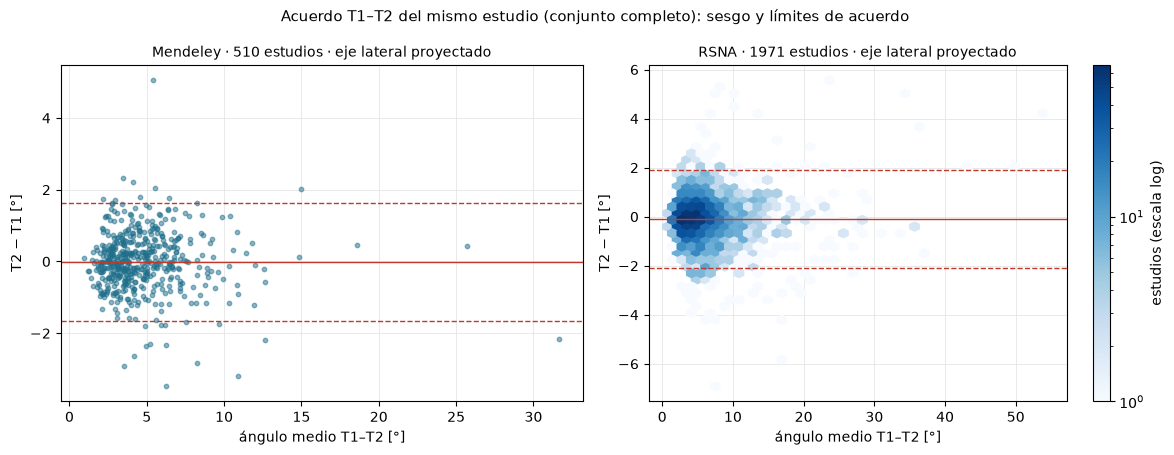

In [ ]:
# 16. Análisis 1: acuerdo T1–T2 con las tres fórmulas e hipótesis H1
filas, filas_h1 = [], []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        t = grupo(conjunto, sub, PARES_ANGULO)
        if len(t) < 3:
            continue
        idx = indices_bootstrap(len(t))
        remuestreos = {}
        for f in F_CORTO:
            t1, t2 = t[f"angulo_{f}_T1"].to_numpy(float), t[f"angulo_{f}_T2"].to_numpy(float)
            punto, boot = medidas_de_acuerdo(t1, t2), medidas_de_acuerdo(t1[idx], t2[idx])
            remuestreos[f] = boot
            fila = {"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f], "estudios": len(t)}
            for m in punto:
                lo, hi = ic95(boot[m])
                fila.update({m: float(punto[m]), f"{m}_ic95_inf": lo, f"{m}_ic95_sup": hi})
            filas.append(fila)
        dif = remuestreos["eje_lateral"]["ancho_limites"] - remuestreos["arctan"]["ancho_limites"]
        punto_dif = (medidas_de_acuerdo(t["angulo_eje_lateral_T1"].to_numpy(float), t["angulo_eje_lateral_T2"].to_numpy(float))["ancho_limites"]
                     - medidas_de_acuerdo(t["angulo_arctan_T1"].to_numpy(float), t["angulo_arctan_T2"].to_numpy(float))["ancho_limites"])
        lo, hi = ic95(dif)
        filas_h1.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "estudios": len(t),
                         "dif_ancho_eje_lateral_menos_arctan": float(punto_dif), "ic95_inf": lo, "ic95_sup": hi,
                         "H1_se_cumple": bool(hi < 0)})
acuerdo = pd.DataFrame(filas)
h1 = pd.DataFrame(filas_h1)
acuerdo.to_csv(DIR_SALIDA / "analisis1_acuerdo_t1_t2.csv", index=False)
COLS_VISTA = ["conjunto", "subconjunto", "formula", "estudios", "sesgo", "lim_inf", "lim_sup", "ancho_limites",
              "ancho_limites_ic95_inf", "ancho_limites_ic95_sup", "coef_repetibilidad", "icc_a1", "icc_a1_ic95_inf", "icc_a1_ic95_sup"]
display(acuerdo[COLS_VISTA].round(3))
for sub, g in h1.groupby("subconjunto", sort=False):
    n_si = int(g["H1_se_cumple"].sum())
    h1.loc[g.index, "resultado_H1"] = "se cumple" if n_si == len(g) == 2 else ("mixto" if n_si == 1 else "no se cumple")
h1.to_csv(DIR_SALIDA / "analisis1_hipotesis_H1.csv", index=False)
print("Hipótesis H1 (ancho de los límites de acuerdo: eje lateral − arctan; se cumple si el IC 95 % queda bajo cero):")
display(h1.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, conjunto in zip(axes, CONJUNTOS):
    t = grupo(conjunto, "completo", PARES_ANGULO)
    media = (t["angulo_eje_lateral_T1"] + t["angulo_eje_lateral_T2"]) / 2
    d = t["angulo_eje_lateral_T2"] - t["angulo_eje_lateral_T1"]
    if conjunto == "rsna":       # RSNA: densidad, sin puntos por estudio
        hb = ax.hexbin(media, d, gridsize=40, mincnt=1, cmap="Blues", bins="log")
        fig.colorbar(hb, ax=ax, label="estudios (escala log)")
    else:
        ax.scatter(media, d, s=10, alpha=0.5, color="#1f6f8b")
    r = acuerdo[(acuerdo["conjunto"] == CONJUNTOS[conjunto]) & (acuerdo["subconjunto"] == "completo")
                & (acuerdo["formula"] == NOMBRE_F[PRINCIPAL])].iloc[0]
    for v, estilo in ((r["sesgo"], "-"), (r["lim_inf"], "--"), (r["lim_sup"], "--")):
        ax.axhline(v, color="#c0392b", ls=estilo, lw=1)
    ax.set_title(f"{CONJUNTOS[conjunto]} · {len(t)} estudios · eje lateral proyectado", fontsize=10)
    ax.set_xlabel("ángulo medio T1–T2 [°]"); ax.set_ylabel("T2 − T1 [°]")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Acuerdo T1–T2 del mismo estudio (conjunto completo): sesgo y límites de acuerdo", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "analisis1_bland_altman.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 16.** La primera tabla contiene una fila por conjunto, subconjunto y fórmula. `sesgo` es la diferencia media T2 − T1; un valor próximo a cero indica que ninguna de las secuencias tiende a producir ángulos sistemáticamente mayores. `lim_inf` y `lim_sup` son los límites de acuerdo, dentro de los cuales se espera que se encuentre aproximadamente el 95 % de las diferencias si se cumplen los supuestos del método. `ancho_limites` es la distancia entre ambos extremos y constituye la medida utilizada para contrastar H1.

`coef_repetibilidad` resume la diferencia absoluta que no se espera superar en el 95 % de las repeticiones bajo el modelo utilizado. `icc_a1` cuantifica el acuerdo relativo teniendo en cuenta la variación entre estudios. Si los ángulos varían poco entre estudios, el ICC puede ser bajo incluso cuando las diferencias absolutas son pequeñas; por eso debe interpretarse junto con los límites de acuerdo y no de forma aislada.

La segunda tabla aplica el criterio de H1. `dif_ancho_eje_lateral_menos_arctan` es la diferencia entre los anchos; un valor negativo favorece al eje lateral. `H1_se_cumple` indica si el intervalo completo queda por debajo de cero, y `resultado_H1` resume el resultado de ambos conjuntos dentro de cada subconjunto.

En la figura, cada punto de Mendeley es un estudio; en RSNA, cada celda coloreada agrupa los estudios que caen en esa zona. El eje horizontal muestra la media de los dos ángulos y el vertical la diferencia T2 − T1. La línea continua representa el sesgo y las discontinuas, los límites de acuerdo. RSNA se presenta como densidad para no mostrar observaciones individuales.

### Análisis 2 · Error por cara y piso de ruido

El ángulo de una serie se obtiene como el máximo entre numerosos pares de caras de disco. Cuando se selecciona el máximo de muchas diferencias afectadas por error, el resultado puede ser mayor que cero incluso si las caras fueran paralelas. El análisis estima cuánto puede aportar ese error a la medida.

Primero se calcula la diferencia de inclinación coronal entre las caras correspondientes de T1 y T2. Los discos se emparejan por posición con el criterio del cuaderno 09: los centros deben ser mutuamente los más cercanos y estar separados por menos de 15 mm. Se utilizan los centros físicos de los discos guardados en ese cuaderno. Como la diferencia T2 − T1 acumula el error de ambas secuencias, el error estimado de una cara individual se calcula como $\sigma=\mathrm{DE}(\text{diferencias})/\sqrt{2}$. La estimación se realiza por conjunto, fórmula y subconjunto, y su intervalo de confianza se obtiene remuestreando estudios completos.

A continuación, para cada serie se simulan 2.000 columnas rectas con el mismo número de discos que tiene esa serie. A cada cara se le asigna una inclinación independiente extraída de $N(0,\sigma^2)$ y se aplica la regla del artículo. El piso de ruido de la serie corresponde al percentil 95 de los 2.000 ángulos máximos simulados. En otras palabras, es el valor que una columna recta superaría solo en el 5 % de las simulaciones bajo el modelo de error adoptado.

In [ ]:
# 17. Análisis 2: caras emparejadas por nivel entre la T1 y la T2, error por cara σ y piso de ruido
discos_fisicos = {i: g[g["tipo"] == "disco"] for i, g in etiquetas_09.groupby("id_serie")}
a_spider = traduccion_09.set_index(["id_serie", "etiqueta_original"])["etiqueta_spider"].to_dict()
cara_de = caras.set_index(["id_serie", "disco", "cara"])[list(F_CORTO.values()) + ["inclinacion_sagital"]].to_dict("index")

filas = []
for (conjunto, estudio), r in ancho[["id_serie_T1", "id_serie_T2"]].dropna().iterrows():
    d1, d2 = discos_fisicos.get(r["id_serie_T1"]), discos_fisicos.get(r["id_serie_T2"])
    if d1 is None or d2 is None or d1.empty or d2.empty:
        continue
    P1, P2 = d1[["x_mm", "y_mm", "z_mm"]].to_numpy(float), d2[["x_mm", "y_mm", "z_mm"]].to_numpy(float)
    e1, e2 = d1["etiqueta"].to_numpy(int), d2["etiqueta"].to_numpy(int)
    D = np.linalg.norm(P2[:, None, :] - P1[None, :, :], axis=2)
    parejas = [(i, int(D[i].argmin())) for i in range(len(P2))                    # igual que en el cuaderno 09
               if D[i].min() < MAX_PAREJA_T1_T2_MM and int(D[:, D[i].argmin()].argmin()) == i]
    for i, j in parejas:
        s1, s2 = a_spider.get((r["id_serie_T1"], e1[j])), a_spider.get((r["id_serie_T2"], e2[i]))
        for cara in ("inferior", "superior"):
            f1, f2 = cara_de.get((r["id_serie_T1"], s1, cara)), cara_de.get((r["id_serie_T2"], s2, cara))
            if f1 is None or f2 is None:
                continue
            fila = {"conjunto": conjunto, "estudio": estudio, "nivel_t1": NOMBRE_DISCO_TSS.get(e1[j], str(e1[j])),
                    "mismo_nombre": bool(e1[j] == e2[i]), "cara": cara, "distancia_mm": float(D[i, j]),
                    "incl_sag_t1": f1["inclinacion_sagital"], "incl_sag_t2": f2["inclinacion_sagital"]}
            fila.update({f"dif_{f}": f2[col] - f1[col] for f, col in F_CORTO.items()})
            filas.append(fila)
caras_pareadas = pd.DataFrame(filas)
caras_pareadas["sin_marcas"] = [(c, e) in sin_marcas for c, e in zip(caras_pareadas["conjunto"], caras_pareadas["estudio"])]
caras_pareadas.to_csv(DIR_PRIV / "caras_pareadas_t1_t2.csv", index=False)
caras_pareadas[caras_pareadas["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "caras_pareadas_t1_t2_mendeley.csv", index=False)

def sigma_con_ic(g, columna):
    "σ = DE(diferencias)/√2 sobre todas las caras, con IC por remuestreo de estudios completos."
    if g[columna].notna().sum() < 3:
        return np.nan, np.nan, np.nan, int(g[columna].notna().sum()), int(g["estudio"].nunique())
    por_estudio = g.groupby("estudio")[columna].agg(n="count", s1="sum", s2=lambda x: (x ** 2).sum())
    n, s1, s2 = (por_estudio[c].to_numpy(float) for c in ("n", "s1", "s2"))
    def sigma(N, S1, S2):
        return np.sqrt((S2 - S1 ** 2 / N) / (N - 1) / 2)
    idx = indices_bootstrap(len(por_estudio))
    boot = sigma(n[idx].sum(axis=1), s1[idx].sum(axis=1), s2[idx].sum(axis=1))
    return float(sigma(n.sum(), s1.sum(), s2.sum())), *ic95(boot), int(n.sum()), len(por_estudio)

filas, SIGMA = [], {}
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        g = caras_pareadas[caras_pareadas["conjunto"] == conjunto]
        g = g[g["sin_marcas"]] if sub == "sin_marcas" else g
        for f in F_CORTO:
            s, lo, hi, n_caras, n_est = sigma_con_ic(g, f"dif_{f}")
            SIGMA[(conjunto, sub, f)] = s
            filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f], "estudios": n_est,
                          "caras": n_caras, "sigma_grados": s, "ic95_inf": lo, "ic95_sup": hi,
                          "caras_con_otro_nombre_pct": 100 * (~g["mismo_nombre"]).mean()})
sigmas = pd.DataFrame(filas)
sigmas.to_csv(DIR_SALIDA / "analisis2_error_por_cara.csv", index=False)
print("Error por cara σ (grados), con IC 95 % por remuestreo de estudios:")
display(sigmas.round(3))

_pisos = {}
def piso_de_ruido(n_discos, sigma):
    "Percentil 95 del ángulo máximo (regla del artículo) en N_COLUMNAS_RECTAS columnas rectas con error N(0, σ²) por cara."
    if not (n_discos >= 2 and np.isfinite(sigma)):
        return np.nan
    clave = (int(n_discos), float(sigma))
    if clave not in _pisos:
        rng = np.random.default_rng(SEMILLA)
        sup = rng.normal(0, sigma, (N_COLUMNAS_RECTAS, int(n_discos)))     # cara superior de cada disco
        inf = rng.normal(0, sigma, (N_COLUMNAS_RECTAS, int(n_discos)))     # cara inferior de cada disco
        a_menor_que_b = np.triu(np.ones((int(n_discos),) * 2, dtype=bool), k=1)
        maximo = np.abs(sup[:, :, None] - inf[:, None, :])[:, a_menor_que_b].max(axis=1)
        _pisos[clave] = float(np.percentile(maximo, 95))
    return _pisos[clave]

for sub in SUBCONJUNTOS:
    for f in F_CORTO:
        angulos[f"piso_{f}_{sub}"] = [piso_de_ruido(n, SIGMA.get((c, sub, f), np.nan))
                                      for n, c in zip(angulos["n_discos"], angulos["conjunto"])]
angulos.to_csv(DIR_PRIV / "angulos_por_serie.csv", index=False)
angulos[angulos["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "angulos_por_serie_mendeley.csv", index=False)
piso_por_discos = pd.DataFrame([{"conjunto": CONJUNTOS[c], "subconjunto": s, "formula": NOMBRE_F[f], "discos": n,
                                 "piso_de_ruido_grados": piso_de_ruido(n, SIGMA[(c, s, f)]),
                                 "series_T1": int(((angulos["conjunto"] == c) & (angulos["clase"] == "T1") & (angulos["n_discos"] == n)).sum())}
                                for c in CONJUNTOS for s in SUBCONJUNTOS for f in F_CORTO
                                for n in sorted(angulos.loc[angulos["conjunto"] == c, "n_discos"].dropna().astype(int).unique())])
piso_por_discos.to_csv(DIR_SALIDA / "analisis2_piso_de_ruido_por_discos.csv", index=False)
print("Piso de ruido (grados) según el número de discos, fórmula principal y conjunto completo:")
display(piso_por_discos[(piso_por_discos["formula"] == NOMBRE_F[PRINCIPAL]) & (piso_por_discos["subconjunto"] == "completo")]
        .pivot_table(index="discos", columns="conjunto", values=["piso_de_ruido_grados", "series_T1"]).round(2))

Error por cara σ (grados), con IC 95 % por remuestreo de estudios:


,conjunto,subconjunto,formula,estudios,caras,sigma_grados,ic95_inf,ic95_sup,caras_con_otro_nombre_pct
0,Mendeley,completo,eje lateral proyectado,509,6902,0.461,0.432,0.492,0.290
1,Mendeley,completo,arctan(nx/nz),509,6902,0.486,0.454,0.523,0.290
2,Mendeley,completo,arcsen(nx),509,6902,0.472,0.442,0.506,0.290
3,Mendeley,sin_marcas,eje lateral proyectado,349,4718,0.417,0.401,0.434,0.000
4,Mendeley,sin_marcas,arctan(nx/nz),349,4718,0.434,0.418,0.452,0.000
5,Mendeley,sin_marcas,arcsen(nx),349,4718,0.424,0.409,0.442,0.000
6,RSNA,completo,eje lateral proyectado,1967,28322,0.498,0.481,0.515,0.636
7,RSNA,completo,arctan(nx/nz),1967,28322,0.532,0.514,0.551,0.636
8,RSNA,completo,arcsen(nx),1967,28322,0.512,0.495,0.530,0.636
9,RSNA,sin_marcas,eje lateral proyectado,1235,17592,0.485,0.470,0.500,0.011


Piso de ruido (grados) según el número de discos, fórmula principal y conjunto completo:


piso_de_ruido_grados       series_T1       
conjunto             Mendeley  RSNA  Mendeley   RSNA
discos                                              
3                        1.55   NaN       0.0    NaN
4                        1.69   NaN       0.0    NaN
5                        1.81   NaN       1.0    NaN
6                        1.89  2.04     154.0  177.0
7                        1.93  2.09     308.0  997.0
8                        2.00  2.17      46.0  624.0
9                        2.06  2.23       6.0  148.0
10                        NaN  2.22       NaN   17.0
11                        NaN  2.27       NaN    6.0
12                        NaN  2.30       NaN    2.0
13                        NaN  2.33       NaN    1.0
15                        NaN  2.40       NaN    0.0

**Cómo leer la salida de la celda 17.** La primera tabla presenta el error por cara, σ, con su intervalo de confianza, para cada conjunto, subconjunto y fórmula. También informa el número de estudios y de caras emparejadas. `caras_con_otro_nombre_pct` indica qué porcentaje de caras emparejadas recibió etiquetas distintas en T1 y T2. Estas caras se conservan en el análisis porque la correspondencia se establece por posición y no por el nombre asignado.

La segunda tabla muestra el piso de ruido en función del número de discos de la serie. Se presenta para la fórmula principal y el conjunto completo, junto con el número de series T1 que tiene cada cantidad de discos. El piso tiende a aumentar con el número de discos porque hay más pares posibles y, por tanto, más oportunidades para que el máximo aumente por efecto del error. Este valor por serie se utiliza después en el análisis 5. Los resultados correspondientes a las otras fórmulas y subconjuntos se guardan en los archivos CSV.

La interpretación de σ depende de dos supuestos: que el error sea independiente entre caras y que T1 y T2 tengan una magnitud de error semejante. Si el paciente cambió de posición entre adquisiciones, una parte de la diferencia podría corresponder a un cambio real de postura y no al error de medición; en ese caso, σ estaría algo sobreestimado. En el cuaderno 09, la distancia mediana entre los centros del mismo disco en ambas secuencias fue de 0,65 mm en Mendeley y 1,07 mm en RSNA.

### Análisis 3 · Zona de indecisión alrededor de 10°

Para cada estudio se calcula el promedio de los ángulos T1 y T2. Después se clasifica cada secuencia según si su ángulo es igual o superior a 10°. La celda 18 agrupa los estudios en intervalos de 2° del ángulo medio y calcula, en cada intervalo, la proporción en la que T1 y T2 quedan a lados distintos del umbral, junto con su intervalo de confianza de Clopper–Pearson.

La zona de indecisión corresponde al rango de ángulos medios en el que esa discrepancia es más frecuente. En esa región, una sola adquisición puede no ser suficiente para determinar de qué lado del umbral de 10° queda el estudio.

Discrepancia en la clasificación ≥10° (porcentaje de estudios), por tramo del ángulo medio; fórmula principal:


n                                     pct             \
conjunto    Mendeley                RSNA            Mendeley              
subconjunto completo sin_marcas completo sin_marcas completo sin_marcas   
desde                                                                     
0.0             22.0       17.0     77.0       49.0      0.0        0.0   
2.0            223.0      157.0    540.0      342.0      0.0        0.0   
4.0            150.0      106.0    564.0      341.0      0.0        0.0   
6.0             69.0       41.0    334.0      196.0      0.0        0.0   
8.0             26.0       16.0    167.0      101.0     11.5        6.2   
10.0            12.0        8.0    105.0       73.0     25.0       12.5   
12.0             3.0        2.0     60.0       44.0      0.0        0.0   
14.0             2.0        1.0     37.0       24.0      0.0        0.0   
16.0             NaN        NaN     25.0       23.0      NaN        NaN   
18.0             1.0        1.0     14.0        9.0      0.0        0.0   
20.0             NaN        NaN     11.0        8.0      NaN        NaN   
22.0             NaN        NaN     11.0        7.0      NaN        NaN   
24.0             1.0        NaN      7.0        4.0      0.0        NaN   
26.0             NaN        NaN      5.0        4.0      NaN        NaN   
28.0             NaN        NaN      4.0        4.0      NaN        NaN   
30.0             1.0        NaN      1.0        1.0      0.0        NaN   
32.0             NaN        NaN      1.0        1.0      NaN        NaN   
34.0             NaN        NaN      4.0        2.0      NaN        NaN   
36.0             NaN        NaN      1.0        1.0      NaN        NaN   
42.0             NaN        NaN      1.0        NaN      NaN        NaN   
48.0             NaN        NaN      1.0        NaN      NaN        NaN   
54.0             NaN        NaN      1.0        1.0      NaN        NaN   

                                 
conjunto        RSNA             
subconjunto completo sin_marcas  
desde                            
0.0              0.0        0.0  
2.0              0.0        0.0  
4.0              0.0        0.0  
6.0              0.0        0.0  
8.0             13.2       13.9  
10.0            20.0       17.8  
12.0             0.0        0.0  
14.0             0.0        0.0  
16.0             0.0        0.0  
18.0             0.0        0.0  
20.0             0.0        0.0  
22.0             0.0        0.0  
24.0             0.0        0.0  
26.0             0.0        0.0  
28.0             0.0        0.0  
30.0             0.0        0.0  
32.0             0.0        0.0  
34.0             0.0        0.0  
36.0             0.0        0.0  
42.0             0.0        NaN  
48.0             0.0        NaN  
54.0             0.0        0.0

Discrepancia total, todas las fórmulas:


conjunto               Mendeley                RSNA           
subconjunto            completo sin_marcas completo sin_marcas
formula                                                       
arcsen(nx)                  1.2        0.6      2.3        2.3
arctan(nx/nz)               1.4        0.3      2.8        2.5
eje lateral proyectado      1.2        0.6      2.2        2.2

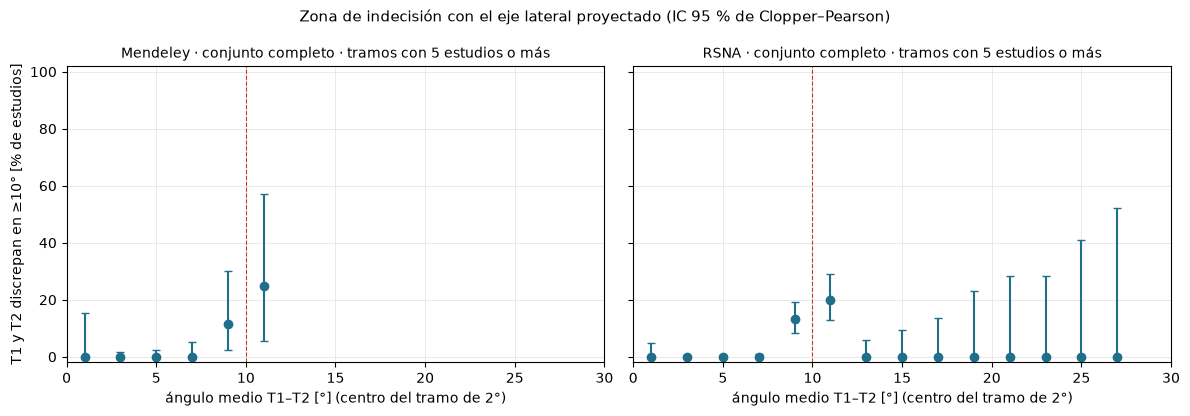

In [ ]:
# 18. Análisis 3: discrepancia T1–T2 en la clasificación ≥10° por tramos de 2° del ángulo medio
filas = []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        t = grupo(conjunto, sub, PARES_ANGULO)
        for f in F_CORTO:
            t1, t2 = t[f"angulo_{f}_T1"].to_numpy(float), t[f"angulo_{f}_T2"].to_numpy(float)
            media, discrepan = (t1 + t2) / 2, (t1 >= UMBRAL_ANGULO) != (t2 >= UMBRAL_ANGULO)
            bordes = np.arange(0, 2 * np.ceil(media.max() / 2) + 2, 2) if len(media) else np.array([0, 2])
            tramo = pd.cut(media, bordes, right=False)
            for intervalo, g in pd.Series(discrepan).groupby(tramo, observed=True):
                filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f],
                              "tramo_angulo_medio": str(intervalo), "desde": intervalo.left, **proporcion(g.to_numpy())})
            filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f],
                          "tramo_angulo_medio": "todos", "desde": np.nan, **proporcion(discrepan)})
indecision = pd.DataFrame(filas)
indecision.to_csv(DIR_SALIDA / "analisis3_zona_de_indecision.csv", index=False)
print("Discrepancia en la clasificación ≥10° (porcentaje de estudios), por tramo del ángulo medio; fórmula principal:")
vista = indecision[(indecision["formula"] == NOMBRE_F[PRINCIPAL]) & (indecision["tramo_angulo_medio"] != "todos")]
display(vista.pivot_table(index="desde", columns=["conjunto", "subconjunto"], values=["n", "pct"], aggfunc="first").round(1))
print("Discrepancia total, todas las fórmulas:")
display(indecision[indecision["tramo_angulo_medio"] == "todos"]
        .pivot_table(index="formula", columns=["conjunto", "subconjunto"], values="pct", aggfunc="first").round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, conjunto in zip(axes, CONJUNTOS):
    v = vista[(vista["conjunto"] == CONJUNTOS[conjunto]) & (vista["subconjunto"] == "completo") & (vista["n"] >= 5)]
    x = v["desde"] + 1
    ax.errorbar(x, v["pct"], yerr=[v["pct"] - v["ic95_inf_pct"], v["ic95_sup_pct"] - v["pct"]], fmt="o", color="#1f6f8b", capsize=3)
    ax.axvline(UMBRAL_ANGULO, color="#c0392b", lw=0.8, ls="--")
    ax.set_ylim(-2, 102); ax.set_xlim(0, max(30.0, float(x.max()) + 2) if len(x) else 30.0)
    ax.set_title(f"{CONJUNTOS[conjunto]} · conjunto completo · tramos con 5 estudios o más", fontsize=10)
    ax.set_xlabel("ángulo medio T1–T2 [°] (centro del tramo de 2°)")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("T1 y T2 discrepan en ≥10° [% de estudios]")
fig.suptitle("Zona de indecisión con el eje lateral proyectado (IC 95 % de Clopper–Pearson)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "analisis3_zona_de_indecision.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 18.** La primera tabla contiene una fila por intervalo de 2° del ángulo medio, identificado por el límite inferior `desde`. Para cada conjunto y subconjunto informa el número de estudios del intervalo (`n`) y el porcentaje en el que T1 y T2 quedan a lados distintos del umbral de 10° (`pct`).

Se espera que la discrepancia sea baja cuando el ángulo medio está lejos de 10° y aumente en los intervalos próximos al umbral. La extensión de los intervalos en los que aumenta permite describir la zona de indecisión. La segunda tabla presenta la discrepancia total para cada fórmula. En la figura solo se muestran intervalos con al menos cinco estudios, porque con tamaños menores los intervalos de confianza son demasiado amplios para facilitar la interpretación. La línea roja señala el umbral de 10°.

### Análisis 4 · Desacuerdo según la inclinación sagital

En el cuaderno 07, el análisis de SPIDER mostró que las caras con mayor inclinación en el plano sagital, en particular, algunas caras de los discos más caudales podían presentar diferencias mayores. La celda 19 examina si se observa un patrón semejante en los conjuntos externos.

El análisis se realiza de dos maneras. A nivel de cara, se compara la diferencia T1–T2 de la inclinación coronal entre caras cuya mayor inclinación sagital en cualquiera de las dos secuencias es de hasta 30° o supera ese valor. A nivel de estudio, se compara la diferencia T1–T2 del ángulo completo según si alguna de las caras del par seleccionado en cualquiera de las secuencias supera los 30°. Es un análisis descriptivo y no incluye una hipótesis confirmatoria.

In [ ]:
# 19. Análisis 4: desacuerdo T1–T2 según la inclinación sagital de las caras (por debajo y por encima de 30°)
cp = caras_pareadas.copy()
cp["inclinacion_sagital"] = np.where(cp[["incl_sag_t1", "incl_sag_t2"]].abs().max(axis=1) > UMBRAL_INCLINACION_SAGITAL,
                                     f"> {UMBRAL_INCLINACION_SAGITAL:.0f}°", f"≤ {UMBRAL_INCLINACION_SAGITAL:.0f}°")
filas = []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        g0 = cp[cp["conjunto"] == conjunto]
        g0 = g0[g0["sin_marcas"]] if sub == "sin_marcas" else g0
        for f in F_CORTO:
            for nivel, g in g0.groupby("inclinacion_sagital"):
                d = g[f"dif_{f}"]
                filas.append({"unidad": "cara", "conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f],
                              "inclinacion_sagital": nivel, "n": len(d), "mediana_abs_dif": d.abs().median(),
                              "p90_abs_dif": d.abs().quantile(0.9), "sigma_grados": d.std(ddof=1) / np.sqrt(2)})
        t0 = grupo(conjunto, sub, PARES_ANGULO)
        for f in F_CORTO:
            alta = t0[[f"incl_sag_par_{f}_T1", f"incl_sag_par_{f}_T2"]].max(axis=1) > UMBRAL_INCLINACION_SAGITAL
            d = t0[f"angulo_{f}_T2"] - t0[f"angulo_{f}_T1"]
            for nivel, g in d.groupby(np.where(alta, f"> {UMBRAL_INCLINACION_SAGITAL:.0f}°", f"≤ {UMBRAL_INCLINACION_SAGITAL:.0f}°")):
                filas.append({"unidad": "estudio (par elegido)", "conjunto": CONJUNTOS[conjunto], "subconjunto": sub,
                              "formula": NOMBRE_F[f], "inclinacion_sagital": nivel, "n": len(g),
                              "mediana_abs_dif": g.abs().median(), "p90_abs_dif": g.abs().quantile(0.9),
                              "de_dif": g.std(ddof=1), "ancho_limites": 2 * 1.96 * g.std(ddof=1)})
sagital = pd.DataFrame(filas)
sagital.to_csv(DIR_SALIDA / "analisis4_inclinacion_sagital.csv", index=False)
for unidad, g in sagital.groupby("unidad", sort=False):
    print(f"Por {unidad}, conjunto completo:")
    display(g[g["subconjunto"] == "completo"].drop(columns=["unidad", "subconjunto"]).dropna(axis=1, how="all").round(2))

Por cara, conjunto completo:


,conjunto,formula,inclinacion_sagital,n,mediana_abs_dif,p90_abs_dif,sigma_grados
0,Mendeley,eje lateral proyectado,> 30°,574,0.24,0.57,0.29
1,Mendeley,eje lateral proyectado,≤ 30°,6328,0.35,1.00,0.47
2,Mendeley,arctan(nx/nz),> 30°,574,0.36,0.91,0.45
3,Mendeley,arctan(nx/nz),≤ 30°,6328,0.37,1.04,0.49
4,Mendeley,arcsen(nx),> 30°,574,0.29,0.72,0.36
5,Mendeley,arcsen(nx),≤ 30°,6328,0.36,1.02,0.48
21,RSNA,eje lateral proyectado,> 30°,2313,0.27,0.80,0.37
22,RSNA,eje lateral proyectado,≤ 30°,26009,0.36,1.09,0.51
23,RSNA,arctan(nx/nz),> 30°,2313,0.43,1.26,0.59
24,RSNA,arctan(nx/nz),≤ 30°,26009,0.37,1.13,0.53


Por estudio (par elegido), conjunto completo:


,conjunto,formula,inclinacion_sagital,n,mediana_abs_dif,p90_abs_dif,de_dif,ancho_limites
6,Mendeley,eje lateral proyectado,> 30°,97,0.42,1.60,0.98,3.86
7,Mendeley,eje lateral proyectado,≤ 30°,413,0.46,1.27,0.80,3.13
8,Mendeley,arctan(nx/nz),> 30°,117,0.48,1.66,1.08,4.24
9,Mendeley,arctan(nx/nz),≤ 30°,393,0.47,1.24,0.81,3.19
10,Mendeley,arcsen(nx),> 30°,108,0.43,1.58,1.03,4.02
11,Mendeley,arcsen(nx),≤ 30°,402,0.48,1.25,0.80,3.13
27,RSNA,eje lateral proyectado,> 30°,369,0.53,1.53,1.00,3.91
28,RSNA,eje lateral proyectado,≤ 30°,1602,0.52,1.60,1.02,3.98
29,RSNA,arctan(nx/nz),> 30°,487,0.63,1.89,1.21,4.75
30,RSNA,arctan(nx/nz),≤ 30°,1484,0.53,1.68,1.06,4.14


**Cómo leer la salida de la celda 19.** En la tabla por cara, cada fila agrupa las caras emparejadas de un conjunto y una fórmula según la inclinación sagital. `mediana_abs_dif` y `p90_abs_dif` resumen la diferencia absoluta T1–T2 de la inclinación coronal. `sigma_grados` es el error por cara estimado para ese grupo con el mismo procedimiento del análisis 2. Si las caras muy inclinadas presentan mayor desacuerdo, se esperaría encontrar un σ más alto en ese grupo.

La tabla por estudio agrupa los estudios según si el par elegido contiene alguna cara con inclinación sagital superior a 30° en T1 o T2. Para cada grupo informa la diferencia absoluta del ángulo de la serie y el ancho de los límites de acuerdo. El plan definió este análisis como descriptivo, por lo que las tablas no incluyen intervalos de confianza.

Los resultados del subconjunto sin marcas también se guardan en el CSV. En ese subconjunto, los estudios cuyo par supera los 30° ya están excluidos por definición; por eso la tabla por estudio solo contiene el grupo de 30° o menos.

### Análisis 5 · Distribución del ángulo y proporción de 10° o más

La celda 20 describe la distribución del ángulo por conjunto, secuencia y fórmula. La T1 se utiliza como secuencia principal y la T2 completa como corroboración. Además de los percentiles de la distribución, se calculan tres proporciones con intervalos exactos de Clopper–Pearson: estudios con un ángulo igual o superior a 10°; estudios cuyo ángulo supera el piso de ruido estimado para su propia serie; y estudios que cumplen ambas condiciones.

La tercera proporción identifica los estudios que alcanzan 10° y, además, superan el nivel que el modelo de error podría producir en una columna recta. No debe interpretarse como una prevalencia de escoliosis. El ángulo se estima en decúbito a partir de RM sagital, mientras que el Cobb clínico se mide de pie mediante radiografía. Además, RSNA y Mendeley son conjuntos de pacientes remitidos a una RM lumbar, no muestras representativas de la población general.

En Mendeley también se presentan los resultados de la T1 por sexo y por grupos de edad: menores de 40 años, de 40 a 59 años y de 60 años o más. Se mantienen los mismos grupos definidos en el cuaderno 09.

Distribución del ángulo (grados) y proporciones (%), fórmula principal:


series  mediana  p25  p75   p90  piso_mediana  \
conjunto subconjunto secuencia                                                  
Mendeley completo    T1            515      4.1  3.0  5.7   7.5           1.9   
                     T2            510      4.1  3.0  5.9   7.6           1.9   
         sin_marcas  T1            349      4.0  3.0  5.6   7.5           1.7   
                     T2            349      4.0  3.0  5.6   7.3           1.7   
RSNA     completo    T1           1972      5.3  3.6  7.8  11.8           2.1   
                     T2           1974      5.2  3.5  7.6  11.6           2.1   
         sin_marcas  T1           1236      5.3  3.6  8.1  12.6           2.0   
                     T2           1236      5.2  3.5  7.9  12.4           2.0   

                                ge10_pct  ge10_ic95_inf  ge10_ic95_sup  \
conjunto subconjunto secuencia                                           
Mendeley completo    T1              4.1            2.5            6.2   
                     T2              3.7            2.3            5.8   
         sin_marcas  T1              3.7            2.0            6.3   
                     T2              3.2            1.6            5.6   
RSNA     completo    T1             15.1           13.5           16.7   
                     T2             14.3           12.8           15.9   
         sin_marcas  T1             17.3           15.2           19.5   
                     T2             16.1           14.1           18.3   

                                sobre_piso_pct  ge10_y_sobre_piso_pct  \
conjunto subconjunto secuencia                                          
Mendeley completo    T1                   95.7                    4.1   
                     T2                   94.7                    3.7   
         sin_marcas  T1                   97.1                    3.7   
                     T2                   95.7                    3.2   
RSNA     completo    T1                   94.7                   15.1   
                     T2                   94.1                   14.3   
         sin_marcas  T1                   94.7                   17.3   
                     T2                   94.7                   16.1   

                                ge10_y_sobre_piso_ic95_inf  \
conjunto subconjunto secuencia                               
Mendeley completo    T1                                2.5   
                     T2                                2.3   
         sin_marcas  T1                                2.0   
                     T2                                1.6   
RSNA     completo    T1                               13.5   
                     T2                               12.8   
         sin_marcas  T1                               15.2   
                     T2                               14.1   

                                ge10_y_sobre_piso_ic95_sup  
conjunto subconjunto secuencia                              
Mendeley completo    T1                                6.2  
                     T2                                5.8  
         sin_marcas  T1                                6.3  
                     T2                                5.6  
RSNA     completo    T1                               16.7  
                     T2                               15.9  
         sin_marcas  T1                               19.5  
                     T2                               18.3

Mendeley por sexo y grupo de edad, T1, fórmula principal:


series  mediana  p25  p75   p90  piso_mediana  \
subconjunto variable   grupo                                                  
completo    sexo       F         198      4.5  3.3  6.2   8.4           1.9   
                       M         317      3.9  2.8  5.6   7.2           1.9   
            grupo_edad <40       246      3.9  2.8  5.6   7.4           1.9   
                       40–59     215      4.3  3.0  5.8   7.4           1.9   
                       ≥60        54      4.4  3.4  6.2   9.6           1.9   
sin_marcas  sexo       F         132      4.5  3.2  5.9   8.5           1.7   
                       M         217      3.8  2.8  5.3   6.8           1.7   
            grupo_edad <40       170      3.7  2.8  5.1   6.7           1.7   
                       40–59     150      4.1  2.9  5.6   7.4           1.7   
                       ≥60        29      5.0  3.7  6.8  10.0           1.7   

                              ge10_pct  ge10_ic95_inf  ge10_ic95_sup  \
subconjunto variable   grupo                                           
completo    sexo       F           6.1            3.2           10.3   
                       M           2.8            1.3            5.3   
            grupo_edad <40         3.7            1.7            6.8   
                       40–59       3.3            1.3            6.6   
                       ≥60         9.3            3.1           20.3   
sin_marcas  sexo       F           6.8            3.2           12.5   
                       M           1.8            0.5            4.7   
            grupo_edad <40         2.9            1.0            6.7   
                       40–59       3.3            1.1            7.6   
                       ≥60        10.3            2.2           27.4   

                              sobre_piso_pct  ge10_y_sobre_piso_pct  \
subconjunto variable   grupo                                          
completo    sexo       F                96.5                    6.1   
                       M                95.3                    2.8   
            grupo_edad <40              95.5                    3.7   
                       40–59            95.8                    3.3   
                       ≥60              96.3                    9.3   
sin_marcas  sexo       F                97.0                    6.8   
                       M                97.2                    1.8   
            grupo_edad <40              97.1                    2.9   
                       40–59            96.7                    3.3   
                       ≥60             100.0                   10.3   

                              ge10_y_sobre_piso_ic95_inf  \
subconjunto variable   grupo                               
completo    sexo       F                             3.2   
                       M                             1.3   
            grupo_edad <40                           1.7   
                       40–59                         1.3   
                       ≥60                           3.1   
sin_marcas  sexo       F                             3.2   
                       M                             0.5   
            grupo_edad <40                           1.0   
                       40–59                         1.1   
                       ≥60                           2.2   

                              ge10_y_sobre_piso_ic95_sup  
subconjunto variable   grupo                              
completo    sexo       F                            10.3  
                       M                             5.3  
            grupo_edad <40                           6.8  
                       40–59                         6.6  
                       ≥60                          20.3  
sin_marcas  sexo       F                            12.5  
                       M                             4.7  
            grupo_edad <40                           6.7  
                       40–59                        

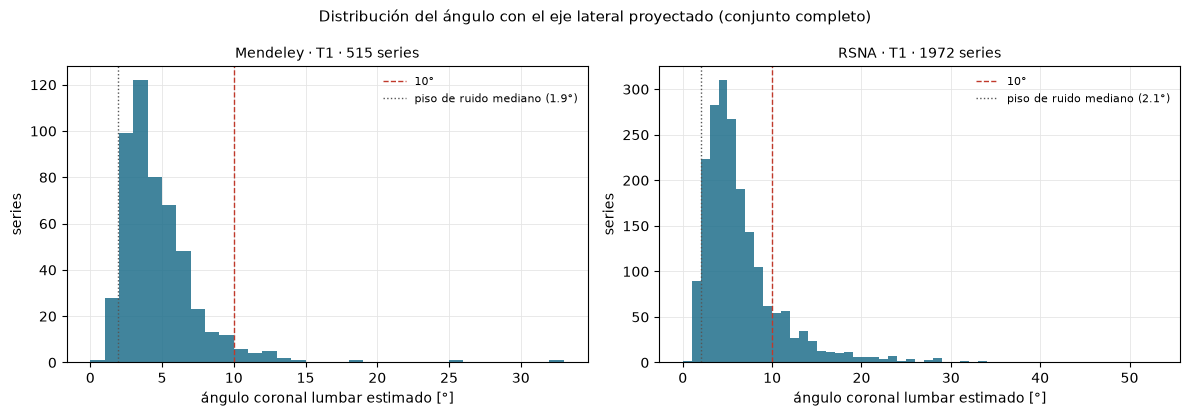

In [ ]:
# 20. Análisis 5: distribución del ángulo y proporciones ≥10°, por encima del piso de ruido y las dos cosas a la vez
series_m = leer(CSV_SERIES_MENDELEY)
paciente = series_m.groupby("paciente")[["sexo", "edad"]].first()
paciente["edad_anios"] = pd.to_numeric(paciente["edad"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
paciente["grupo_edad"] = pd.cut(paciente["edad_anios"], [0, 40, 60, 200], right=False, labels=["<40", "40–59", "≥60"])

def resumen_distribucion(a, piso):
    a, piso = np.asarray(a, float), np.asarray(piso, float)
    fila = {"series": len(a), "mediana": np.median(a) if len(a) else np.nan, "p25": np.percentile(a, 25) if len(a) else np.nan,
            "p75": np.percentile(a, 75) if len(a) else np.nan, "p90": np.percentile(a, 90) if len(a) else np.nan,
            "piso_mediana": np.nanmedian(piso) if len(a) else np.nan}
    for nombre, m in (("ge10", a >= UMBRAL_ANGULO), ("sobre_piso", a > piso), ("ge10_y_sobre_piso", (a >= UMBRAL_ANGULO) & (a > piso))):
        p = proporcion(m)
        fila.update({f"{nombre}_pct": p["pct"], f"{nombre}_ic95_inf": p["ic95_inf_pct"], f"{nombre}_ic95_sup": p["ic95_sup_pct"],
                     f"{nombre}_k": p["k"]})
    return fila

filas, filas_men = [], []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        for clase in ("T1", "T2"):
            for f in F_CORTO:
                t = grupo(conjunto, sub, [f"angulo_{f}_{clase}"])
                serie = angulos.set_index("id_serie").loc[t[f"id_serie_{clase}"]]
                filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F[f],
                              **resumen_distribucion(serie[f"angulo_{f}"], serie[f"piso_{f}_{sub}"])})
                if conjunto == "mendeley":
                    serie = serie.join(paciente[["sexo", "grupo_edad"]], on="estudio")
                    for variable in ("sexo", "grupo_edad"):
                        for valor, g in serie.groupby(variable, observed=True):
                            filas_men.append({"subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F[f], "variable": variable,
                                              "grupo": valor, **resumen_distribucion(g[f"angulo_{f}"], g[f"piso_{f}_{sub}"])})
distribucion = pd.DataFrame(filas)
distribucion_men = pd.DataFrame(filas_men)
distribucion.to_csv(DIR_SALIDA / "analisis5_distribucion.csv", index=False)
distribucion_men.to_csv(DIR_SALIDA / "analisis5_mendeley_sexo_edad.csv", index=False)
COLS5 = ["series", "mediana", "p25", "p75", "p90", "piso_mediana", "ge10_pct", "ge10_ic95_inf", "ge10_ic95_sup",
         "sobre_piso_pct", "ge10_y_sobre_piso_pct", "ge10_y_sobre_piso_ic95_inf", "ge10_y_sobre_piso_ic95_sup"]
print("Distribución del ángulo (grados) y proporciones (%), fórmula principal:")
display(distribucion[distribucion["formula"] == NOMBRE_F[PRINCIPAL]].set_index(["conjunto", "subconjunto", "secuencia"])[COLS5].round(1))
print("Mendeley por sexo y grupo de edad, T1, fórmula principal:")
display(distribucion_men[(distribucion_men["formula"] == NOMBRE_F[PRINCIPAL]) & (distribucion_men["secuencia"] == "T1")]
        .set_index(["subconjunto", "variable", "grupo"])[COLS5].round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, conjunto in zip(axes, CONJUNTOS):
    t = grupo(conjunto, "completo", [f"angulo_{PRINCIPAL}_T1"])
    a = t[f"angulo_{PRINCIPAL}_T1"].astype(float)
    ax.hist(a, bins=np.arange(0, max(30, a.max()) + 1, 1), color="#1f6f8b", alpha=0.85)
    ax.axvline(UMBRAL_ANGULO, color="#c0392b", lw=1, ls="--", label="10°")
    piso = angulos.set_index("id_serie").loc[t["id_serie_T1"], f"piso_{PRINCIPAL}_completo"].median()
    ax.axvline(piso, color="#555555", lw=1, ls=":", label=f"piso de ruido mediano ({piso:.1f}°)")
    ax.set_title(f"{CONJUNTOS[conjunto]} · T1 · {len(a)} series", fontsize=10)
    ax.set_xlabel("ángulo coronal lumbar estimado [°]"); ax.set_ylabel("series")
    ax.legend(fontsize=8, frameon=False); ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Distribución del ángulo con el eje lateral proyectado (conjunto completo)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "analisis5_distribucion.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 20.** La primera tabla contiene una fila por conjunto, subconjunto y secuencia, y utiliza la fórmula principal. La mediana, los percentiles 25, 75 y 90 describen la distribución de los ángulos en grados. `piso_mediana` es el valor mediano del piso de ruido de las series incluidas.

`ge10_pct` indica el porcentaje de estudios con un ángulo igual o superior a 10°, acompañado de su intervalo de confianza. `sobre_piso_pct` corresponde al porcentaje cuyo ángulo supera el piso de ruido de su propia serie. `ge10_y_sobre_piso_pct` identifica los estudios que cumplen simultáneamente ambas condiciones, también con su intervalo de confianza. Si la proporción que supera 10° es claramente mayor que la que supera 10° y el piso de ruido, parte de los ángulos que alcanzan el umbral podría explicarse por el error de medición estimado.

La segunda tabla presenta el mismo resumen para Mendeley, desglosado por sexo y grupo de edad, utilizando la T1. Los resultados de las demás fórmulas y de la T2 se conservan en los archivos CSV. En la figura, la línea roja señala los 10° y la línea gris discontinua representa el piso de ruido mediano.

### Análisis 6 · Notas de los radiólogos de Mendeley

El cuaderno 08 identificó cinco informes de Mendeley que mencionan escoliosis, correspondientes a los pacientes 91, 196, 197, 230 y 401. Antes de comparar esos informes con los ángulos, la celda 21 realiza dos comprobaciones previstas en el plan.

La primera examina la correspondencia entre los informes y las carpetas de imágenes. La numeración solo se considera coherente si los informes que no tienen una carpeta equivalente son exactamente los números de carpeta que faltan. En el inventario hay 575 informes y carpetas numeradas hasta 0575; 515 carpetas contienen imágenes. La segunda comprobación examina los informes 196 y 197, que tienen el mismo texto. Se comparan sus huellas de volumen con las de las series de las carpetas 0196 y 0197. Si las huellas coincidieran, podría tratarse de las mismas imágenes; si no coinciden, son estudios distintos y el texto repetido podría haberse asociado a una carpeta que no le corresponde. También se contabilizan otros grupos de informes con textos idénticos.

Después se informa el ángulo de cada uno de los cinco pacientes, su posición entre los estudios y su percentil. También se calcula el AUC exacta, que aquí se interpreta como la probabilidad de que un paciente cuyo informe menciona escoliosis tenga un ángulo mayor que un paciente sin esa mención. Con solo cinco casos, el AUC es muy imprecisa y se presenta como descripción, sin intervalo de confianza ni prueba de hipótesis.

Cuando el informe especifica el lado de la convexidad, se compara con el signo del ángulo. La ausencia de una mención de escoliosis en un informe no significa que el paciente no la tenga. Además, el analista conocía los cinco informes antes de calcular los ángulos, circunstancia que se declaró en el registro y que limita la interpretación de esta comparación.

El panel muestra las secuencias T1 y T2 de los cinco pacientes, con el par de caras seleccionado por la fórmula principal y las tangentes del estimador de centroides, para facilitar su revisión visual.

Correspondencia informe–carpeta: {'informes': 575, 'ids_unicos': True, 'ids_del_1_al_n': True, 'carpetas_con_imagenes': 515, 'carpetas_sin_informe': 0, 'informes_sin_carpeta': 60, 'numeros_de_carpeta_que_faltan': 60, 'informes_sin_carpeta_igual_a_carpetas_que_faltan': True}
Informes 196 y 197: {'textos_196_197_identicos': True, 'huellas_de_volumen_en_comun': 0, 'series_0196': 2, 'series_0197': 2, 'sexo_edad_0196': 'F 050Y', 'sexo_edad_0197': 'M 045Y', 'otros_grupos_de_informes_con_texto_identico': [[533, 567], [475, 476], [244, 565], [261, 264], [183, 184], [33, 295, 304, 460, 557], [9, 10], [210, 212, 384], [73, 167, 227, 394], [372, 373], [203, 211, 267], [46, 246, 332, 505], [2, 32, 78, 80, 98, 122, 221, 390, 408, 471, 487, 545], [24, 177, 346, 403, 454, 499, 551]]}
Pacientes con escoliosis en el informe: [{'paciente': 91, 'estudio': '0091', 'lado_informe': nan}, {'paciente': 196, 'estudio': '0196', 'lado_informe': 'izquierda'}, {'paciente': 197, 'estudio': '0197', 'lado_informe': '

,secuencia,paciente,lado_informe,estudios,en_el_grupo,angulo,posicion,percentil,lado_por_signo,piso_de_ruido,lado_coincide
0,T1,91,NaN,515,True,14.79,4.0,99.22,izquierda,2.06,None
1,T1,196,izquierda,515,True,18.38,3.0,99.42,izquierda,2.06,True
2,T1,197,izquierda,515,True,6.72,80.0,84.47,derecha,1.93,False
3,T1,230,NaN,515,True,32.75,1.0,99.81,derecha,2.06,None
4,T1,401,izquierda,515,True,25.46,2.0,99.61,izquierda,1.93,True
20,T2,91,NaN,510,True,14.92,5.0,99.02,izquierda,2.06,None
21,T2,196,izquierda,510,True,18.83,3.0,99.41,izquierda,2.06,True
22,T2,197,izquierda,510,True,6.58,90.0,82.35,derecha,1.93,False
23,T2,230,NaN,510,True,30.60,1.0,99.80,derecha,2.06,None
24,T2,401,izquierda,510,True,25.90,2.0,99.61,izquierda,1.93,True


AUC exacta (solo descriptiva):


subconjunto            completo        sin_marcas       
secuencia                    T1     T2         T1     T2
formula                                                 
arcsen(nx)                0.965  0.961      0.951  0.948
arctan(nx/nz)             0.960  0.957      0.948  0.943
centroides                0.974  0.971      0.963  0.956
eje lateral proyectado    0.971  0.966      0.957  0.952

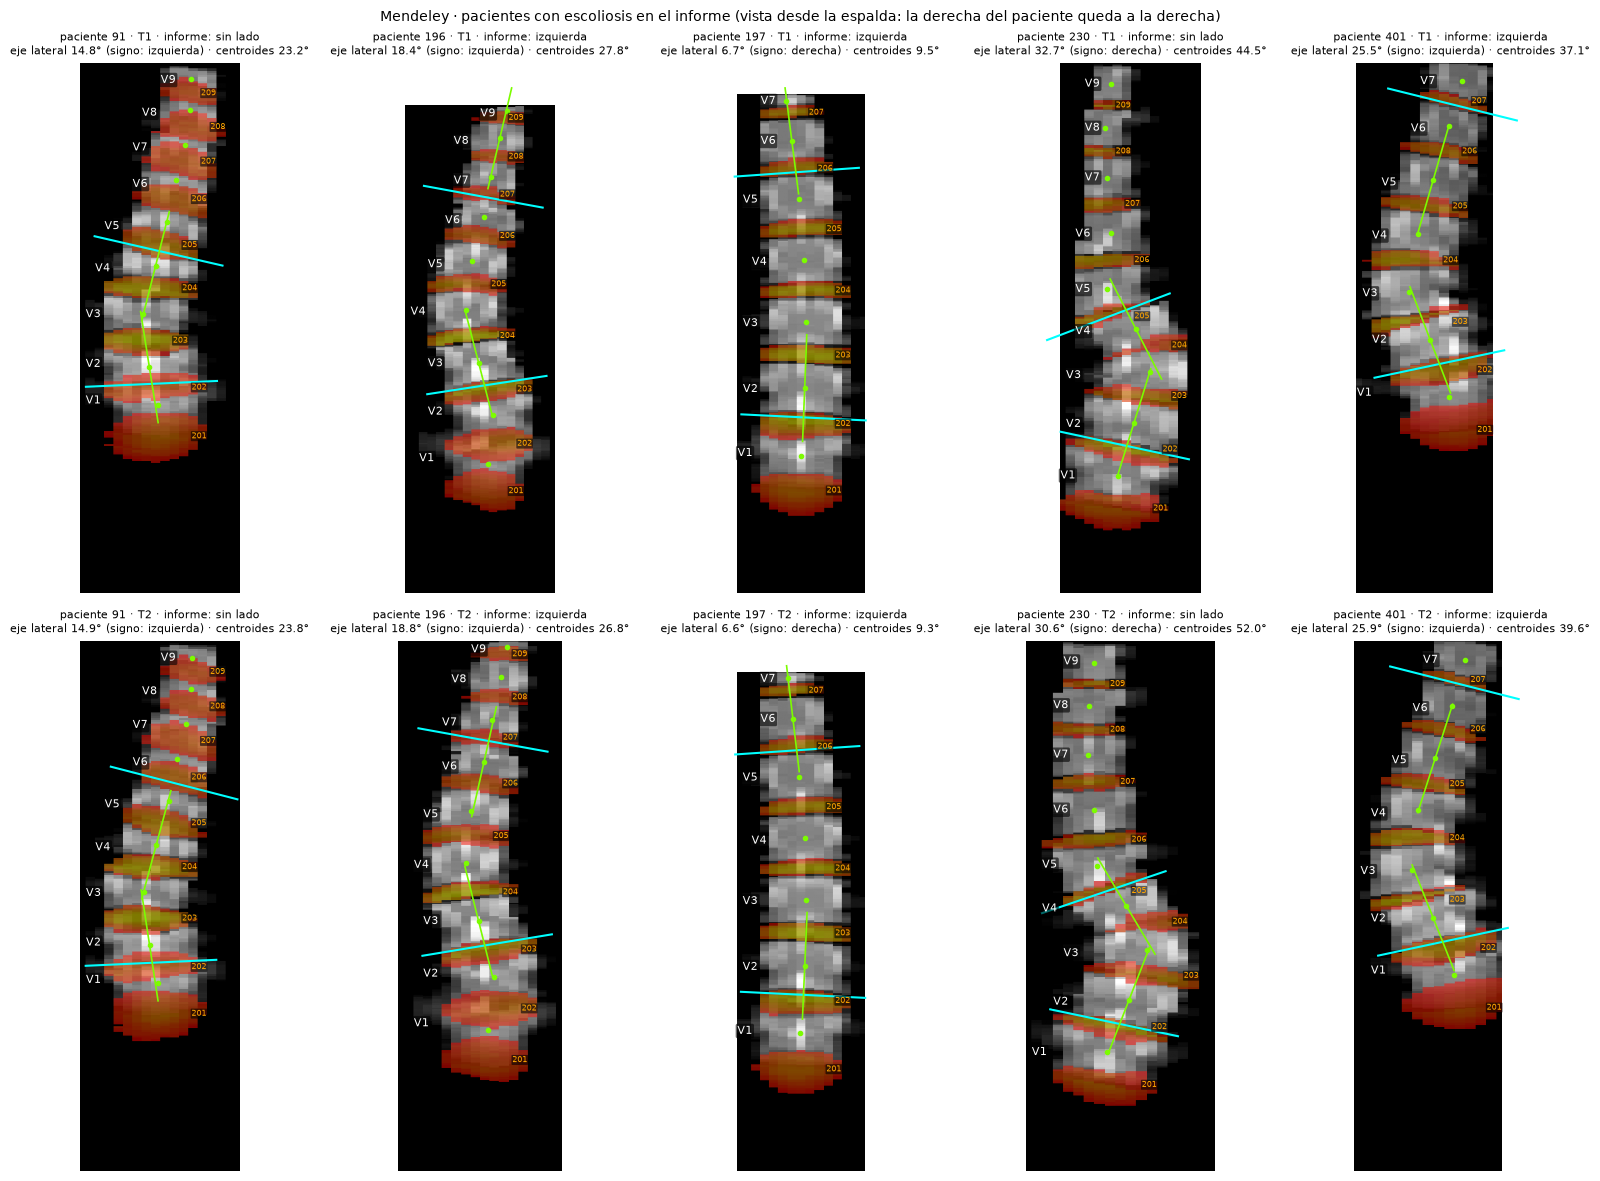

In [ ]:
# 21. Análisis 6: notas de los radiólogos de Mendeley (comprobaciones, posición, AUC, lado y panel)
import re
notas = pd.read_csv(CSV_NOTAS_MENDELEY)
notas["id"] = pd.to_numeric(notas["Patient ID"], errors="coerce")
texto = notas.set_index("id")["Clinician's Notes"].fillna("").astype(str)
carpetas = set(series_m["paciente"].astype(int))
informes = set(notas["id"].dropna().astype(int))
sin_carpeta = informes - carpetas
faltan = set(range(1, max(informes) + 1)) - carpetas
correspondencia = {"informes": len(notas), "ids_unicos": bool(notas["id"].is_unique),
                   "ids_del_1_al_n": informes == set(range(1, len(notas) + 1)), "carpetas_con_imagenes": len(carpetas),
                   "carpetas_sin_informe": len(carpetas - informes), "informes_sin_carpeta": len(sin_carpeta),
                   "numeros_de_carpeta_que_faltan": len(faltan),
                   "informes_sin_carpeta_igual_a_carpetas_que_faltan": sin_carpeta == faltan}
normalizado = texto.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
repetidos = normalizado[normalizado.duplicated(keep=False) & (normalizado != "")]
grupos_repetidos = repetidos.groupby(repetidos).apply(lambda s: sorted(int(i) for i in s.index)).tolist()
conv = leer(CSV_CONVERSION_MENDELEY)
huellas = {e: set(conv.loc[conv["estudio"] == e, "huella_volumen"].dropna()) for e in ("0196", "0197")}
duplicado = {"textos_196_197_identicos": bool(normalizado.get(196) == normalizado.get(197)),
             "huellas_de_volumen_en_comun": len(huellas["0196"] & huellas["0197"]),
             "series_0196": len(huellas["0196"]), "series_0197": len(huellas["0197"]),
             "sexo_edad_0196": " ".join(map(str, paciente.loc["0196", ["sexo", "edad"]])) if "0196" in paciente.index else "",
             "sexo_edad_0197": " ".join(map(str, paciente.loc["0197", ["sexo", "edad"]])) if "0197" in paciente.index else "",
             "otros_grupos_de_informes_con_texto_identico": [g for g in grupos_repetidos if g != [196, 197]]}
print("Correspondencia informe–carpeta:", correspondencia)
print("Informes 196 y 197:", duplicado)
(DIR_SALIDA / "analisis6_comprobaciones_informes.json").write_text(
    json.dumps({"correspondencia": correspondencia, "duplicado_196_197": duplicado}, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8")

def lado_del_informe(t):
    m = re.search(r"convex\w*\s+(?:to\s+)?(?:the\s+)?(left|right|lt|rt)", t, re.IGNORECASE)   # el 401 dice "Ltside"
    return None if not m else ("izquierda" if m.group(1).lower() in ("left", "lt") else "derecha")

menciones = pd.read_csv(CSV_MENCIONES_MENDELEY)
con_escoliosis = sorted(set(pd.to_numeric(menciones["primera_columna"], errors="coerce").dropna().astype(int)))
casos = pd.DataFrame({"paciente": con_escoliosis, "estudio": [f"{p:04d}" for p in con_escoliosis],
                      "lado_informe": [lado_del_informe(texto.get(p, "")) for p in con_escoliosis]})
print("Pacientes con escoliosis en el informe:", casos.to_dict("records"))

filas, filas_auc = [], []
for sub in SUBCONJUNTOS:
    for clase in ("T1", "T2"):
        for f in [*F_CORTO, "centroides"]:
            col = f"angulo_{f}_{clase}"
            t = grupo("mendeley", sub, [col])
            a = t[col].astype(float)
            positivo = a.index.isin(casos["estudio"])
            pos, neg = a[positivo].to_numpy(), a[~positivo].to_numpy()
            auc = float(((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean()) if len(pos) and len(neg) else np.nan
            filas_auc.append({"subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F.get(f, f), "estudios": len(a),
                              "casos_presentes": int(positivo.sum()), "auc_exacta": auc})
            posicion = a.rank(ascending=False, method="min")
            for r in casos.itertuples():
                fila = {"subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F.get(f, f), "paciente": r.paciente,
                        "lado_informe": r.lado_informe, "estudios": len(a), "en_el_grupo": r.estudio in a.index}
                if r.estudio in a.index:
                    con_signo = t.loc[r.estudio, f"con_signo_{f}_{clase}"]
                    fila.update({"angulo": a[r.estudio], "posicion": int(posicion[r.estudio]),
                                 "percentil": stats.percentileofscore(a, a[r.estudio], kind="strict"),
                                 "lado_por_signo": lado_del_signo(np.array([float(con_signo)]))[0]})
                    if f in F_CORTO:
                        fila["piso_de_ruido"] = angulos.set_index("id_serie").loc[t.loc[r.estudio, f"id_serie_{clase}"], f"piso_{f}_{sub}"]
                    fila["lado_coincide"] = (None if pd.isna(r.lado_informe) else fila["lado_por_signo"] == r.lado_informe)
                filas.append(fila)
posiciones = pd.DataFrame(filas)
auc6 = pd.DataFrame(filas_auc)
posiciones.to_csv(DIR_SALIDA / "analisis6_pacientes_con_escoliosis_en_el_informe.csv", index=False)   # Mendeley es CC BY
auc6.to_csv(DIR_SALIDA / "analisis6_auc_descriptiva.csv", index=False)
print("Posición de los pacientes con escoliosis en el informe, conjunto completo, fórmula principal:")
display(posiciones[(posiciones["subconjunto"] == "completo") & (posiciones["formula"] == NOMBRE_F[PRINCIPAL])]
        .drop(columns=["subconjunto", "formula"]).round(2))
print("AUC exacta (solo descriptiva):")
display(auc6.pivot_table(index="formula", columns=["subconjunto", "secuencia"], values="auc_exacta").round(3))

def dibujar_tangentes(ax, cent, v_max, v_min, color="#7CFC00"):
    c = cent.set_index("vertebra").sort_index()
    orden = list(c.index)
    for v in (v_max, v_min):
        if np.isnan(v):
            continue
        k = orden.index(v)
        d = c.iloc[k + 1][["cx", "cz"]].to_numpy(float) - c.iloc[k - 1][["cx", "cz"]].to_numpy(float)
        d /= np.linalg.norm(d)
        p = c.loc[v, ["cx", "cz"]].to_numpy(float)
        ax.plot([p[0] - 60 * d[0], p[0] + 60 * d[0]], [p[1] - 60 * d[1], p[1] + 60 * d[1]], color=color, lw=1.2)

def panel_de_serie(ax, id_serie, titulo):
    "Proyección coronal con el par de la fórmula principal (cian), los centroides y sus tangentes (verde) y las etiquetas."
    ruta = extraer([id_serie], DIR_LOCAL / "panel")[0]
    mascara = en_espacio_del_script(ruta)
    vert, disc = proyeccion_coronal(mascara)
    ax.imshow(vert.T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_equal(disc.T, 0), cmap="autumn", alpha=0.5, origin="lower")
    c = caras[caras["id_serie"] == id_serie]
    _, a, b = regla_articulo(tabla_de_caras(c, F_CORTO[PRINCIPAL]))
    if not np.isnan(a):
        dibujar_cara(ax, c[(c["disco"] == a) & (c["cara"] == "superior")].iloc[0], "cyan")
        dibujar_cara(ax, c[(c["disco"] == b) & (c["cara"] == "inferior")].iloc[0], "cyan")
    cent = centroides[centroides["id_serie"] == id_serie]
    if len(cent):
        ax.plot(cent["cx"], cent["cz"], "o", color="#7CFC00", ms=3)
        _, v_max, v_min = angulo_por_centroides(cent)
        dibujar_tangentes(ax, cent, v_max, v_min)
    ax.invert_xaxis()
    rotular_vertebras(ax, mascara)
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")

fig, axes = plt.subplots(2, len(casos), figsize=(3.4 * len(casos), 12), squeeze=False)
for k, r in enumerate(casos.itertuples()):
    for fila_ax, clase in enumerate(("T1", "T2")):
        ax = axes[fila_ax, k]
        i = ancho.loc[("mendeley", r.estudio), f"id_serie_{clase}"] if ("mendeley", r.estudio) in ancho.index else np.nan
        if pd.isna(i) or i not in indice_mascaras:
            ax.set_title(f"paciente {r.paciente} · {clase}\nsin máscara", fontsize=8); ax.axis("off")
            continue
        s = angulos.set_index("id_serie").loc[i]
        lado = lado_del_signo(np.array([s[f"con_signo_{PRINCIPAL}"]]))[0]
        panel_de_serie(ax, i, f"paciente {r.paciente} · {clase} · informe: {'sin lado' if pd.isna(r.lado_informe) else r.lado_informe}\n"
                              f"eje lateral {s[f'angulo_{PRINCIPAL}']:.1f}° (signo: {lado}) · centroides {s['angulo_centroides']:.1f}°")
fig.suptitle("Mendeley · pacientes con escoliosis en el informe (vista desde la espalda: la derecha del paciente queda a la derecha)",
             fontsize=10)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "analisis6_panel_pacientes_con_escoliosis.png", dpi=110, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 21.** Las primeras líneas resumen las dos comprobaciones. En la correspondencia informe–carpeta, `informes_sin_carpeta_igual_a_carpetas_que_faltan` debe ser verdadero para que la numeración sea consistente. En la revisión de los informes 196 y 197, `textos_196_197_identicos` indica si ambos textos coinciden y `huellas_de_volumen_en_comun` señala si alguna serie de una carpeta tiene la misma huella que una serie de la otra. El sexo y la edad, obtenidos de las cabeceras DICOM, aportan información adicional para determinar si las carpetas corresponden a una misma persona. Al final se muestran otros grupos de informes que comparten exactamente el mismo texto. Estas comprobaciones no resuelven por sí solas qué informe corresponde a cada estudio; permiten valorar la confiabilidad de la comparación.

La tabla de pacientes contiene una fila por paciente y secuencia, con la fórmula principal y el conjunto completo. `posicion` es el lugar que ocupa el ángulo entre todos los estudios, donde 1 corresponde al mayor valor. `percentil` indica el porcentaje de estudios con un ángulo inferior. `piso_de_ruido` corresponde al valor simulado para esa serie y `lado_coincide` indica si el signo del ángulo concuerda con el lado descrito en el informe. Si el ángulo está por debajo del piso de ruido, el signo no debe interpretarse como evidencia del lado de la curva, porque podría depender del error.

La tabla de AUC utiliza una escala en la que 0,5 representa ausencia de discriminación entre los dos grupos y 1 representa que todos los pacientes con mención de escoliosis tienen ángulos mayores que los demás. Dado el número reducido de casos y las limitaciones de los informes, este valor es exclusivamente descriptivo.

En el panel, cada columna corresponde a un paciente y muestra la T1 arriba y la T2 abajo. Las líneas cian representan las caras seleccionadas por la fórmula principal; los puntos verdes, los centroides; y las rectas verdes, las tangentes del estimador de centroides. Cada vértebra conserva su etiqueta de SPIDER (V1 es la más caudal de la máscara) y cada disco su número. La imagen está invertida horizontalmente y se observa desde la espalda del paciente; por ello, una convexidad hacia la izquierda del paciente aparece hacia la izquierda de la imagen.

### Análisis 7 · Factores de adquisición

La celda 22 estudia si el acuerdo entre T1 y T2 cambia según cuatro características de adquisición: grosor de corte, espaciado entre cortes sagitales, tamaño del píxel en el plano y cobertura lateral, esta última expresada como el número de cortes multiplicado por su espaciado. El grosor se obtiene de las cabeceras DICOM y de los inventarios de imágenes de RSNA y Mendeley. El espaciado, el tamaño del píxel y la cobertura proceden de la geometría de las máscaras registrada en el cuaderno 09.

Para cada factor se calcula la correlación de Spearman con la diferencia absoluta entre los ángulos T1 y T2. Además, los estudios se agrupan en cuartiles del factor medido en cada secuencia. En cada grupo se describen el sesgo, el ancho de los límites de acuerdo, la mediana de la diferencia absoluta y el ángulo mediano. Este enfoque permite observar si un factor parece relacionarse con el desacuerdo, con el tamaño del ángulo o con ambos.

En RSNA también se analiza la huella gruesa de protocolo definida en el cuaderno 09, que combina la matriz de la imagen con el paso entre cortes redondeado a 0,5 mm. Solo se presentan las huellas con al menos 20 estudios, para evitar mostrar grupos demasiado pequeños. Una misma huella no identifica necesariamente una institución: distintos centros pueden compartir parámetros y un centro puede utilizar más de un protocolo. Los resultados de este análisis son descriptivos.

In [ ]:
# 22. Análisis 7: factores de adquisición y huella de protocolo gruesa de RSNA (descriptivo)
img_rsna = pd.read_csv(CSV_IMAGENES_RSNA, dtype=str, usecols=["study_id", "series_id", "SliceThickness"])
grosor_rsna = (img_rsna.assign(grosor=pd.to_numeric(img_rsna["SliceThickness"], errors="coerce"))
               .groupby(["study_id", "series_id"])["grosor"].median())
grosor_men = series_m.assign(grosor=pd.to_numeric(series_m["grosor_mm"], errors="coerce")).groupby(["paciente", "serie_clave"])["grosor"].first()
fac = angulos[["id_serie", "conjunto", "estudio", "clase", "serie_clave"]].copy()
rec = recorrido_09.reindex(fac["id_serie"])
fac["espaciado_mm"] = rec["esp_lr"].to_numpy(float)
fac["pixel_mm"] = ((rec[["esp_x", "esp_y", "esp_z"]].sum(axis=1) - rec["esp_lr"]) / 2).to_numpy(float)
fac["cobertura_lateral_mm"] = (rec["cortes_lr"] * rec["esp_lr"]).to_numpy(float)
fac["grosor_mm"] = [grosor_rsna.get((e, s), np.nan) if c == "rsna" else grosor_men.get((e, s), np.nan)
                    for c, e, s in zip(fac["conjunto"], fac["estudio"], fac["serie_clave"])]
fac["huella_gruesa"] = fac["id_serie"].map(huella_rsna["huella_gruesa"])
fac.to_csv(DIR_PRIV / "factores_por_serie.csv", index=False)
FACTORES = ["grosor_mm", "espaciado_mm", "pixel_mm", "cobertura_lateral_mm"]
fac_ancho = fac.set_index(["conjunto", "estudio", "clase"])[FACTORES + ["huella_gruesa"]].unstack("clase")
fac_ancho.columns = [f"{c}_{clase}" for c, clase in fac_ancho.columns]
print("Factores sin dato (% de series):", fac.groupby("conjunto")[FACTORES].apply(lambda g: (100 * g.isna().mean()).round(1)).to_dict("index"))

def acuerdo_descriptivo(t, f):
    d = (t[f"angulo_{f}_T2"] - t[f"angulo_{f}_T1"]).astype(float)
    return {"estudios": len(d), "sesgo": d.mean(), "ancho_limites": 2 * 1.96 * d.std(ddof=1), "mediana_abs_dif": d.abs().median()}

filas, filas_rho, filas_huella = [], [], []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        t0 = grupo(conjunto, sub, PARES_ANGULO).join(fac_ancho.loc[conjunto])
        for factor in FACTORES:
            for clase in ("T1", "T2"):
                col = f"{factor}_{clase}"
                t = t0.dropna(subset=[col])
                if t[col].nunique() < 2:
                    continue
                tramos = pd.qcut(t[col], 4, duplicates="drop")
                for f in F_CORTO:
                    d_abs = (t[f"angulo_{f}_T2"] - t[f"angulo_{f}_T1"]).abs().astype(float)
                    rho = stats.spearmanr(t[col].astype(float), d_abs).statistic
                    filas_rho.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "factor": factor, "secuencia_del_factor": clase,
                                      "formula": NOMBRE_F[f], "estudios": len(t), "spearman_factor_vs_abs_dif": rho})
                    for tramo, g in t.groupby(tramos, observed=True):
                        filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "factor": factor, "secuencia_del_factor": clase,
                                      "formula": NOMBRE_F[f], "cuartil": str(tramo), **acuerdo_descriptivo(g, f),
                                      "angulo_mediano_de_la_secuencia": g[f"angulo_{f}_{clase}"].astype(float).median(),
                                      "ge10_pct_de_la_secuencia": 100 * (g[f"angulo_{f}_{clase}"].astype(float) >= UMBRAL_ANGULO).mean()})
        if conjunto == "rsna":
            for clase in ("T1", "T2"):
                col = f"huella_gruesa_{clase}"
                frec = t0[col].value_counts()
                for huella, g in t0[t0[col].isin(frec[frec >= 20].index)].groupby(col):
                    for f in F_CORTO:
                        filas_huella.append({"subconjunto": sub, "secuencia_de_la_huella": clase, "huella_gruesa": huella,
                                             "formula": NOMBRE_F[f], **acuerdo_descriptivo(g, f),
                                             "angulo_mediano_T1": g[f"angulo_{f}_T1"].astype(float).median(),
                                             "ge10_pct_T1": 100 * (g[f"angulo_{f}_T1"].astype(float) >= UMBRAL_ANGULO).mean()})
factores_cuartiles = pd.DataFrame(filas)
factores_rho = pd.DataFrame(filas_rho)
huellas_tabla = pd.DataFrame(filas_huella)
factores_cuartiles.to_csv(DIR_SALIDA / "analisis7_factores_por_cuartil.csv", index=False)
factores_rho.to_csv(DIR_SALIDA / "analisis7_factores_spearman.csv", index=False)
huellas_tabla.to_csv(DIR_SALIDA / "analisis7_rsna_huellas_con_20_o_mas_estudios.csv", index=False)
print("Spearman entre cada factor y |T2 − T1|, fórmula principal, conjunto completo:")
display(factores_rho[(factores_rho["formula"] == NOMBRE_F[PRINCIPAL]) & (factores_rho["subconjunto"] == "completo")]
        .pivot_table(index=["factor", "secuencia_del_factor"], columns="conjunto", values="spearman_factor_vs_abs_dif").round(3))
print("Acuerdo por cuartil del factor de la T1, fórmula principal, conjunto completo:")
display(factores_cuartiles[(factores_cuartiles["formula"] == NOMBRE_F[PRINCIPAL]) & (factores_cuartiles["subconjunto"] == "completo")
                           & (factores_cuartiles["secuencia_del_factor"] == "T1")]
        .drop(columns=["subconjunto", "formula", "secuencia_del_factor"]).round(2))
if len(huellas_tabla):
    h = huellas_tabla[(huellas_tabla["formula"] == NOMBRE_F[PRINCIPAL]) & (huellas_tabla["subconjunto"] == "completo")]
    print("RSNA, huellas de protocolo gruesas con 20 estudios o más (fórmula principal, conjunto completo):")
    display(h.drop(columns=["subconjunto", "formula"]).sort_values(["secuencia_de_la_huella", "estudios"], ascending=[True, False]).round(2))

Factores sin dato (% de series): {'mendeley': {'grosor_mm': 0.0, 'espaciado_mm': 0.5, 'pixel_mm': 0.5, 'cobertura_lateral_mm': 0.5}, 'rsna': {'grosor_mm': 0.0, 'espaciado_mm': 0.0, 'pixel_mm': 0.0, 'cobertura_lateral_mm': 0.0}}
Spearman entre cada factor y |T2 − T1|, fórmula principal, conjunto completo:


conjunto                                   Mendeley   RSNA
factor               secuencia_del_factor                 
cobertura_lateral_mm T1                      -0.010  0.058
                     T2                       0.054  0.058
espaciado_mm         T1                       0.015  0.003
                     T2                       0.055  0.003
grosor_mm            T1                         NaN  0.070
                     T2                       0.001  0.067
pixel_mm             T1                       0.177  0.071
                     T2                       0.015  0.029

Acuerdo por cuartil del factor de la T1, fórmula principal, conjunto completo:


,conjunto,factor,cuartil,estudios,sesgo,ancho_limites,mediana_abs_dif,angulo_mediano_de_la_secuencia,ge10_pct_de_la_secuencia
6,Mendeley,espaciado_mm,"(1.5272725999999999, 4.7999997]",191,-0.09,3.49,0.45,4.26,4.71
7,Mendeley,espaciado_mm,"(4.7999997, 4.8000002]",319,0.04,3.14,0.46,3.96,3.76
21,Mendeley,pixel_mm,"(0.437, 0.875]",508,-0.01,3.28,0.46,4.10,4.13
22,Mendeley,pixel_mm,"(0.875, 0.906]",2,0.17,0.92,0.17,4.38,0.00
33,Mendeley,cobertura_lateral_mm,"(52.800001, 71.999996]",214,-0.05,3.58,0.45,4.15,4.67
34,Mendeley,cobertura_lateral_mm,"(71.999996, 72.000003]",296,0.02,3.04,0.46,4.02,3.72
84,RSNA,grosor_mm,"(2.999, 4.0]",1858,-0.10,4.01,0.52,5.23,14.69
85,RSNA,grosor_mm,"(4.0, 5.5]",113,0.03,3.14,0.44,5.80,21.24
96,RSNA,espaciado_mm,"(2.999, 4.4]",494,-0.00,3.70,0.48,5.65,19.84
97,RSNA,espaciado_mm,"(4.4, 4.48]",558,-0.30,4.40,0.61,5.39,16.67


RSNA, huellas de protocolo gruesas con 20 estudios o más (fórmula principal, conjunto completo):


,secuencia_de_la_huella,huella_gruesa,estudios,sesgo,ancho_limites,mediana_abs_dif,angulo_mediano_T1,ge10_pct_T1
30,T1,512x512|4.5,375,-0.32,4.82,0.62,5.40,15.73
33,T1,512x512|5.0,302,0.03,4.02,0.47,5.03,12.91
18,T1,384x384|4.5,223,0.05,4.15,0.56,4.70,7.17
21,T1,384x384|5.0,114,-0.02,3.95,0.50,5.08,7.89
48,T1,760x640|3.5,89,-0.04,3.15,0.42,5.71,10.11
0,T1,256x256|4.5,88,-0.32,3.09,0.57,6.49,27.27
27,T1,512x512|4.0,84,0.02,4.75,0.63,5.36,13.10
12,T1,320x320|5.0,79,-0.10,3.26,0.53,5.64,16.46
9,T1,320x320|4.5,73,-0.08,3.08,0.49,4.57,19.18
6,T1,320x320|4.0,70,-0.06,3.66,0.60,9.66,48.57


**Cómo leer la salida de la celda 22.** La primera línea indica el porcentaje de series sin información para cada factor. La primera tabla presenta la correlación de Spearman entre cada característica —medida en T1 o T2— y la diferencia absoluta T1–T2 del ángulo. Una correlación positiva indica que el desacuerdo tiende a aumentar a medida que crece el factor; una correlación próxima a cero indica que no se observa una relación monotónica clara.

La segunda tabla agrupa los estudios en cuartiles del factor medido en T1 y resume, para cada grupo, el sesgo, el ancho de los límites de acuerdo, la mediana de la diferencia absoluta y la distribución del ángulo de T1. Así se puede distinguir si un factor parece acompañarse de cambios en el desacuerdo o de diferencias en los propios ángulos. Cuando el factor toma pocos valores como puede ocurrir con el grosor de corte, los cuartiles pueden agruparse y quedar menos de cuatro categorías.

La última tabla presenta el acuerdo y la distribución del ángulo para cada huella gruesa de protocolo de RSNA con al menos 20 estudios. Las diferencias entre huellas deben leerse como patrones descriptivos; no demuestran por sí solas un efecto causal del protocolo.

### Análisis 8 · Caras de disco frente a centroides vertebrales

Los dos estimadores utilizan información anatómica distinta. El ángulo por caras de disco se basa en la orientación de las superficies superior e inferior de los discos. El estimador de centroides utiliza la trayectoria de los centros de los cuerpos vertebrales y las tangentes calculadas a partir de ellos.

Si ambos describen una dimensión común de la curvatura, se esperaría que sus resultados estuvieran asociados, aunque no necesariamente que produjeran el mismo valor. La celda 23 compara, por conjunto, secuencia, subconjunto y fórmula, la correlación de Spearman con intervalo de confianza por remuestreo de estudios, la diferencia media entre centroides y caras, los límites de acuerdo y la mediana de la diferencia absoluta.

El análisis es descriptivo. Ninguno de los dos estimadores se considera una referencia válida frente a la cual juzgar al otro.

,conjunto,subconjunto,secuencia,estudios,spearman,spearman_ic95_inf,spearman_ic95_sup,dif_media_centroides_menos_caras,lim_inf,lim_sup,mediana_abs_dif
0,Mendeley,completo,T1,515,0.463,0.389,0.532,1.453,-5.287,8.194,2.058
3,Mendeley,completo,T2,508,0.447,0.371,0.517,1.596,-4.552,7.744,2.082
6,Mendeley,sin_marcas,T1,349,0.470,0.381,0.550,1.427,-3.841,6.694,1.994
9,Mendeley,sin_marcas,T2,349,0.446,0.358,0.529,1.633,-4.032,7.298,2.075
12,RSNA,completo,T1,1972,0.696,0.667,0.722,2.063,-5.288,9.414,2.154
15,RSNA,completo,T2,1974,0.690,0.662,0.717,2.046,-5.621,9.714,2.140
18,RSNA,sin_marcas,T1,1236,0.714,0.678,0.746,2.113,-4.989,9.214,2.205
21,RSNA,sin_marcas,T2,1236,0.720,0.686,0.749,2.087,-5.065,9.239,2.186


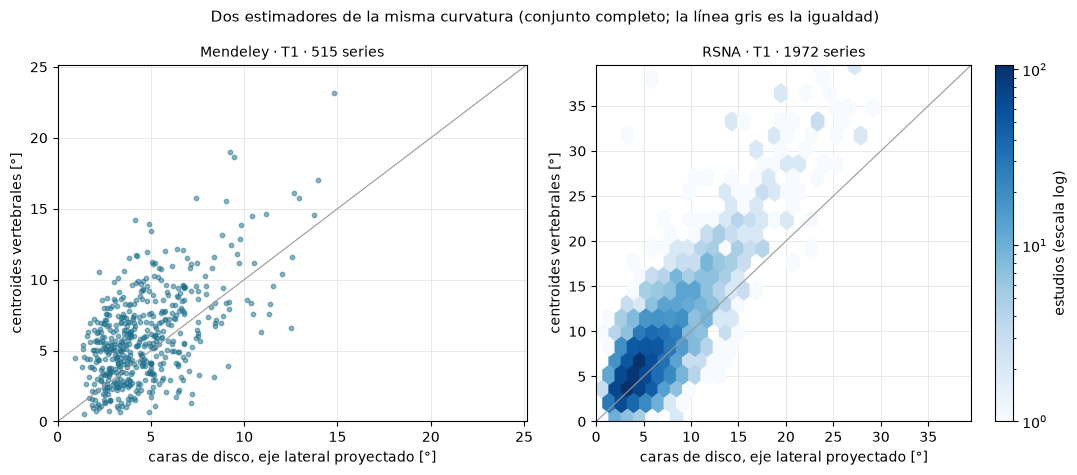

In [ ]:
# 23. Análisis 8: ángulo por caras de disco frente al estimador de centroides
filas = []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        for clase in ("T1", "T2"):
            for f in F_CORTO:
                t = grupo(conjunto, sub, [f"angulo_{f}_{clase}", f"angulo_centroides_{clase}"])
                x, y = t[f"angulo_{f}_{clase}"].to_numpy(float), t[f"angulo_centroides_{clase}"].to_numpy(float)
                if len(t) < 3:
                    continue
                idx = indices_bootstrap(len(t))
                rho = stats.spearmanr(x, y).statistic
                rx, ry = stats.rankdata(x[idx], axis=1), stats.rankdata(y[idx], axis=1)
                rho_boot = [np.corrcoef(a, b)[0, 1] for a, b in zip(rx, ry)]
                d = y - x
                filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F[f],
                              "estudios": len(t), "spearman": rho, "spearman_ic95_inf": ic95(rho_boot)[0],
                              "spearman_ic95_sup": ic95(rho_boot)[1], "dif_media_centroides_menos_caras": d.mean(),
                              "lim_inf": d.mean() - 1.96 * d.std(ddof=1), "lim_sup": d.mean() + 1.96 * d.std(ddof=1),
                              "mediana_abs_dif": np.median(np.abs(d))})
convergente = pd.DataFrame(filas)
convergente.to_csv(DIR_SALIDA / "analisis8_caras_frente_a_centroides.csv", index=False)
display(convergente[convergente["formula"] == NOMBRE_F[PRINCIPAL]].drop(columns="formula").round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, conjunto in zip(axes, CONJUNTOS):
    t = grupo(conjunto, "completo", [f"angulo_{PRINCIPAL}_T1", "angulo_centroides_T1"])
    x, y = t[f"angulo_{PRINCIPAL}_T1"].astype(float), t["angulo_centroides_T1"].astype(float)
    if conjunto == "rsna":
        hb = ax.hexbin(x, y, gridsize=40, mincnt=1, cmap="Blues", bins="log")
        fig.colorbar(hb, ax=ax, label="estudios (escala log)")
    else:
        ax.scatter(x, y, s=10, alpha=0.5, color="#1f6f8b")
    lim = float(np.nanpercentile(np.r_[x, y], 99.5)) if len(t) else 10
    ax.plot([0, lim], [0, lim], color="#999999", lw=0.8)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"{CONJUNTOS[conjunto]} · T1 · {len(t)} series", fontsize=10)
    ax.set_xlabel("caras de disco, eje lateral proyectado [°]"); ax.set_ylabel("centroides vertebrales [°]")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Dos estimadores de la misma curvatura (conjunto completo; la línea gris es la igualdad)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "analisis8_caras_frente_a_centroides.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 23.** Cada fila compara ambos estimadores para un conjunto, subconjunto y secuencia, utilizando la fórmula principal. Los resultados de las otras fórmulas se encuentran en el archivo CSV. `spearman` indica si los estudios con ángulos mayores por caras de disco también tienden a tener ángulos mayores por centroides; se presenta junto con su intervalo de confianza.

`dif_media_centroides_menos_caras` cuantifica la diferencia media en grados. `lim_inf` y `lim_sup` muestran los límites de acuerdo entre los estimadores, y `mediana_abs_dif` resume la magnitud típica de sus diferencias. No se espera necesariamente que los valores coincidan: los centroides describen la trayectoria de los cuerpos vertebrales, mientras que las caras describen la orientación local de los discos, y cada procedimiento selecciona sus extremos de manera distinta.

En la figura, cada punto de Mendeley es una serie T1; en RSNA, cada celda coloreada agrupa las series T1 que caen en esa zona. La línea gris indica la igualdad entre estimadores. Una tendencia creciente de los puntos, incluso si se sitúan por encima o por debajo de esa línea, indica que ambos resultados varían en la misma dirección, aunque exista una diferencia de escala o un sesgo.

## Análisis exploratorios

Los análisis de esta sección no formaban parte del plan registrado. Se presentan por separado para distinguirlos de los análisis confirmatorios y evitar que se interpreten como hipótesis definidas antes de observar los resultados.

El primer análisis retoma una observación del cuaderno 09. En aquel cuaderno, la T2 coincidió con los niveles de RSNA en el 97,1 % de los estudios, frente al 89,0 % de la T1. Sin embargo, al proyectar los puntos de T2/STIR sobre la máscara T1, la coincidencia fue del 96,4 %. Esto sugería que la diferencia podía deberse principalmente al tipo de punto marcado y no a la máscara utilizada. La celda 24 contrasta ambas explicaciones mediante el mismo criterio de coincidencia del cuaderno 09.

La comparación principal mantiene los puntos de T2/STIR y cambia únicamente la máscara: primero se utilizan con la máscara T2 y después con la máscara T1 del mismo estudio. El segundo contraste mantiene fija la máscara T1 y cambia el tipo de punto, comparando los puntos de T1 con los de T2/STIR. Las diferencias se calculan sobre los mismos estudios y se acompañan de intervalos de confianza por remuestreo pareado (2.000 remuestreos, semilla 2026). Este análisis no utiliza ángulos.

El segundo análisis calcula el acuerdo T1–T2 del estimador de centroides con el mismo procedimiento del análisis 1. Permite describir su repetibilidad y compararla con la del estimador por caras de disco, algo que el análisis 8 por sí solo no permite establecer.

La comparación del estimador de centroides con diferencias centrales frente a una curva ajustada mediante *spline* cúbico se deja para un cuaderno posterior.

In [ ]:
# 24. Exploratorios: tipo de punto de RSNA y acuerdo T1–T2 del estimador de centroides
niveles = leer(CSV_NIVELES_09)
niveles = niveles[(pd.to_numeric(niveles["niveles_marcados"], errors="coerce") == 5) & es_verdadero(niveles["con_mascara"])]
niveles["cinco"] = es_verdadero(niveles["cinco_coinciden"]).astype(float)
combinacion = niveles.pivot_table(index="estudio", columns=["clase_puntos", "clase_mascara"], values="cinco", aggfunc="first")

def diferencia_pareada(a, b):
    "Media de a − b en los estudios con los dos valores, con IC por remuestreo pareado de estudios."
    t = pd.concat([a, b], axis=1).dropna()
    d = (t.iloc[:, 0] - t.iloc[:, 1]).to_numpy(float)
    idx = indices_bootstrap(len(d))
    lo, hi = ic95(d[idx].mean(axis=1))
    return {"estudios": len(d), "proporcion_a": t.iloc[:, 0].mean(), "proporcion_b": t.iloc[:, 1].mean(),
            "diferencia_a_menos_b": d.mean(), "ic95_inf": lo, "ic95_sup": hi}

COMBOS = {("T2", "T2"): "puntos T2/STIR, máscara T2", ("T2", "T1"): "puntos T2/STIR, máscara T1", ("T1", "T1"): "puntos T1, máscara T1"}
faltan_combos = [c for c in COMBOS if c not in combinacion.columns]
assert not faltan_combos, f"Faltan combinaciones en niveles_rsna_por_serie.csv: {faltan_combos}"
tipo_punto = pd.DataFrame([
    {"comparacion": "misma T2/STIR de puntos: máscara T2 − máscara T1 (solo cambia la máscara)",
     **diferencia_pareada(combinacion[("T2", "T2")], combinacion[("T2", "T1")])},
    {"comparacion": "misma máscara T1: puntos T1 − puntos T2/STIR (solo cambia el tipo de punto)",
     **diferencia_pareada(combinacion[("T1", "T1")], combinacion[("T2", "T1")])}])
tipo_punto.to_csv(DIR_SALIDA / "exploratorio_tipo_de_punto_rsna.csv", index=False)
print("Coincidencia de los cinco niveles con RSNA (proporción de estudios):")
display(tipo_punto.round(4))

filas = []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        t = grupo(conjunto, sub, ["angulo_centroides_T1", "angulo_centroides_T2"])
        if len(t) < 3:
            continue
        t1, t2 = t["angulo_centroides_T1"].to_numpy(float), t["angulo_centroides_T2"].to_numpy(float)
        idx = indices_bootstrap(len(t))
        punto, boot = medidas_de_acuerdo(t1, t2), medidas_de_acuerdo(t1[idx], t2[idx])
        fila = {"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "estimador": "centroides", "estudios": len(t)}
        for m in punto:
            lo, hi = ic95(boot[m])
            fila.update({m: float(punto[m]), f"{m}_ic95_inf": lo, f"{m}_ic95_sup": hi})
        filas.append(fila)
acuerdo_centroides = pd.DataFrame(filas)
acuerdo_centroides.to_csv(DIR_SALIDA / "exploratorio_acuerdo_t1_t2_centroides.csv", index=False)
print("Acuerdo T1–T2 del estimador de centroides (estudios con el ángulo de centroides en las dos secuencias):")
display(acuerdo_centroides[[c for c in COLS_VISTA if c != "formula"]].round(3))

Coincidencia de los cinco niveles con RSNA (proporción de estudios):


,comparacion,estudios,proporcion_a,proporcion_b,diferencia_a_menos_b,ic95_inf,ic95_sup
0,misma T2/STIR de puntos: máscara T2 − máscara ...,1895,0.9710,0.9641,0.0069,0.0021,0.0116
1,misma máscara T1: puntos T1 − puntos T2/STIR (...,1895,0.8939,0.9641,-0.0702,-0.0844,-0.0559


Acuerdo T1–T2 del estimador de centroides (estudios con el ángulo de centroides en las dos secuencias):


,conjunto,subconjunto,estudios,sesgo,lim_inf,lim_sup,ancho_limites,ancho_limites_ic95_inf,ancho_limites_ic95_sup,coef_repetibilidad,icc_a1,icc_a1_ic95_inf,icc_a1_ic95_sup
0,Mendeley,completo,508,0.142,-4.220,4.504,8.725,4.174,13.435,4.367,0.876,0.724,0.967
1,Mendeley,sin_marcas,349,0.188,-2.291,2.667,4.957,3.306,6.604,2.502,0.931,0.877,0.970
2,RSNA,completo,1971,-0.108,-4.736,4.521,9.257,7.309,11.795,4.632,0.947,0.915,0.967
3,RSNA,sin_marcas,1235,-0.140,-3.772,3.493,7.265,6.585,7.915,3.642,0.968,0.958,0.975


**Cómo leer la salida de la celda 24.** En la primera tabla, `proporcion_a` y `proporcion_b` son las proporciones de estudios en los que coinciden los cinco niveles para cada condición. Ambas se calculan sobre los mismos estudios. `diferencia_a_menos_b` expresa la diferencia entre las proporciones y se acompaña de su intervalo de confianza.

Si la interpretación propuesta en el cuaderno 09 es correcta, la primera comparación en donde solo cambia la máscara debería mostrar una diferencia pequeña. La segunda en la que se mantiene la máscara T1 y cambia el tipo de punto debería mostrar una diferencia mayor. La segunda tabla presenta el acuerdo T1–T2 del estimador de centroides con las mismas medidas del análisis 1. Para compararlo con el estimador por caras, deben consultarse las filas de la fórmula principal de ese análisis. Los tamaños de muestra no son idénticos, porque el estimador de centroides requiere al menos cuatro vértebras válidas en ambas secuencias.

### Exploratorios agregados después de ver los resultados

Estos dos análisis se incorporaron el 1 de noviembre de 2026, después de revisar los resultados de los análisis registrados. Por tanto, son exploratorios en sentido estricto: responden a preguntas que surgieron al examinar los datos y no estaban previstas en el plan inicial.

La celda 24b profundiza en la interpretación de H1. El eje lateral proyectado produce ángulos sistemáticamente menores que $\arctan(n_x/n_z)$. La relación geométrica entre ambas medidas depende de la inclinación sagital de la cara: $\tan(\text{eje lateral})=\tan(\arctan(n_x/n_z))\cdot\cos^2\varphi$, donde $\varphi$ es esa inclinación. Por tanto, una fórmula puede producir límites de acuerdo más estrechos simplemente porque comprime la escala, sin que necesariamente reduzca el error relativo.

Para examinarlo, la celda divide la desviación estándar de las diferencias T2 − T1 entre la desviación estándar del ángulo medio de cada estudio. El cociente expresa la dispersión entre secuencias en relación con la variabilidad de los ángulos entre estudios. Si una fórmula fuera únicamente una versión multiplicada por una constante de otra, este cociente no cambiaría. Se informa con su intervalo de confianza y con la diferencia frente a la fórmula arctan, calculada usando los mismos remuestreos. También se presenta la mediana de la razón entre el ángulo de cada fórmula y el de arctan en T1, que permite describir la compresión de escala.

La celda 24c repite el análisis de posición y AUC de los informes de Mendeley excluyendo los estudios 0196 y 0197. Sus informes contienen el mismo texto, aunque las carpetas corresponden a personas distintas según el sexo y la edad registrados y no comparten huellas de volumen. Por ello, al menos uno de los informes podría no corresponder a su carpeta; con estos datos no es posible determinar cuál sin recurrir al propio ángulo. El análisis 6 registrado se conserva sin cambios.

In [ ]:
# 24b. Exploratorio (agregado después de ver los resultados): precisión de las tres fórmulas sin el efecto de la escala
def cociente_relativo(t1, t2):
    "DE de las diferencias T2 − T1 dividida por la DE del ángulo medio de cada estudio; t1, t2: (..., n)."
    return (t2 - t1).std(axis=-1, ddof=1) / ((t1 + t2) / 2).std(axis=-1, ddof=1)

filas, filas_dif = [], []
for conjunto in CONJUNTOS:
    for sub in SUBCONJUNTOS:
        t = grupo(conjunto, sub, PARES_ANGULO)
        idx = indices_bootstrap(len(t))
        punto, boot = {}, {}
        for f in F_CORTO:
            t1, t2 = t[f"angulo_{f}_T1"].to_numpy(float), t[f"angulo_{f}_T2"].to_numpy(float)
            punto[f], boot[f] = cociente_relativo(t1, t2), cociente_relativo(t1[idx], t2[idx])
            lo, hi = ic95(boot[f])
            arctan_t1 = t["angulo_arctan_T1"].to_numpy(float)
            con_arctan = arctan_t1 > 0
            filas.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "formula": NOMBRE_F[f], "estudios": len(t),
                          "de_diferencias": float((t2 - t1).std(ddof=1)), "de_entre_estudios": float(((t1 + t2) / 2).std(ddof=1)),
                          "cociente_relativo": float(punto[f]), "ic95_inf": lo, "ic95_sup": hi,
                          "escala_frente_a_arctan_mediana": float(np.median(t1[con_arctan] / arctan_t1[con_arctan]))})
        for f in ("eje_lateral", "arcsen"):
            lo, hi = ic95(boot[f] - boot["arctan"])
            filas_dif.append({"conjunto": CONJUNTOS[conjunto], "subconjunto": sub, "comparacion": f"{NOMBRE_F[f]} − arctan(nx/nz)",
                              "estudios": len(t), "dif_cociente_relativo": float(punto[f] - punto["arctan"]),
                              "ic95_inf": lo, "ic95_sup": hi})
escala = pd.DataFrame(filas)
escala_dif = pd.DataFrame(filas_dif)
escala.to_csv(DIR_SALIDA / "exploratorio_precision_sin_escala.csv", index=False)
escala_dif.to_csv(DIR_SALIDA / "exploratorio_precision_sin_escala_diferencias.csv", index=False)
print("Precisión relativa de cada fórmula (DE de T2 − T1 / DE del ángulo medio; menor es mejor):")
display(escala.round(3))
print("Diferencia del cociente relativo frente a arctan, con los mismos remuestreos (negativa = más precisa que arctan):")
display(escala_dif.round(3))

Precisión relativa de cada fórmula (DE de T2 − T1 / DE del ángulo medio; menor es mejor):


,conjunto,subconjunto,formula,estudios,de_diferencias,de_entre_estudios,cociente_relativo,ic95_inf,ic95_sup,escala_frente_a_arctan_mediana
0,Mendeley,completo,eje lateral proyectado,510,0.836,2.783,0.301,0.242,0.382,0.949
1,Mendeley,completo,arctan(nx/nz),510,0.881,3.060,0.288,0.238,0.357,1.000
2,Mendeley,completo,arcsen(nx),510,0.851,2.890,0.294,0.240,0.369,0.972
3,Mendeley,sin_marcas,eje lateral proyectado,349,0.739,2.336,0.316,0.269,0.373,0.963
4,Mendeley,sin_marcas,arctan(nx/nz),349,0.763,2.522,0.303,0.257,0.357,1.000
5,Mendeley,sin_marcas,arcsen(nx),349,0.749,2.422,0.309,0.263,0.366,0.981
6,RSNA,completo,eje lateral proyectado,1971,1.012,4.819,0.210,0.190,0.233,0.962
7,RSNA,completo,arctan(nx/nz),1971,1.097,5.066,0.217,0.196,0.240,1.000
8,RSNA,completo,arcsen(nx),1971,1.038,4.913,0.211,0.191,0.234,0.980
9,RSNA,sin_marcas,eje lateral proyectado,1235,0.988,4.970,0.199,0.177,0.224,0.973


Diferencia del cociente relativo frente a arctan, con los mismos remuestreos (negativa = más precisa que arctan):


,conjunto,subconjunto,comparacion,estudios,dif_cociente_relativo,ic95_inf,ic95_sup
0,Mendeley,completo,eje lateral proyectado − arctan(nx/nz),510,0.012,-0.002,0.038
1,Mendeley,completo,arcsen(nx) − arctan(nx/nz),510,0.006,-0.002,0.021
2,Mendeley,sin_marcas,eje lateral proyectado − arctan(nx/nz),349,0.014,0.005,0.022
3,Mendeley,sin_marcas,arcsen(nx) − arctan(nx/nz),349,0.007,0.002,0.011
4,RSNA,completo,eje lateral proyectado − arctan(nx/nz),1971,-0.007,-0.012,-0.002
5,RSNA,completo,arcsen(nx) − arctan(nx/nz),1971,-0.005,-0.010,-0.002
6,RSNA,sin_marcas,eje lateral proyectado − arctan(nx/nz),1235,-0.002,-0.005,0.001
7,RSNA,sin_marcas,arcsen(nx) − arctan(nx/nz),1235,-0.001,-0.003,0.000


**Cómo leer la salida de la celda 24b.** En la primera tabla, `de_diferencias` es la desviación estándar de T2 − T1, es decir, la dispersión entre secuencias en grados. `de_entre_estudios` es la desviación estándar de los ángulos medios entre estudios. `cociente_relativo` divide la primera cantidad por la segunda y expresa el desacuerdo entre secuencias en relación con la variación observada entre estudios. Al tratarse de un cociente de dos magnitudes de la misma escala, no cambia si una fórmula multiplica todos los ángulos por una constante.

`escala_frente_a_arctan_mediana` indica la razón mediana entre el ángulo de cada fórmula y el de arctan en T1. Un valor inferior a 1 significa que esa fórmula produce ángulos menores. La segunda tabla compara los cocientes relativos con arctan mediante los mismos remuestreos. Si el intervalo de la diferencia incluye el cero, no hay evidencia clara de una diferencia en la precisión relativa. En ese caso, la reducción del ancho de los límites expresado en grados puede explicarse principalmente por la compresión de escala, y no por una disminución demostrada del error relativo.

In [ ]:
# 24c. Exploratorio (agregado después de ver los resultados): análisis 6 sin los estudios 0196 y 0197
SIN_ESTUDIOS = {"0196", "0197"}      # informes con el mismo texto en carpetas de dos personas distintas
filas = []
for sub in SUBCONJUNTOS:
    for clase in ("T1", "T2"):
        for f in [*F_CORTO, "centroides"]:
            col = f"angulo_{f}_{clase}"
            t = grupo("mendeley", sub, [col])
            a = t.loc[~t.index.isin(SIN_ESTUDIOS), col].astype(float)
            positivo = a.index.isin(casos["estudio"])
            pos, neg = a[positivo].to_numpy(), a[~positivo].to_numpy()
            auc = float(((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean()) if len(pos) and len(neg) else np.nan
            registrada = auc6[(auc6["subconjunto"] == sub) & (auc6["secuencia"] == clase) & (auc6["formula"] == NOMBRE_F.get(f, f))]
            posiciones_sin = a.rank(ascending=False, method="min")
            filas.append({"subconjunto": sub, "secuencia": clase, "formula": NOMBRE_F.get(f, f), "estudios": len(a),
                          "casos_presentes": int(positivo.sum()), "auc_exacta_sin_0196_0197": auc,
                          "auc_exacta_registrada": float(registrada["auc_exacta"].iloc[0]) if len(registrada) else np.nan,
                          "posiciones_de_los_casos": " ".join(str(int(posiciones_sin[e])) for e in sorted(a.index[positivo]))})
sensibilidad6 = pd.DataFrame(filas)
sensibilidad6.to_csv(DIR_SALIDA / "exploratorio_analisis6_sin_0196_0197.csv", index=False)
display(sensibilidad6.round(3))

,subconjunto,secuencia,formula,estudios,casos_presentes,auc_exacta_sin_0196_0197,auc_exacta_registrada,posiciones_de_los_casos
0,completo,T1,eje lateral proyectado,513,3,1.000,0.971,3 1 2
1,completo,T1,arctan(nx/nz),513,3,0.999,0.960,4 1 2
2,completo,T1,arcsen(nx),513,3,1.000,0.965,3 1 2
3,completo,T1,centroides,513,3,0.998,0.974,4 2 3
4,completo,T2,eje lateral proyectado,508,3,0.999,0.966,4 1 2
5,completo,T2,arctan(nx/nz),508,3,0.999,0.957,4 1 2
6,completo,T2,arcsen(nx),508,3,0.999,0.961,4 1 2
7,completo,T2,centroides,506,3,0.999,0.971,4 1 2
8,sin_marcas,T1,eje lateral proyectado,347,1,1.000,0.957,1
9,sin_marcas,T1,arctan(nx/nz),347,1,1.000,0.948,1


**Cómo leer la salida de la celda 24c.** Cada fila presenta la AUC recalculada al excluir los estudios 0196 y 0197, junto a la AUC del análisis registrado. `casos_presentes` debe ser 3, correspondientes a los pacientes 91, 230 y 401. `posiciones_de_los_casos` muestra el lugar que ocupa cada uno entre los estudios restantes, donde 1 corresponde al ángulo mayor.

Si la AUC recalculada es similar a la registrada, la ordenación observada no depende de los dos informes potencialmente mal asociados. Al quedar solo tres casos, la AUC es todavía más inestable y debe interpretarse únicamente como una descripción de esta muestra.

## Síntesis

El plan registrado en OSF se ejecutó en su totalidad y sin desviaciones. La versión del script que procesa cada disco dentro de su propia caja reprodujo los planos de los cuadernos 03 y 05 en las 894 máscaras de SPIDER. La diferencia angular fue de 0,0° en todas las caras y se cumplió el criterio de tolerancia de 0,001°, por lo que esa versión se utilizó para RSNA y Mendeley.

TotalSpineSeg produjo máscaras para 4.971 de las 4.977 series de la selección final. En todas las máscaras disponibles se calcularon los planos y los centroides sin errores. Las seis series restantes corresponden a las cinco T2 de Mendeley y a la T1 de RSNA que no se pudo convertir. Salvo que se indique otra cosa, los resultados siguientes corresponden al conjunto completo y a la fórmula principal, el eje lateral proyectado. El veredicto de H1 se basa en el conjunto completo, tal como se fijó antes de examinar los resultados.

### Acuerdo entre T1 y T2

La medida presenta un acuerdo alto entre secuencias. El sesgo es próximo a cero: −0,01° en Mendeley y −0,09° en RSNA. Los límites de acuerdo son de −1,65° a 1,63° en Mendeley, con 510 estudios, y de −2,08° a 1,89° en RSNA, con 1.971 estudios. El ICC(A,1) es 0,956 (IC 95 %: 0,930–0,971) y 0,978 (IC 95 %: 0,973–0,982), respectivamente.

Aunque RSNA presenta límites algo más anchos, su ICC es mayor. Esto se explica porque los ángulos varían más entre pacientes en ese conjunto; el ICC depende tanto del desacuerdo entre secuencias como de la variabilidad entre estudios. Estos resultados deben interpretarse como una estimación parcial del error. T1 y T2 comparten paciente, sesión y segmentador, por lo que los errores que afectan de forma semejante a ambas secuencias, por ejemplo, una etiqueta incorrecta o una cara mal segmentada en las dos no aparecen en su diferencia.

### Hipótesis H1 y efecto de escala

H1 se cumple en ambos conjuntos. Con la fórmula del eje lateral, el ancho de los límites de acuerdo es 0,18° menor que con $\arctan(n_x/n_z)$ en Mendeley (IC 95 %: −0,29 a −0,08) y 0,33° menor en RSNA (IC 95 %: −0,42 a −0,25).

El análisis exploratorio de la celda 24b ayuda a interpretar este resultado. En T1, el eje lateral produce ángulos entre un 3 % y un 5 % menores que arctan, en mediana por serie. Al expresar el desacuerdo en relación con la variabilidad entre estudios, las diferencias entre fórmulas son pequeñas. En Mendeley, el cociente relativo del eje lateral es 0,012 mayor que el de arctan (IC 95 %: −0,002 a 0,038), sin una diferencia concluyente. En RSNA es 0,007 menor (IC 95 %: −0,012 a −0,002), una ventaja pequeña. Por tanto, el menor ancho de los límites en grados parece explicarse principalmente por la compresión de escala y no por una reducción importante y consistente del error relativo.

La corrección de escala sigue siendo relevante al clasificar alrededor de 10°. El cuaderno 07 mostró que arctan puede sobreestimar la inclinación de caras muy inclinadas en el plano sagital. Sin embargo, la repetibilidad T1–T2 no permite decidir cuál fórmula se acerca más al valor verdadero, porque ninguno de los conjuntos cuenta con una medición de referencia.

### Error por cara, piso de ruido y zona de indecisión

El error estimado por cara es de 0,46° en Mendeley y 0,50° en RSNA con la fórmula principal. Con arctan aumenta a 0,49° y 0,53°, respectivamente. Bajo el modelo de simulación, una columna recta con entre seis y ocho discos puede producir por azar un ángulo máximo cercano a 2° en el percentil 95. Este piso de ruido queda claramente por debajo del umbral de 10° y, por tanto, no modifica sustancialmente la clasificación en ese umbral.

Que aproximadamente el 95 % de las series supere su piso de ruido no significa que el 95 % tenga una curvatura real. El modelo supone discos perfectamente paralelos y representa únicamente el componente de error que no comparten las dos secuencias. La discrepancia entre T1 y T2 al clasificar en 10° se concentra en los estudios cuyo ángulo medio está entre 8° y 12°; en esos tramos, entre el 11 % y el 25 % de los estudios cambia de categoría según la secuencia. En el conjunto completo, la discrepancia es del 1,2 % en Mendeley y del 2,2 % en RSNA.

### Inclinación sagital

Aproximadamente uno de cada cinco estudios presenta, en el par seleccionado por el eje lateral, alguna cara con inclinación sagital superior a 30°. En ese grupo, el error por cara del eje lateral es menor que en las caras menos inclinadas: 0,29° frente a 0,47° en Mendeley y 0,37° frente a 0,51° en RSNA. Con arctan, la diferencia es pequeña en Mendeley —0,45° frente a 0,49°— y se invierte en RSNA —0,59° frente a 0,53°—. El patrón es compatible con la compresión de escala del eje lateral, que es mayor en las caras con más inclinación sagital. Al ser un análisis descriptivo, no demuestra por sí solo el mecanismo.

### Distribución del ángulo

La mediana del ángulo es de 4,1° en Mendeley y 5,3° en RSNA. En la T1, el 4,1 % de los estudios de Mendeley (IC 95 %: 2,5–6,2) y el 15,1 % de RSNA (IC 95 %: 13,5–16,7) alcanza 10° y supera además el piso de ruido de su serie. Las proporciones son similares en T2: 3,7 % y 14,3 %, respectivamente.

Estas cifras no son prevalencias de escoliosis. La medida se obtiene en decúbito a partir de RM sagital, mientras que el Cobb clínico se mide de pie mediante radiografía. Además, ambos conjuntos incluyen pacientes remitidos a una RM lumbar y no representan a la población general. Con los datos disponibles tampoco es posible explicar la diferencia entre Mendeley y RSNA.

Un resultado del análisis 7 que merece seguimiento aparece en RSNA: el 35,0 % de los estudios del cuartil con mayor cobertura lateral alcanza 10°, frente al 6,0 % del cuartil de menor cobertura. Una posible explicación es que se adquieran más cortes cuando la columna parece curvada, pero este mecanismo no puede comprobarse con los datos disponibles. En Mendeley, la proporción es del 6,1 % en mujeres y del 2,8 % en hombres; los intervalos de confianza se superponen. En el grupo de 54 estudios de 60 años o más, alcanza el 9,3 %, también con un intervalo amplio.

### Informes de los radiólogos de Mendeley

La correspondencia entre informes y carpetas es coherente en términos de numeración: los 60 informes sin carpeta coinciden con los 60 números de carpeta que faltan. Sin embargo, los informes 196 y 197 contienen exactamente el mismo texto, aunque las carpetas corresponden a personas distintas —una mujer de 50 años y un hombre de 45— y no comparten huellas de volumen. Otros grupos de informes también repiten textos idénticos, lo que apunta a posibles duplicaciones en el registro.

En la T1, cuatro de los cinco pacientes con mención de escoliosis ocupan las cuatro primeras posiciones de ángulo entre 515 estudios. El AUC descriptiva es 0,971. El paciente 197 constituye la excepción: presenta 6,7° y el signo indica convexidad hacia el lado contrario al descrito en el informe. Los lados descritos en los informes de los pacientes 196 y 401 sí coinciden con el signo calculado. Al excluir los estudios 0196 y 0197 en el análisis exploratorio, los tres pacientes restantes ocupan las tres primeras posiciones entre 513 estudios y el AUC asciende a 1,000.

Este resultado no representa exactitud diagnóstica. Se basa en solo cinco informes, dos de los cuales podrían estar mal asociados, y el analista conocía su contenido antes de calcular los ángulos. La comparación es, por tanto, exploratoria y descriptiva.

### Factores de adquisición

En RSNA, las correlaciones de Spearman entre los factores de adquisición y la diferencia absoluta T1–T2 son pequeñas: todas se sitúan entre 0,003 y 0,071. En Mendeley, la mayoría también es baja, aunque el tamaño del píxel en T1 alcanza 0,177; como casi todas las series T1 de Mendeley tienen el mismo tamaño de píxel, este resultado debe considerarse con cautela y no permite afirmar que el factor carezca de relación. El grosor de corte de la T1 no varía en Mendeley, por lo que no puede estimarse su correlación en esa secuencia.

Las huellas gruesas de protocolo de RSNA muestran una variación descriptiva en el ancho de los límites de acuerdo, desde aproximadamente 1,6° hasta 5,4°, y sesgos de hasta −0,64°. Por tanto, el resumen global de RSNA oculta diferencias entre grupos de protocolo. Sin embargo, estas comparaciones no demuestran que el protocolo sea la causa de las diferencias observadas.

### Caras de disco frente a centroides

Los dos estimadores presentan una asociación positiva, de magnitud moderada en Mendeley (Spearman 0,46) y más alta en RSNA (0,70). En promedio, el estimador de centroides produce ángulos 1,5° mayores en Mendeley y 2,1° mayores en RSNA. Las diferencias individuales son amplias: los límites de acuerdo entre estimadores abarcan aproximadamente de −5,3° a 8,2° en Mendeley y de −5,3° a 9,4° en RSNA.

El acuerdo T1–T2 del estimador de centroides también es menos estrecho que el del estimador por caras. Sus límites tienen un ancho de 8,7° en Mendeley y 9,3° en RSNA, frente a aproximadamente 3,3° y 4,0° con las caras de disco. En estas máscaras y con los procedimientos utilizados, el estimador por caras presenta una mayor repetibilidad entre secuencias. Esto no demuestra que sea más exacto, porque no existe una referencia externa para ninguno de los dos métodos.

### Tipo de punto en RSNA

El análisis exploratorio respalda la explicación planteada en el cuaderno 09. Al mantener los mismos puntos T2/STIR y cambiar únicamente la máscara T2 por la T1, la coincidencia de los cinco niveles disminuye solo 0,7 puntos porcentuales (IC 95 %: 0,2–1,2). En cambio, al mantener la máscara T1 y cambiar los puntos T2/STIR por los puntos T1, la coincidencia disminuye 7,0 puntos porcentuales (IC 95 %: 5,6–8,4). La ventaja observada inicialmente para T2 parece depender principalmente del tipo de punto marcado y no de la máscara utilizada.

### Limitaciones

Ninguno de los conjuntos incluye un ángulo de referencia. Por ello, estos resultados no permiten establecer si la medida coincide con un Cobb trazado por un especialista. Además, las marcas de calidad no son independientes de la curvatura: un disco situado en el borde lateral o un par con inclinación sagital elevada puede ser más frecuente en columnas curvadas. De hecho, dos de los tres pacientes con informes menos dudosos presentan alguna marca. Excluir todos los estudios marcados podría retirar precisamente algunas curvas de mayor magnitud; por esa razón, el conjunto completo se mantiene como análisis principal.

Los planos se calcularon en una sesión de Colab distinta de la utilizada para los análisis y con versiones diferentes de NumPy y SciPy. El control positivo de esa sesión reprodujo los planos de los cuadernos 03 y 05 dentro del criterio establecido. Esto respalda la equivalencia técnica de la optimización, aunque no sustituye una validación clínica.

### Preguntas para el siguiente cuaderno

Queda por investigar por qué RSNA presenta una proporción mucho mayor de ángulos de 10° o más que Mendeley y si la asociación con la cobertura lateral puede reflejar causalidad inversa. También conviene estudiar con mayor detalle las diferencias entre huellas de protocolo de RSNA y evaluar si un *spline* cúbico suavizado mejora el estimador de centroides frente a las diferencias centrales.

La cuestión principal sigue siendo obtener un conjunto de ángulos de Cobb de referencia, medidos por especialistas en radiografías de pie y vinculados a los estudios de RM. Solo con esa referencia será posible pasar de estudiar la repetibilidad a evaluar la exactitud de la medida.

## Desviaciones y aclaraciones respecto del plan registrado

La ejecución no introdujo desviaciones respecto de los análisis registrados. Sin embargo, el plan dejaba algunos detalles de implementación sin especificar. Las decisiones siguientes se fijaron el 1 de noviembre de 2026, antes de calcular cualquier ángulo de RSNA o Mendeley, y se aplicaron de la misma manera a ambos conjuntos.

| Punto del plan | Implementación |
|---|---|
| Optimización del script (sección 4) | La versión que procesa cada disco dentro de su caja superó el control positivo en SPIDER. Las tablas completas se guardan en `control_positivo_*`. |
| Emparejamiento de caras por nivel (análisis 2 y 4) | Se utilizó el criterio posicional del cuaderno 09: correspondencia mutua de centros de disco a menos de 15 mm. |
| Estimación de σ y del piso de ruido (análisis 2) | σ se calculó por conjunto, fórmula y subconjunto. El piso de cada serie utiliza el σ correspondiente a su conjunto, fórmula y subconjunto. |
| Marcas que dependen del par seleccionado (sección 5) | Se marca la serie si el par elegido por cualquiera de las tres fórmulas cumple la condición. Así, el subconjunto sin marcas es el mismo para todas las fórmulas. |
| Definición de estudio sin marcas | Un estudio queda marcado si cualquiera de sus dos series presenta alguna marca o si existe una marca a nivel de estudio, como una numeración T1–T2 diferente. |
| Coeficiente de repetibilidad (análisis 1) | Se utilizó $1{,}96\sqrt{2}\,s_w$, con $s_w^2=\sum d^2/(2n)$, siguiendo a Bland y Altman (1999). |
| ICC(A,1) (análisis 1) | Se implementó la fórmula de McGraw y Wong (1996) y se verificó con el ejemplo de Shrout y Fleiss (1979) y con `pingouin`. |
| Signo del ángulo (análisis 6) | Se fijó a partir de la geometría LPS y se comprobó con columnas sintéticas de convexidad conocida, sin utilizar los informes. |
| Veredicto de H1 | Como el registro no especificaba qué subconjunto debía determinar el veredicto, se estableció el 1 de noviembre de 2026 que se utilizaría el conjunto completo. El resultado del subconjunto sin marcas se presenta como análisis complementario. |
| Series sin máscara | Las cinco T2 de Mendeley y la T1 de RSNA se contabilizaron como faltantes, sin imputación. |
| T2 cervical del estudio 0245 | Se mantuvo dentro del conjunto completo con la marca de no utilizable, tal como se había previsto. |

Si una revisión posterior identifica un cambio necesario respecto de lo registrado, deberá añadirse aquí como desviación, indicando el motivo y la fecha.

In [ ]:
# 25. LEEME.md de la carpeta de resultados
resultado_h1 = "; ".join(f"{s}: {g['resultado_H1'].iloc[0]}" for s, g in h1.groupby("subconjunto", sort=False))
leeme = f"""# 10 · Ángulo coronal lumbar en RSNA y Mendeley: propiedades de medición

Resultados de `notebooks/10_angulo_coronal_externo.ipynb`. Solo investigación; no es para diagnóstico. El ángulo es un
"ángulo coronal lumbar en decúbito estimado en RM sagital", no el ángulo de Cobb clínico, y ningún conjunto trae ángulo de referencia.

Plan registrado en OSF antes de calcular ningún ángulo: doi:10.17605/OSF.IO/KP5DU (https://doi.org/10.17605/OSF.IO/KP5DU),
archivo `plan_analisis_cuaderno_10.md` del cuaderno 09, SHA-256 {HUELLA_PLAN}.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos: aquí solo hay resúmenes
agregados de RSNA (las figuras de RSNA son densidades, sin puntos por estudio). Las tablas por estudio o serie de RSNA
están en una carpeta privada. Mendeley (doi:10.17632/k57fr854j2.2) y SPIDER tienen licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `control_positivo_resumen.csv`, `control_positivo_spider_por_cara.csv`, `control_positivo_spider_por_serie.csv`, `control_positivo_decision.json` | Control positivo de la versión del script con la caja de cada disco, en las 447 series de SPIDER (manuales y TotalSpineSeg) |
| `panel_control_*.png` | Serie de prueba de Mendeley con las caras elegidas, los centroides y las etiquetas |
| `planos_resumen.csv`, `angulos_disponibles.csv` | Máscaras con planos y centroides, y series con ángulo, por conjunto y secuencia |
| `angulos_por_serie_mendeley.csv` | Ángulo de cada serie de Mendeley con las tres fórmulas, par elegido, signo, centroides y piso de ruido |
| `comprobacion_signo.csv` | Comprobación del signo con columnas sintéticas de lado conocido |
| `marcas_resumen.csv`, `marcas_por_estudio_mendeley.csv` | Marcas de calidad del plan |
| `analisis1_acuerdo_t1_t2.csv`, `analisis1_hipotesis_H1.csv`, `analisis1_bland_altman.png` | Análisis 1: acuerdo T1–T2 e hipótesis H1 |
| `analisis2_error_por_cara.csv`, `analisis2_piso_de_ruido_por_discos.csv`, `caras_pareadas_t1_t2_mendeley.csv` | Análisis 2: error por cara σ y piso de ruido |
| `analisis3_zona_de_indecision.csv`, `analisis3_zona_de_indecision.png` | Análisis 3: discrepancia en la clasificación ≥10° |
| `analisis4_inclinacion_sagital.csv` | Análisis 4: desacuerdo según la inclinación sagital |
| `analisis5_distribucion.csv`, `analisis5_mendeley_sexo_edad.csv`, `analisis5_distribucion.png` | Análisis 5: distribución y proporciones ≥10° |
| `analisis6_comprobaciones_informes.json`, `analisis6_pacientes_con_escoliosis_en_el_informe.csv`, `analisis6_auc_descriptiva.csv`, `analisis6_panel_pacientes_con_escoliosis.png` | Análisis 6: notas de radiólogos de Mendeley |
| `analisis7_factores_por_cuartil.csv`, `analisis7_factores_spearman.csv`, `analisis7_rsna_huellas_con_20_o_mas_estudios.csv` | Análisis 7: factores de adquisición |
| `analisis8_caras_frente_a_centroides.csv`, `analisis8_caras_frente_a_centroides.png` | Análisis 8: caras de disco frente a centroides |
| `exploratorio_tipo_de_punto_rsna.csv`, `exploratorio_acuerdo_t1_t2_centroides.csv` | Exploratorios (fuera del plan registrado) |
| `exploratorio_precision_sin_escala.csv`, `exploratorio_precision_sin_escala_diferencias.csv`, `exploratorio_analisis6_sin_0196_0197.csv` | Exploratorios agregados después de ver los resultados: precisión sin el efecto de la escala y análisis 6 sin los estudios 0196 y 0197 |
| `entorno.json` | Versiones, parámetros, decisión del control positivo y huellas de las entradas |

Versión del script usada: {VERSION_SCRIPT}. Hipótesis H1: {resultado_h1}.
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 10 · Ángulo coronal lumbar en RSNA y Mendeley: propiedades de medición

Resultados de `notebooks/10_angulo_coronal_externo.ipynb`. Solo investigación; no es para diagnóstico. El ángulo es un
"ángulo coronal lumbar en decúbito estimado en RM sagital", no el ángulo de Cobb clínico, y ningún conjunto trae ángulo de referencia.

Plan registrado en OSF antes de calcular ningún ángulo: doi:10.17605/OSF.IO/KP5DU (https://doi.org/10.17605/OSF.IO/KP5DU),
archivo `plan_analisis_cuaderno_10.md` del cuaderno 09, SHA-256 14548723494df98ce3fa0e78135a7c7dbe1317e985dadbdee97943f3e35f970b.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos: aquí solo hay resúmenes
agregados de RSNA (las figuras de RSNA son densidades, sin puntos por estudio). Las tablas por estudio o serie de RSNA
están en una carpeta privada. Mendeley (doi:10.17632/k57fr854j2.2) y SPIDER tienen licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `control_positivo_resumen.csv`, `control_po

In [ ]:
# 26. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import sys, platform, importlib.metadata as md_
def version_de(p):
    try:
        return md_.version(p)
    except md_.PackageNotFoundError:
        return None
def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(), "cpus": os.cpu_count(), "procesos": PROCESOS,
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "scipy", "scikit-image", "SimpleITK", "matplotlib", "tiger", "pingouin")},
    "script": {"commit": COMMIT_SCRIPT, "sha256_original": SHA256_SCRIPT, "version_usada": VERSION_SCRIPT,
               "sha256_version_caja": sha256_de(CODIGO["caja"].encode("utf-8"))},
    "tiger_commit": COMMIT_TIGER, "plan_sha256": HUELLA_PLAN, "osf": "doi:10.17605/OSF.IO/KP5DU",
    "control_positivo": decision_script,
    "parametros": {"bootstrap": B_BOOTSTRAP, "semilla": SEMILLA, "max_pareja_t1_t2_mm": MAX_PAREJA_T1_T2_MM,
                   "umbral_angulo": UMBRAL_ANGULO, "umbral_inclinacion_sagital": UMBRAL_INCLINACION_SAGITAL,
                   "min_discos": MIN_DISCOS, "min_vertebras_centroides": MIN_VERTEBRAS_CENTROIDES,
                   "columnas_rectas_piso": N_COLUMNAS_RECTAS, "tolerancia_control_grados": TOL_CONTROL_GRADOS,
                   "marcas_del_par": "unión de los pares de las tres fórmulas"},
    "sigma_por_cara": {f"{c}|{s}|{f}": v for (c, s, f), v in SIGMA.items()},
    "entradas_sha256": {p.name: sha256_archivo(p) for p in (CSV_SELECCION, CSV_MARCAS_09, CSV_ETIQUETAS_09, CSV_TRADUCCION_09,
                                                            CSV_RECORRIDO_09, CSV_NUMERACION_09, CSV_NIVELES_09, CSV_HUELLA_RSNA_09,
                                                            CSV_NOTAS_MENDELEY, CSV_MENCIONES_MENDELEY, CSV_CONVERSION_MENDELEY,
                                                            CSV_SERIES_MENDELEY, CSV_PLANOS_MANUAL_03, CSV_PLANOS_TSS_05,
                                                            *sorted(DIR_TRADUCIDAS.glob("tanda_*.zip")))},
    "salidas_privadas_sha256": {p.name: sha256_archivo(p) for p in (CSV_CARAS, CSV_CENTROIDES, CSV_REGISTRO)},
    "nota_versiones": ("Los paquetes son los de la sesión que ejecutó esta celda. Si las celdas 5 y 10 terminaron en una sesión "
                       "anterior, los planos se calcularon con las versiones de esa sesión; el control positivo comprobó que "
                       "esos planos reproducen exactamente los de los cuadernos 03 y 05."),
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps({k: v for k, v in entorno.items() if k not in ("entradas_sha256", "salidas_privadas_sha256")},
                 indent=2, ensure_ascii=False, default=str))

{
  "fecha": "2026-11-02T03:43:48",
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpus": 2,
  "procesos": 2,
  "paquetes": {
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "scipy": "1.18.1",
    "scikit-image": "0.25.2",
    "SimpleITK": "2.5.7",
    "matplotlib": "3.11.2",
    "tiger": "6.3.0",
    "pingouin": "0.7.0"
  },
  "script": {
    "commit": "72c712f31e1f3069aef77b98b20af448bbc5615a",
    "sha256_original": "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849",
    "version_usada": "caja",
    "sha256_version_caja": "4684cde2df797ff87a76b7b6ba5087d111f7875d99c245c53b158bf179522adc"
  },
  "tiger_commit": "4c63f6d58ed3f8e7a0cec04b0352949f7b512919",
  "plan_sha256": "14548723494df98ce3fa0e78135a7c7dbe1317e985dadbdee97943f3e35f970b",
  "osf": "doi:10.17605/OSF.IO/KP5DU",
  "control_positivo": {
    "fecha": "2026-11-02T02:58:25",
    "criterio_grados": 0.001,
    "cumple_version_caja": true,
    "version_que_se_usa": "caja",
   